# Decision Intelligence Capstone — Retorno Causal de un Motor de Recomendaciones e Incentivos sobre el Churn en E-Commerce

**Cátedra:** Estadística Aplicada y Modelos de Regresión (EAyMR 2026) · Universidad Católica Argentina (UCA) · Facultad de Ingeniería y Ciencias Agrarias  
**Profesor:** Iván G. Vilaboa  
**Repositorio oficial:** [github.com/CarolaNasif/TPI_Decision_Intelligence_EAyMR](https://github.com/CarolaNasif/TPI_Decision_Intelligence_EAyMR)  
**Bitácora de decisiones y trazabilidad:** [`BITACORA.md`](../BITACORA.md)

---

### Equipo y Roles Scrum

| Rol Scrum | Integrante | Alcance principal |
|---|---|---|
| **Project Lead & Scrum Master (PO)** | **Carola Nasif** | Contrato de datos, Fase 1 (Inferencia clásica y ANOVA), Entrada 1 y 4 (§4.1–§4.3) de Bitácora, integración del notebook maestro y ensayo crítico |
| **Backend & ML / Causal Engineer** | **Julián Agustín Lozano** | Preprocesamiento (`src/preprocessing.py`), Fase 3 (`src/models.py`), Fase 4 causal (`src/causal.py`, Bitácora §4.4), artefactos `joblib/json` |
| **Frontend & UI/UX + QA & Validation Engineer** | **Emilia Mortarini** | Fase 2 (`src/inference.py` OLS/Gauss-Markov/PCA), Web App Streamlit (`app/app.py`) y Quality Gate (`ruff` + `pytest` + veredicto por PR) |

---

### Contrato de Datos (Opción A — *E-Commerce Customer Churn*, Kaggle)

* **Resultado ($Y$):** `Churn` $\in \{0, 1\}$ (abandono del cliente en el último mes; retención $= 1 - Y$).
* **Tratamiento ($T$):** `coupon_any` $= \mathbb{I}(\text{CouponUsed} \ge 1)$ (entero nullable; `133` NA preservados sin imputar antes del análisis causal).
* **Confusores pre-tratamiento ($Z$, set backdoor — 13 variables):** `Tenure`, `Complain`, `SatisfactionScore`, `CityTier`, `PreferedOrderCat`, `HourSpendOnApp`, `PreferredLoginDevice`, `PreferredPaymentMode`, `Gender`, `MaritalStatus`, `WarehouseToHome`, `NumberOfAddress`, `NumberOfDeviceRegistered`.
* **Mediadores post-tratamiento ($M$, excluidos de $Z$):** `OrderCount`, `CashbackAmount` ($T \to M \to Y$).
* **Colisionador / descendiente ($C$, excluido de $Z$):** `DaySinceLastOrder` ($T \to C \leftarrow Y$).

---

### Índice General Numerado

1. **Sección 0 — Configuración Reproducible, Contrato de Datos y Auditoría de Limpieza**
   * Tabla 0.1 · Auditoría antes/después de la limpieza (`cleaning_summary`)
   * Tabla 0.2 · Verificación del split estratificado `80/20` y huella SHA-256
2. **Sección 1 — Fase 1: Inferencia Clásica, Auditoría del DGP, Mecanismo de Faltantes y ANOVA** *(Carola Nasif)*
   * 1.1 Auditoría forense del DGP y estructura relacional (Tabla 1.1 · Figuras 1.1 y 1.2)
   * 1.2 Mecanismo de datos faltantes MCAR / MAR / MNAR (Tabla 1.2 · Figura 1.3)
   * 1.3 Contrastes de hipótesis formales y análisis de potencia (Tabla 1.3 · Figura 1.4)
   * 1.4 ANOVA de un factor, árbol de decisión y post-hoc (Tablas 1.4, 1.5 y 1.6 · Figuras 1.5 y 1.6)
3. **Sección 2 — Fase 2: Diagnóstico Econométrico Gauss-Markov, Influencia, VIF y PCA sin Leakage** *(Emilia Mortarini)*
   * 2.1 MCO de referencia sobre el set de ajuste $Z$ (Tabla 2.1)
   * 2.2 Auditoría de los supuestos de Gauss-Markov y errores estándar robustos HC3 (Tabla 2.2a · Figuras 2.1 y 2.2)
   * 2.3 Descomposición de observaciones extremas: outliers, leverage, distancia de Cook y regresión robusta (Tabla 2.2 · Figura 2.3)
   * 2.4 Multicolinealidad (VIF) y efecto de atenuación por imputación (Tabla 2.3 · Figura 2.4)
   * 2.5 PCA sin *data leakage*: criterio de Kaiser, codo, varianza acumulada, *loadings* y *biplot* (Tabla 2.4 · Figuras 2.5, 2.6, 2.7 y 2.8)
   * 2.6 Síntesis para la aplicación interactiva (Módulo 1 "Diagnóstico")
4. **Sección 3 — Fase 3: Torneo Predictivo, Calibración y Sesgo MDI vs. Permutación** *(Julián Agustín Lozano)*
   * 3.1 Ejecución del torneo y tabla comparativa en validación cruzada (5-fold CV)
   * 3.2 Familia 1 — Regresión logística regularizada ($L_1$, $L_2$, ElasticNet)
   * 3.3 Familia 2 — Naive Bayes Gaussiano y supuesto de independencia condicional
   * 3.4 Familia 3 — Árbol CART: sobreajuste y poda por complejidad de costo ($\alpha_{\text{ccp}}$)
   * 3.5 Familia 4 — Random Forest, búsqueda de hiperparámetros y error OOB
   * 3.6 Evaluación en Test (una única vez) y calibración de probabilidades (Platt vs. Isotónica)
   * 3.7 Explicabilidad: sesgo de impureza MDI vs. Permutation Importance en Test
   * 3.8 Conclusiones de la Fase 3
5. **Sección 4 — Fase 4: Inferencia Causal Estructural (DAG, Backdoor, DoWhy) y Causal ML (EconML)** *(Julián Agustín Lozano y Carola Nasif)*
   * 4.1 DAG estructural explícito y justificación de aristas
   * 4.2 Identificación formal mediante criterio *backdoor* y simulación de sesgo de colisionador
   * 4.3 Positividad, soporte común y diagnóstico de solapamiento de propensión
   * 4.4 Estimación en 4 pasos con DoWhy (Backdoor, IPW estabilizado, Estratificación) vs. estimador ingenuo
   * 4.5 Pruebas de refutación (causa común aleatoria, tratamiento placebo, subconjunto de datos) y semáforo
   * 4.6 Sensibilidad a un confusor no observado ($U_{\text{engagement}}$)
   * 4.7 Causal ML: Double Machine Learning (`LinearDML`, `CausalForestDML`) y heterogeneidad ($\text{CATE}$)
   * 4.8 Conclusión de la Fase 4
6. **Sección 5 — Ensayo Crítico: Capacidad Predictiva vs. Palanca Causal** *(Carola Nasif y Julián Agustín Lozano)*
7. **Sección 6 — Conclusiones Ejecutivas y Recomendación de Política Comercial** *(Carola Nasif)*
   * 6.1 Síntesis empírica: capacidad predictiva ($\mathbb{P}(Y \mid X)$) vs. efecto causal ($\mathbb{P}(Y \mid \text{do}(T))$) (Tablas 6.1 y 6.2)
   * 6.2 Regla de decisión económica y umbral de rentabilidad ($-\text{ATE}\cdot V > c$)
   * 6.3 Recomendación de política comercial y diseño experimental A/B
   * 6.4 Limitaciones metodológicas y amenazas a la validez
8. **Sección 7 — Referencias Bibliográficas**
9. **Sección 8 — Declaración de Uso de IA**


## Sección 0 — Configuración Reproducible, Contrato de Datos y Auditoría de Limpieza

Antes de ejecutar cualquier análisis estadístico, fijamos tres garantías de reproducibilidad y validez:

1. **Única fuente de verdad en `src/`:** el notebook importa toda la lógica desde `src.preprocessing` y `src.inference`, evitando duplicación de código en celdas.
2. **Parámetros globales fijados *a priori*:** semilla única `RANDOM_STATE = 42` y nivel de significancia $\alpha = 0{,}05$ (declarado en `BITACORA.md`, Entrada 2).
3. **Trazabilidad forense e integridad del split:** el archivo crudo `E Commerce Dataset.xlsx` (`5.630` filas $\times$ `20` columnas, SHA-256 `db70f1e34bc5326887ea3fb3d2a0854e82c577d55ef3a76fdfb25328631bd44d`) contenía **2.638 copias casi duplicadas** (`ID + 1470` con $14$–$19/19$ columnas idénticas y el mismo `Churn` en el 100% de los pares) más `10` duplicados exactos adicionales (`557` en bruto tras unificar categorías). Como documenta la **Entrada 3 (Experimento #1)** de la bitácora, conservarlas provocaba *leakage* entre entrenamiento y prueba, violaba la independencia muestral y diluía el tratamiento `CouponUsed` (la variable más perturbada en los pares: `1.469/2.638`). La limpieza reduce el universo a **$N = 2.982$** clientes independientes y preserva los `133` valores faltantes de `coupon_any` hasta su tratamiento en `Pipeline` (ajustado solo sobre `Train`).


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from statsmodels.stats.power import TTestIndPower

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import RANDOM_STATE  # noqa: E402
from src.inference import (  # noqa: E402
    chi2_independence,
    cohens_d,
    normality_diagnostics,
    one_way_anova_suite,
    posthoc,
    two_sample_test,
)
from src.preprocessing import (  # noqa: E402
    CATEGORICAL_COLS,
    COLLIDERS,
    CONFOUNDERS,
    MEDIATORS,
    NUMERIC_COLS,
    RAW_PATH,
    SPLIT_PATH,
    TARGET_COL,
    TREATMENT_COL,
    cleaning_summary,
    file_sha256,
    load_split,
    make_clean_dataset,
    missingness_report,
)

ALPHA = 0.05
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


def show_table_with_pvals(table: pd.DataFrame, pval_cols: list[str]) -> None:
    # Formatea columnas de p-valor en notación científica exacta antes de display().
    styled = table.copy()
    for col in pval_cols:
        if col in styled.columns:
            styled[col] = styled[col].map(
                lambda v: "< 1e-300" if (pd.notna(v) and v == 0.0) else (f"{v:.2e}" if pd.notna(v) else "NaN")
            )
    display(styled)

df = make_clean_dataset(RAW_PATH)
X_train, X_test, y_train, y_test = load_split(df, SPLIT_PATH)
train_df = X_train.assign(**{TARGET_COL: y_train})
test_df = X_test.assign(**{TARGET_COL: y_test})

print("Tabla 0.1 — Auditoría de limpieza antes/después sobre el archivo crudo (src.preprocessing.cleaning_summary):")
summary_clean = cleaning_summary(RAW_PATH)
display(summary_clean)

raw_hash = file_sha256(RAW_PATH)
split_summary = pd.DataFrame(
    [
        {
            "subconjunto": "Dataset limpio (N total)",
            "filas": len(df),
            "churn_pct": round(float(df[TARGET_COL].mean() * 100), 2),
            "tratados_coupon_any_pct": round(float(df[TREATMENT_COL].mean() * 100), 2),
            "na_coupon_any": int(df[TREATMENT_COL].isna().sum()),
        },
        {
            "subconjunto": "Train (80%, estratificado)",
            "filas": len(train_df),
            "churn_pct": round(float(y_train.mean() * 100), 2),
            "tratados_coupon_any_pct": round(float(train_df[TREATMENT_COL].mean() * 100), 2),
            "na_coupon_any": int(train_df[TREATMENT_COL].isna().sum()),
        },
        {
            "subconjunto": "Test (20%, hold-out)",
            "filas": len(test_df),
            "churn_pct": round(float(y_test.mean() * 100), 2),
            "tratados_coupon_any_pct": round(float(test_df[TREATMENT_COL].mean() * 100), 2),
            "na_coupon_any": int(test_df[TREATMENT_COL].isna().sum()),
        },
    ]
)
print(f"Tabla 0.2 — Integridad del split persistido (RANDOM_STATE={RANDOM_STATE}) | SHA-256 crudo: {raw_hash}")
display(split_summary)
print(
    f"Contrato de roles: Y={TARGET_COL}, T={TREATMENT_COL}, "
    f"Z={len(CONFOUNDERS)} confusores, M={MEDIATORS}, C={COLLIDERS}"
)


Tabla 0.1 — Auditoría de limpieza antes/después sobre el archivo crudo (src.preprocessing.cleaning_summary):


,antes,después
métrica,,
Filas,"5,630.0000","2,982.0000"
Tasa de churn,0.1684,0.1730
Perfiles duplicados,556.0000,0.0000
Copias casi duplicadas (ID+1470),"2,638.0000",0.0000
Categorías en PreferredLoginDevice,3.0000,2.0000
Categorías en PreferredPaymentMode,7.0000,5.0000
Categorías en PreferedOrderCat,6.0000,5.0000


Tabla 0.2 — Integridad del split persistido (RANDOM_STATE=42) | SHA-256 crudo: db70f1e34bc5326887ea3fb3d2a0854e82c577d55ef3a76fdfb25328631bd44d


,subconjunto,filas,churn_pct,tratados_coupon_any_pct,na_coupon_any
0,Dataset limpio (N total),2982,17.3000,80.7300,133
1,"Train (80%, estratificado)",2385,17.3200,80.7800,111
2,"Test (20%, hold-out)",597,17.2500,80.5200,22


Contrato de roles: Y=Churn, T=coupon_any, Z=13 confusores, M=['OrderCount', 'CashbackAmount'], C=['DaySinceLastOrder']


## Sección 1 — Fase 1: Inferencia Clásica, Auditoría del DGP, Mecanismo de Faltantes y ANOVA

**Responsable:** Carola Nasif (Project Lead & Scrum Master)  
**Alcance metodológico (Rúbrica D1 y Guía `docs/02`):** diagnóstico distribucional univariado y relacional (Pearson vs. Spearman), clasificación empírica y de dominio de valores faltantes (MCAR / MAR / MNAR), dos contrastes formales con intervalos de confianza (analítico y bootstrap), tamaños de efecto y análisis de potencia ($1 - \beta$ y $\text{MDE}_{80\%}$), y ANOVA de un factor (`CashbackAmount ~ PreferedOrderCat`) con verificación de supuestos y comparaciones múltiples controlando el error de familia (FWER).

---

### 1.1 Auditoría forense del DGP y estructura relacional

**Marco conceptual previo al código:**  
Para describir la geometría empírica de las $12$ variables cuantitativas calculamos momentos muestrales estandarizados insesgados:
$$g_1 = \frac{n}{(n-1)(n-2)} \sum_{i=1}^{n} \left(\frac{x_i - \bar{x}}{s}\right)^3, \qquad g_2 = \text{curtosis en exceso de Fisher} \quad (\text{Normal ideal: } g_1 = 0,\, g_2 = 0).$$
Por regla práctica, consideramos forma compatible con simetría/colas moderadas cuando $|g_1| \le 1$ y $|g_2| \le 2$. A nivel bivariado contrastamos la correlación lineal de **Pearson ($r$)** frente a la correlación monotónica por rangos de **Spearman ($\rho_s$)**: brechas altas $|\rho_s - r|$ delatan relaciones no lineales o sensibilidad a colas pesadas.


Tabla 1.1 — Diagnóstico univariado de variables cuantitativas (src.inference.normality_diagnostics, N=2.982):


,variable,n_obs,n_na,media,de,mediana,iqr,asimetria_g1,curtosis_exc_g2,shapiro_p_info,forma_aceptable
0,Tenure,2840,142,10.1574,8.5521,9.0000,14.0000,0.7124,-0.2505,2.49e-36,True
1,WarehouseToHome,2851,131,15.6422,8.7863,14.0000,11.0000,2.1309,16.9289,4.59e-47,False
2,HourSpendOnApp,2842,140,2.9286,0.7233,3.0000,1.0000,-0.0311,-0.6301,4.21e-48,True
3,NumberOfDeviceRegistered,2982,0,3.7079,1.0013,4.0000,1.0000,-0.3297,0.5886,1.01e-40,True
4,SatisfactionScore,2982,0,3.1529,1.2698,3.0000,2.0000,-0.0524,-0.9885,1.91e-39,True
5,NumberOfAddress,2982,0,4.1995,2.6024,3.0000,4.0000,1.2120,1.8226,2.27e-44,False
6,Complain,2982,0,0.2877,0.4528,0.0000,1.0000,0.9383,-1.1204,2.29e-65,True
7,OrderAmountHikeFromlastYear,2842,140,15.7241,3.6929,15.0000,5.0000,0.7809,-0.3223,2.67e-37,True
8,CouponUsed,2849,133,1.7504,1.9323,1.0000,1.0000,2.6769,9.9762,9.16e-57,False
9,OrderCount,2845,137,3.0155,2.9534,2.0000,2.0000,2.2162,4.8368,5.45e-59,False


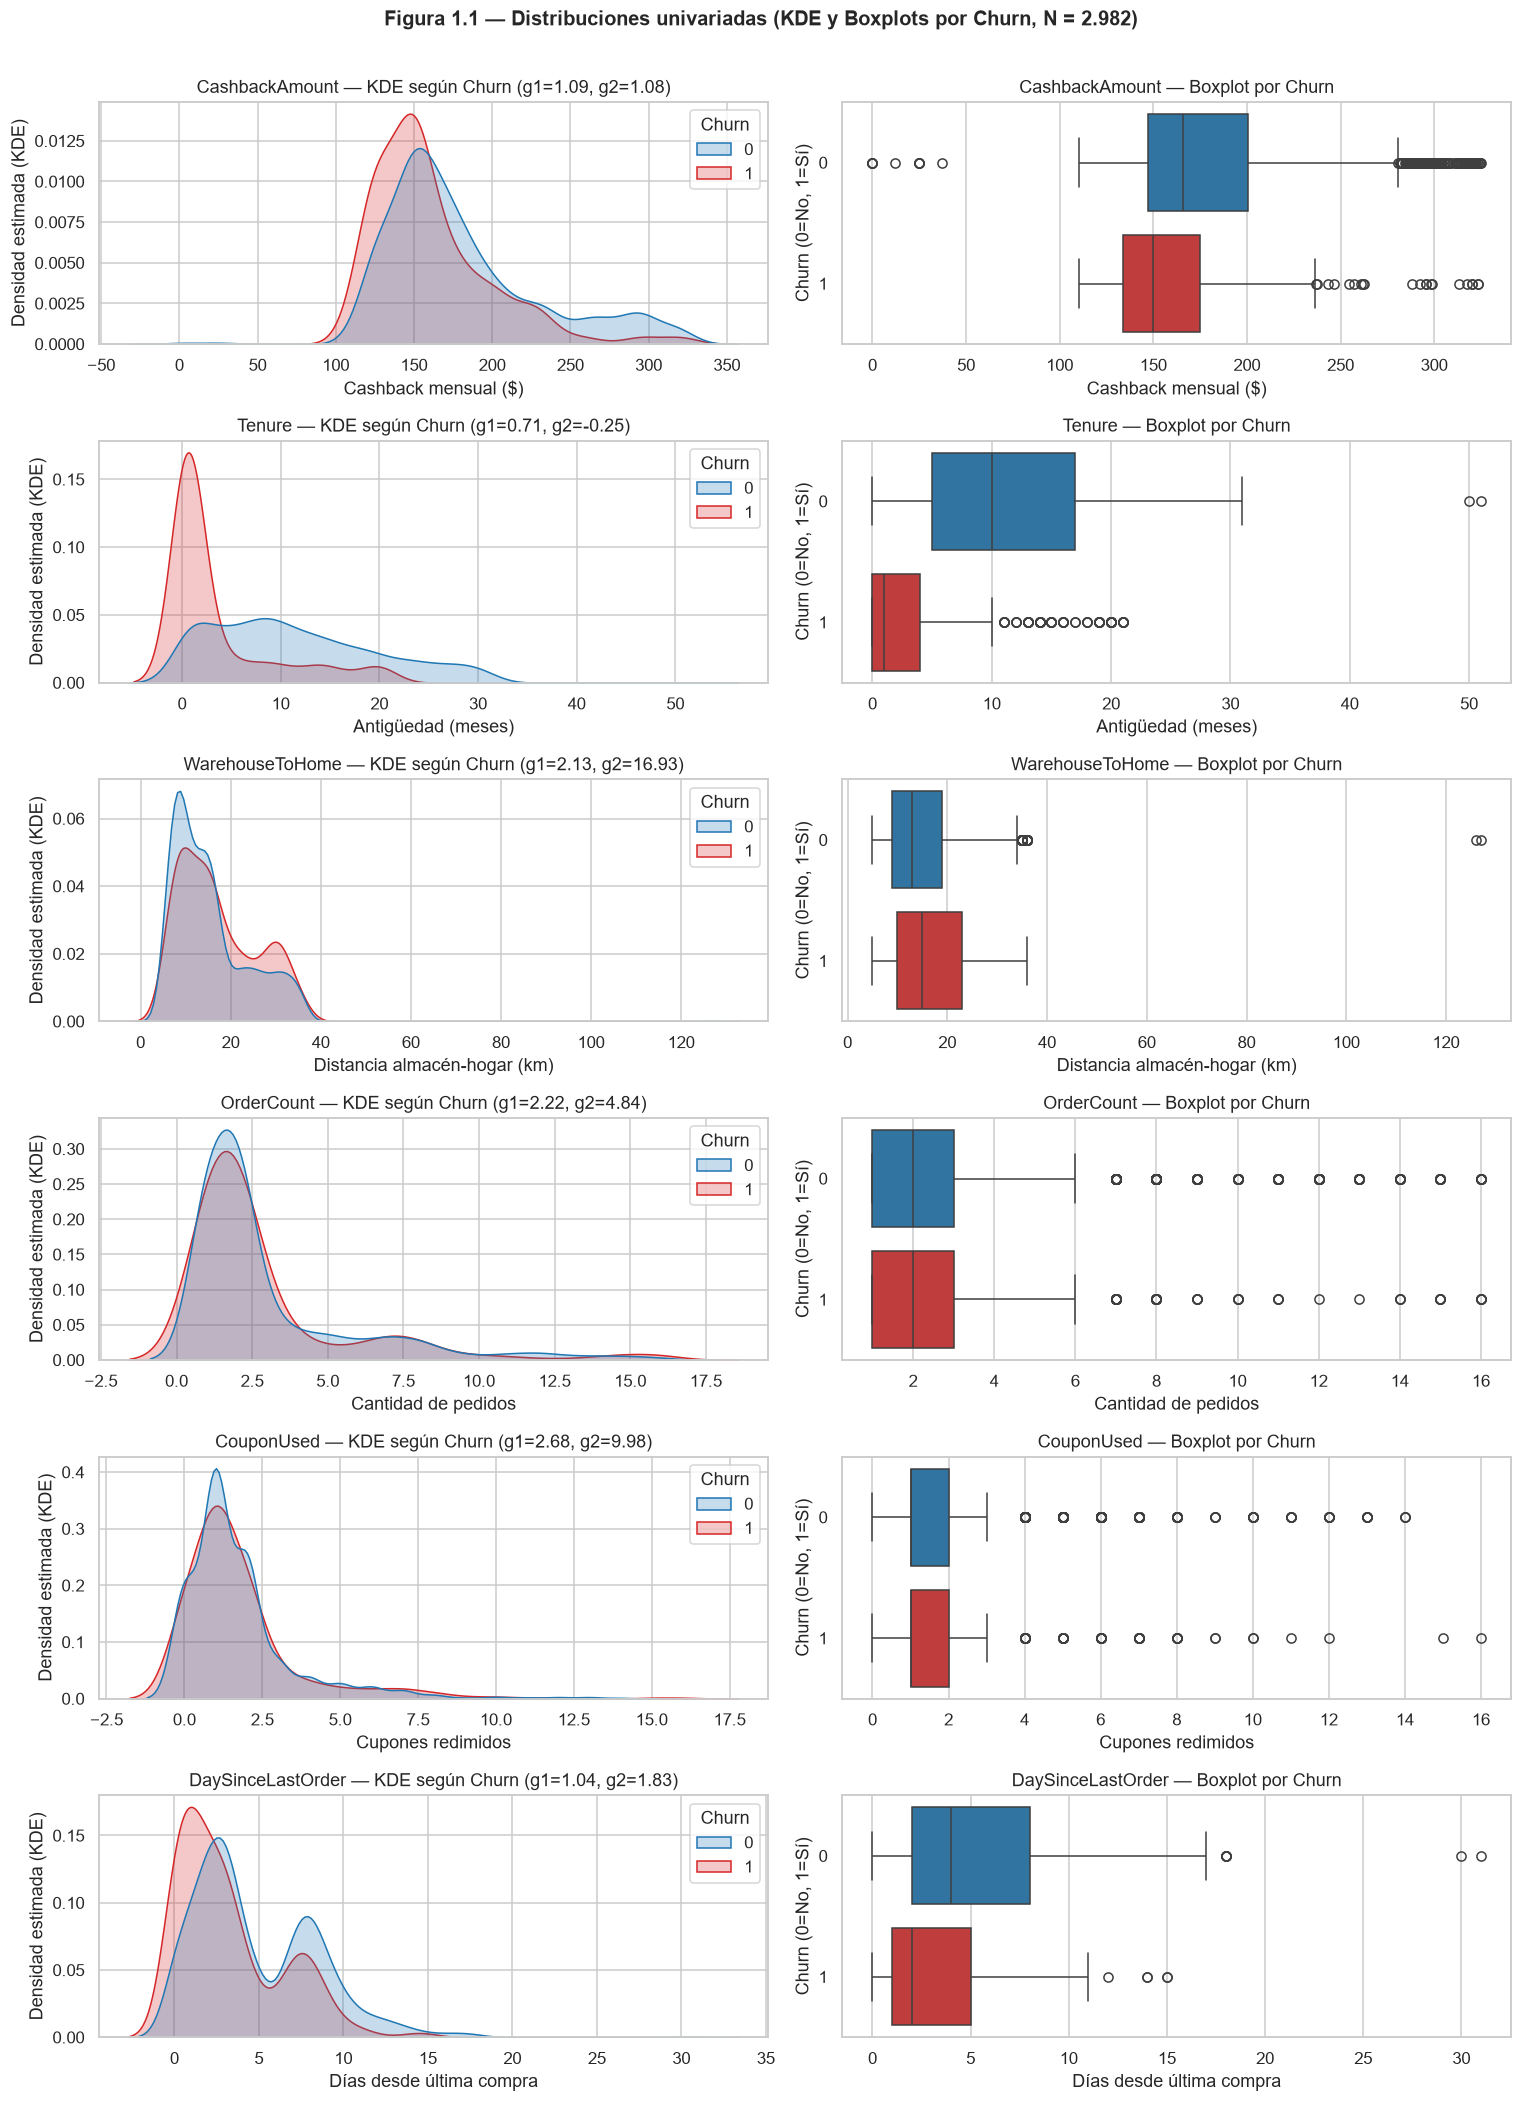

In [2]:
univ_rows = []
for col in NUMERIC_COLS:
    nd = normality_diagnostics(df[col], alpha=ALPHA)
    univ_rows.append(
        {
            "variable": col,
            "n_obs": nd["n"],
            "n_na": int(df[col].isna().sum()),
            "media": nd["mean"],
            "de": nd["std"],
            "mediana": nd["median"],
            "iqr": nd["iqr"],
            "asimetria_g1": nd["skewness"],
            "curtosis_exc_g2": nd["kurtosis_excess"],
            "shapiro_p_info": nd["shapiro_p"],
            "forma_aceptable": nd["is_acceptable_shape"],
        }
    )

univ_table = pd.DataFrame(univ_rows)
print("Tabla 1.1 — Diagnóstico univariado de variables cuantitativas (src.inference.normality_diagnostics, N=2.982):")
show_table_with_pvals(univ_table, ["shapiro_p_info"])

key_vars = [
    ("CashbackAmount", "Cashback mensual ($)"),
    ("Tenure", "Antigüedad (meses)"),
    ("WarehouseToHome", "Distancia almacén-hogar (km)"),
    ("OrderCount", "Cantidad de pedidos"),
    ("CouponUsed", "Cupones redimidos"),
    ("DaySinceLastOrder", "Días desde última compra"),
]

fig, axes = plt.subplots(6, 2, figsize=(14, 19))
for row_idx, (col, xlabel) in enumerate(key_vars):
    sub = df[[col, TARGET_COL]].dropna()
    g1_val = float(univ_table.loc[univ_table["variable"] == col, "asimetria_g1"].iloc[0])
    g2_val = float(univ_table.loc[univ_table["variable"] == col, "curtosis_exc_g2"].iloc[0])

    ax_kde = axes[row_idx, 0]
    sns.kdeplot(
        data=sub,
        x=col,
        hue=TARGET_COL,
        common_norm=False,
        fill=True,
        alpha=0.25,
        palette={0: "#1f77b4", 1: "#d62728"},
        ax=ax_kde,
    )
    ax_kde.set_title(f"{col} — KDE según Churn (g1={g1_val:.2f}, g2={g2_val:.2f})")
    ax_kde.set_xlabel(xlabel)
    ax_kde.set_ylabel("Densidad estimada (KDE)")
    leg = ax_kde.get_legend()
    if leg is not None:
        leg.set_title("Churn")

    ax_box = axes[row_idx, 1]
    sub_box = sub.assign(_churn_str=sub[TARGET_COL].astype(str))
    sns.boxplot(
        data=sub_box,
        x=col,
        y="_churn_str",
        order=["0", "1"],
        hue="_churn_str",
        palette={"0": "#1f77b4", "1": "#d62728"},
        legend=False,
        ax=ax_box,
    )
    ax_box.set_title(f"{col} — Boxplot por Churn")
    ax_box.set_xlabel(xlabel)
    ax_box.set_ylabel("Churn (0=No, 1=Sí)")

fig.suptitle("Figura 1.1 — Distribuciones univariadas (KDE y Boxplots por Churn, N = 2.982)", y=1.005, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


**Lectura de la Tabla 1.1 y Figura 1.1:** como se observa en los estadísticos muestrales y en los paneles KDE + boxplot, las variables transaccionales y de fricción logística (`CouponUsed`, `OrderCount`, `WarehouseToHome`, `DaySinceLastOrder` y `CashbackAmount`) presentan asimetría y colas extensas, mientras que los clientes con `Churn=1` se concentran en menor antigüedad (`Tenure`) y menor nivel de `CashbackAmount`.

A continuación contrastamos las matrices de correlación de **Pearson ($r$)** y **Spearman ($\rho_s$)** junto con las tasas de abandono por categorías clave (`PreferedOrderCat`, `CityTier`, `Complain`, `MaritalStatus`).


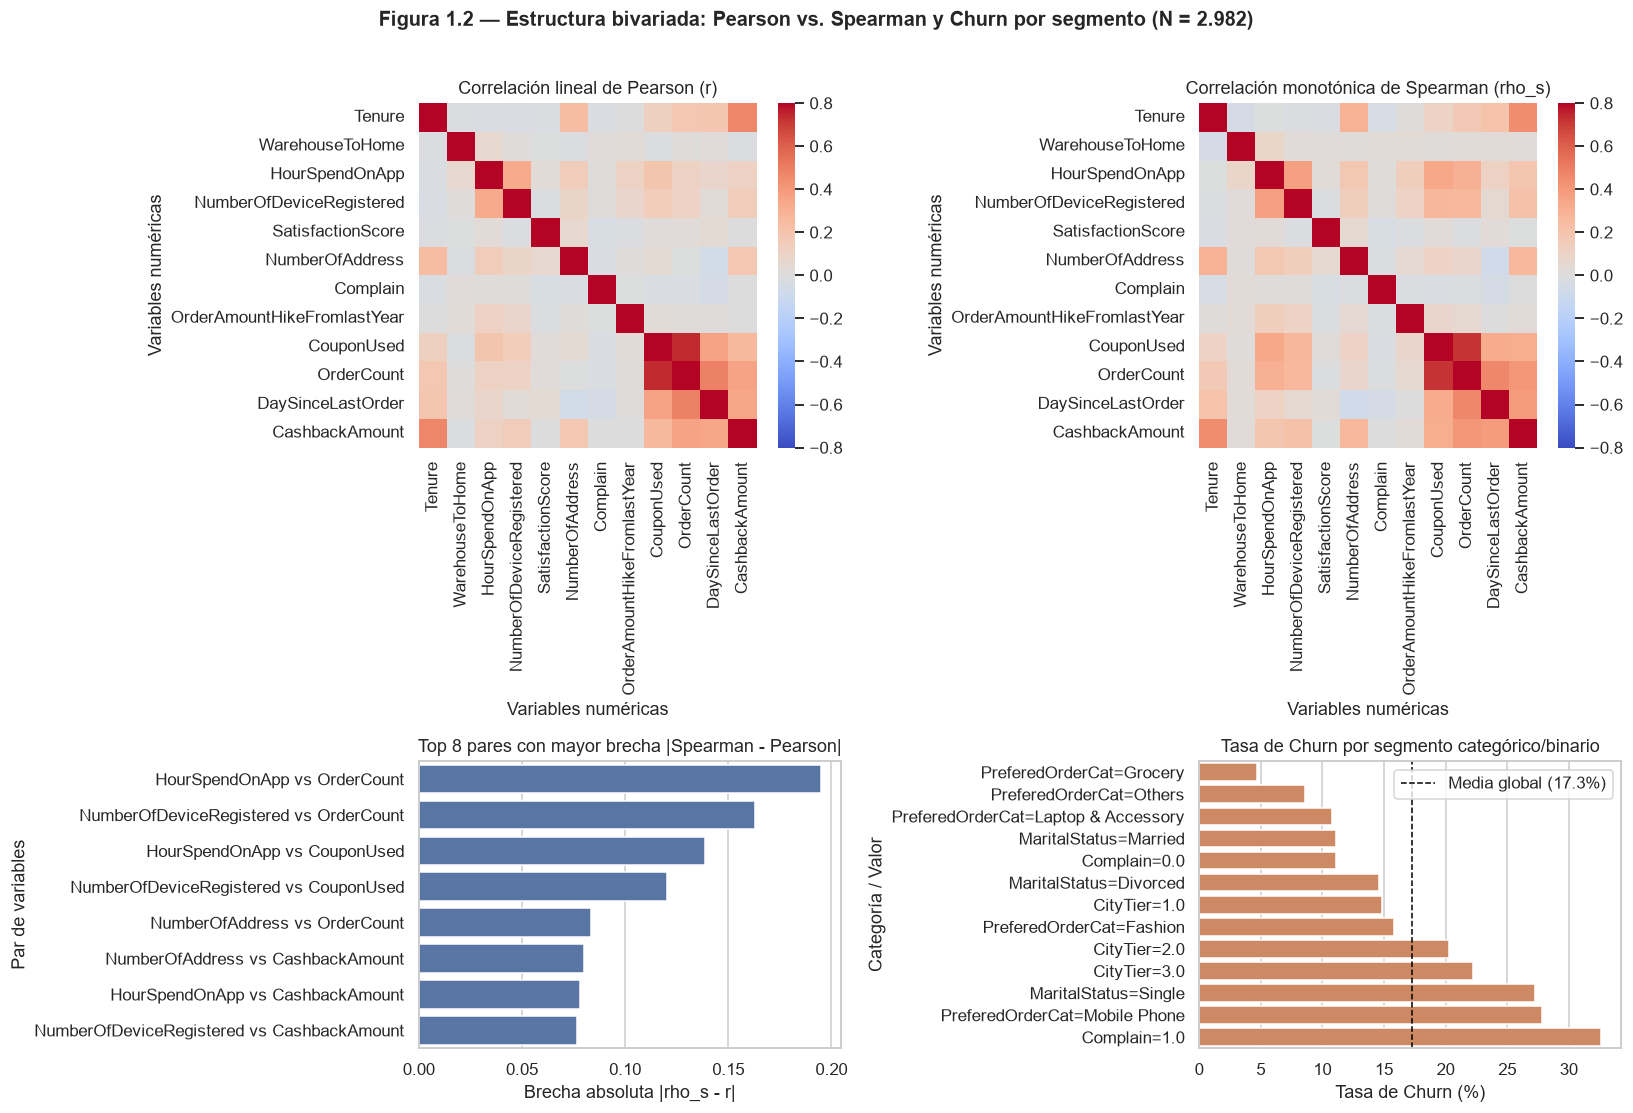

Ejemplo clave en mediadores/tratamiento: OrderCount vs CouponUsed -> Pearson r=0.741, Spearman rho_s=0.724.


In [3]:
corr_pearson = df[NUMERIC_COLS].corr(method="pearson")
corr_spearman = df[NUMERIC_COLS].corr(method="spearman")
corr_diff = (corr_spearman - corr_pearson).abs()

fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1.0])

ax0 = fig.add_subplot(gs[0, 0])
sns.heatmap(corr_pearson, cmap="coolwarm", center=0, vmin=-0.8, vmax=0.8, annot=False, ax=ax0)
ax0.set_title("Correlación lineal de Pearson (r)")
ax0.set_xlabel("Variables numéricas")
ax0.set_ylabel("Variables numéricas")

ax1 = fig.add_subplot(gs[0, 1])
sns.heatmap(corr_spearman, cmap="coolwarm", center=0, vmin=-0.8, vmax=0.8, annot=False, ax=ax1)
ax1.set_title("Correlación monotónica de Spearman (rho_s)")
ax1.set_xlabel("Variables numéricas")
ax1.set_ylabel("Variables numéricas")

ax2 = fig.add_subplot(gs[1, 0])
top_pairs = (
    corr_diff.where(np.triu(np.ones(corr_diff.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
    .head(8)
)
pair_labels = [f"{a} vs {b}" for a, b in top_pairs.index]
sns.barplot(x=top_pairs.values, y=pair_labels, color="#4c72b0", ax=ax2)
ax2.set_title("Top 8 pares con mayor brecha |Spearman - Pearson|")
ax2.set_xlabel("Brecha absoluta |rho_s - r|")
ax2.set_ylabel("Par de variables")

ax3 = fig.add_subplot(gs[1, 1])
cat_rates = []
for col in ["Complain", "CityTier", "PreferedOrderCat", "MaritalStatus"]:
    grp = df.groupby(col, observed=True)[TARGET_COL].agg(["mean", "count"]).reset_index()
    for _, row in grp.iterrows():
        cat_rates.append({"segmento": f"{col}={row[col]}", "churn_pct": float(row["mean"] * 100.0)})
cat_rates_df = pd.DataFrame(cat_rates).sort_values("churn_pct", ascending=True)
sns.barplot(data=cat_rates_df, x="churn_pct", y="segmento", color="#dd8452", ax=ax3)
ax3.axvline(df[TARGET_COL].mean() * 100.0, color="black", linestyle="--", linewidth=1, label=f"Media global ({df[TARGET_COL].mean()*100:.1f}%)")
ax3.set_title("Tasa de Churn por segmento categórico/binario")
ax3.set_xlabel("Tasa de Churn (%)")
ax3.set_ylabel("Categoría / Valor")
ax3.legend()

fig.suptitle("Figura 1.2 — Estructura bivariada: Pearson vs. Spearman y Churn por segmento (N = 2.982)", y=1.01, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(
    f"Ejemplo clave en mediadores/tratamiento: OrderCount vs CouponUsed -> "
    f"Pearson r={corr_pearson.loc['OrderCount', 'CouponUsed']:.3f}, "
    f"Spearman rho_s={corr_spearman.loc['OrderCount', 'CouponUsed']:.3f}."
)


### 1.2 Auditoría del mecanismo de datos faltantes (MCAR / MAR / MNAR)

**Marco teórico previo al código (Rubin, 1976; Little, 1988):**  
Sea $R \in \{0, 1\}^{n \times p}$ la matriz indicadora de valores faltantes ($R_{ij} = 1$ si $X_{ij}$ es NA). Contrastamos tres mecanismos posibles:

* **MCAR (*Missing Completely at Random*):** $P(R \mid X_{\text{obs}}, X_{\text{mis}}) = P(R)$. Se evalúa globalmente mediante el estadístico multivariado de **Little (1988)** bajo estimación por algoritmo EM:
  $$d^2 = \sum_{g=1}^{G} n_g \left(\bar{\mathbf{x}}_{\text{obs}, g} - \hat{\boldsymbol{\mu}}_{\text{obs}, g}\right)^\top \hat{\boldsymbol{\Sigma}}_{\text{obs}, g}^{-1} \left(\bar{\mathbf{x}}_{\text{obs}, g} - \hat{\boldsymbol{\mu}}_{\text{obs}, g}\right) \;\sim\; \chi^2_{\text{gl}}, \qquad \text{gl} = \sum_{g=1}^{G} p_{\text{obs}, g} - p.$$
  La hipótesis nula evaluada es $H_0$: los datos faltantes son compatibles con MCAR.
* **MAR (*Missing at Random*):** $P(R \mid X_{\text{obs}}, X_{\text{mis}}) = P(R \mid X_{\text{obs}})$. Modelamos una regresión logística para cada indicador $R_j$ en función de las covariables completamente observadas, midiendo el test de razón de verosimilitud ($p_{\text{LRT}}$) y el poder discriminativo fuera de muestra (`ROC-AUC` con `StratifiedKFold(5)`), más $\chi^2$ y $V$ de Cramér contra `Churn`.
* **MNAR (*Missing Not at Random*):** no es verificable únicamente desde los datos observados porque depende del valor no observado (por ejemplo, clientes recién dados de alta con `Tenure` faltante o usuarios sin registro de compra reciente en `DaySinceLastOrder`). Por ello implementamos imputación + indicador binario de faltante dentro de `Pipeline` (ajustado solo en `Train`), preservando además los `133` NA de `coupon_any` sin imputar para la decisión causal de Fase 4.


Test global MCAR de Little (1988): d^2 = 2875.89, gl = 77, p = < 1e-300, patrones = 8 -> Se rechaza H0 (no es MCAR)
Tabla 1.2 — Auditoría de mecanismo de faltantes por variable (src.preprocessing.missingness_report, N=2.982):


,column,n_missing,pct_missing,chi2_target,p_chi2_target,cramers_v_target,mar_logit_p_lrt,mar_logit_auc,mechanism
0,DaySinceLastOrder,162,5.4326,0.0427,8.36e-01,0.0038,8.41e-98,0.9243,MAR (posible componente MNAR por dominio)
1,Tenure,142,4.7619,23.7279,1.11e-06,0.0892,7.25e-90,0.9542,MAR (posible componente MNAR por dominio)
2,HourSpendOnApp,140,4.6948,3.1658,7.52e-02,0.0326,2.22e-64,0.8978,MAR (posible componente MNAR por dominio)
3,OrderAmountHikeFromlastYear,140,4.6948,12.1412,4.93e-04,0.0638,2.25e-189,0.9959,MAR (posible componente MNAR por dominio)
4,OrderCount,137,4.5942,11.5633,6.73e-04,0.0623,7.06e-93,0.9402,MAR (posible componente MNAR por dominio)
5,CouponUsed,133,4.4601,19.8832,8.23e-06,0.0817,9.35e-117,0.9652,MAR (posible componente MNAR por dominio)
6,coupon_any,133,4.4601,19.8832,8.23e-06,0.0817,9.35e-117,0.9652,MAR (posible componente MNAR por dominio)
7,WarehouseToHome,131,4.3930,20.8528,4.96e-06,0.0836,1.54e-69,0.9188,MAR (posible componente MNAR por dominio)
8,CashbackAmount,0,0.0000,NaN,NaN,NaN,NaN,NaN,Completo (0% NA)
9,Churn,0,0.0000,NaN,NaN,NaN,NaN,NaN,Completo (0% NA)


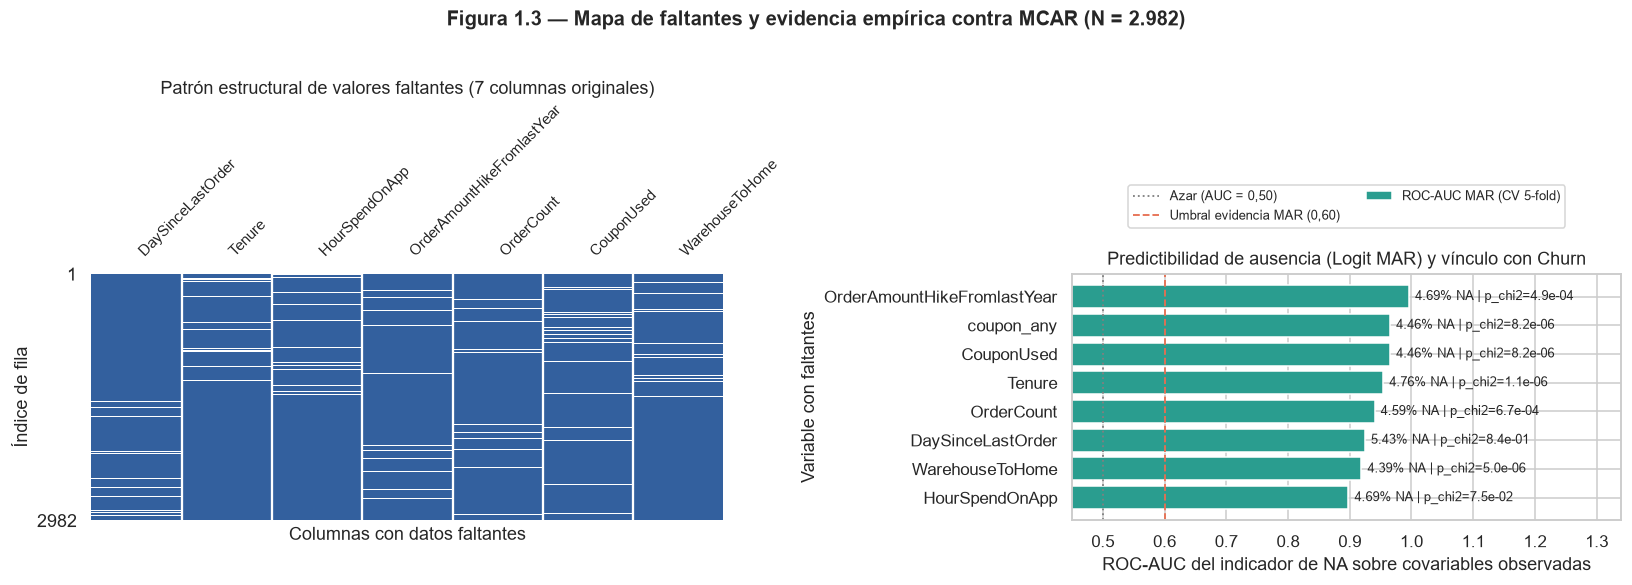

In [4]:
miss_rep = missingness_report(df, target=TARGET_COL, alpha=ALPHA)
little = miss_rep.attrs["little_mcar"]

p_little_str = "< 1e-300" if little["p_value"] == 0.0 else f"{little['p_value']:.2e}"
print(
    f"Test global MCAR de Little (1988): d^2 = {little['stat']:.2f}, gl = {little['df']}, "
    f"p = {p_little_str}, patrones = {little['n_patterns']} -> {little['decision']}"
)
print("Tabla 1.2 — Auditoría de mecanismo de faltantes por variable (src.preprocessing.missingness_report, N=2.982):")
show_table_with_pvals(
    miss_rep[
        [
            "column",
            "n_missing",
            "pct_missing",
            "chi2_target",
            "p_chi2_target",
            "cramers_v_target",
            "mar_logit_p_lrt",
            "mar_logit_auc",
            "mechanism",
        ]
    ],
    ["p_chi2_target", "mar_logit_p_lrt"],
)

na_cols_rep = miss_rep[miss_rep["n_missing"] > 0].copy()
na_orig_cols = [c for c in na_cols_rep["column"] if c != TREATMENT_COL]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.15, 1.0]})
msno.matrix(df[na_orig_cols], ax=axes[0], sparkline=False, fontsize=10, color=(0.20, 0.38, 0.62))
axes[0].set_title("Patrón estructural de valores faltantes (7 columnas originales)")
axes[0].set_xlabel("Columnas con datos faltantes")
axes[0].set_ylabel("Índice de fila")

plot_mar = na_cols_rep.sort_values("mar_logit_auc", ascending=True)
bars = axes[1].barh(plot_mar["column"], plot_mar["mar_logit_auc"], color="#2a9d8f", label="ROC-AUC MAR (CV 5-fold)")
axes[1].axvline(0.50, color="gray", linestyle=":", linewidth=1.2, label="Azar (AUC = 0,50)")
axes[1].axvline(0.60, color="#e76f51", linestyle="--", linewidth=1.2, label="Umbral evidencia MAR (0,60)")
for bar, pct, p_c in zip(bars, plot_mar["pct_missing"], plot_mar["p_chi2_target"], strict=True):
    axes[1].text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.2f}% NA | p_chi2={p_c:.1e}",
        va="center",
        fontsize=8.5,
    )
axes[1].set_xlim(0.45, 1.34)
axes[1].set_title("Predictibilidad de ausencia (Logit MAR) y vínculo con Churn")
axes[1].set_xlabel("ROC-AUC del indicador de NA sobre covariables observadas")
axes[1].set_ylabel("Variable con faltantes")
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, 1.16), ncol=2, fontsize=8.5)

fig.suptitle("Figura 1.3 — Mapa de faltantes y evidencia empírica contra MCAR (N = 2.982)", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


**Lectura de la Tabla 1.2 y Figura 1.3:** las `7` columnas originales con faltantes oscilan entre `4,39%` (`WarehouseToHome`) y `5,43%` (`DaySinceLastOrder`). **Se rechaza $H_0$ de MCAR** en el test de Little ($d^2 = 2875{,}89$, $\text{gl} = 77$, $p < 10^{-300}$, $8$ patrones): la ausencia es altamente predecible desde las covariables observadas (`ROC-AUC` entre `0,8978` y `0,9959`, $p_{\text{LRT}} \le 2{,}22 \times 10^{-64}$) y exhibe asociación significativa con `Churn` en `5/7` variables ($p \le 6{,}73 \times 10^{-4}$). En consecuencia, **no es válido eliminar filas por lista** y la remediación elegida (imputación condicional + indicador binario dentro de `Pipeline`, ajustado solo en `Train`) preserva la señal informativa de ausencia sin generar *leakage*.

---

### 1.3 Contrastes de hipótesis formales y análisis de potencia estadística ($1 - \beta$)

**Marco teórico previo al código:**  
Con $N = 2.982$, cualquier diferencia mínima puede arrojar $p < 0{,}05$; por ello acompañamos el p-valor exacto con intervalos de confianza al 95%, tamaños de efecto estandarizados y potencia estadística. Recordamos el principio inferencial estricto: la evidencia muestral permite afirmar que **Se rechaza $H_0$** o **No se rechaza $H_0$** (nunca se afirma "aceptar $H_0$").

1. **Contraste 1 (`CashbackAmount` según `Churn`):**
   $$H_0: \mu_{\text{Cashback}}^{\text{Churn}=1} = \mu_{\text{Cashback}}^{\text{Churn}=0} \qquad \text{vs.} \qquad H_1: \mu_{\text{Cashback}}^{\text{Churn}=1} \neq \mu_{\text{Cashback}}^{\text{Churn}=0}.$$
   Utilizamos el test **$t$ de Welch** (robusto ante varianzas desiguales), **U de Mann-Whitney** como verificación no paramétrica frente a asimetría ($g_1 = 1{,}21$), intervalo de confianza analítico y por **bootstrap de 5.000 réplicas**, y la magnitud estandarizada **$d$ de Cohen** con desvío agrupado (*pooled*):
   $$t_W = \frac{\bar{X}_1 - \bar{X}_0}{\sqrt{s_1^2/n_1 + s_0^2/n_0}}, \qquad d = \frac{\bar{X}_1 - \bar{X}_0}{s_{\text{pooled}}}, \qquad s_{\text{pooled}} = \sqrt{\frac{(n_1-1)s_1^2 + (n_0-1)s_0^2}{n_1 + n_0 - 2}}.$$

2. **Contraste 2 (`Complain` vs. `Churn`):**
   $$H_0: P(\text{Churn}=1 \mid \text{Complain}=1) = P(\text{Churn}=1 \mid \text{Complain}=0) \qquad \text{vs.} \qquad H_1: p_1 \neq p_0.$$
   Calculamos $\chi^2$ de Pearson de independencia, **$V$ de Cramér** ($V = \sqrt{\chi^2 / (N \cdot (\min(r,c)-1))}$), diferencia de proporciones con IC 95% de Wald y **Odds Ratio (OR)**.

3. **Análisis de potencia (`TTestIndPower`):** evaluamos la potencia alcanzada $1 - \beta$ para el tamaño de efecto observado y el **efecto mínimo detectable ($\text{MDE}_{80\%}$)** al 80% de potencia con $\alpha = 0{,}05$ dados $n_1 = 516$ y $n_0 = 2.466$.


Tabla 1.3 — Contrastes formales de hipótesis, tamaños de efecto y potencia (src.inference):


,contraste,muestra,estimacion,ic_95,estadistico_principal,p_valor_exacto,magnitud_y_potencia,decision
0,C1: CashbackAmount (Churn=1 vs Churn=0) [N=2.982],"n1=516, n0=2466",diff = $-19.36 ($160.77 vs $180.12),[-23.27; -15.44] (boot [-23.32; -15.44]),Welch t = -9.71 (gl=923.66),2.85e-21 | MW p=4.34e-20,d = -0.3955 (pequeño); 1-beta=1.0000; MDE=0.1357,Se rechaza H0
1,C1 verificación en Train [N=2.385],"n1=413, n0=1972",diff = $-19.86 ($160.42 vs $180.28),[-24.10; -15.62],Welch t = -9.20 (gl=776.39),3.24e-19 | MW p=4.82e-16,d = -0.4062 (pequeño); 1-beta=1.0000; MDE=0.1517,Se rechaza H0
2,C2: Complain vs Churn [N=2.982],N=2982,diff = +21.52 pp (32.63% vs 11.11%),[+18.11; +24.93] pp,chi2 = 197.84 (gl=1),6.19e-45,V de Cramér = 0.2576; OR = 3.88,Se rechaza H0
3,C2 verificación en Train [N=2.385],N=2385,diff = +23.43 pp (34.01% vs 10.59%),[+19.59; +27.26] pp,chi2 = 187.15 (gl=1),1.33e-42,V de Cramér = 0.2801; OR = 4.35,Se rechaza H0


Tabla de contingencia Complain x Churn (N=2.982):


Churn,0,1
Complain,,
0,1888,236
1,578,280


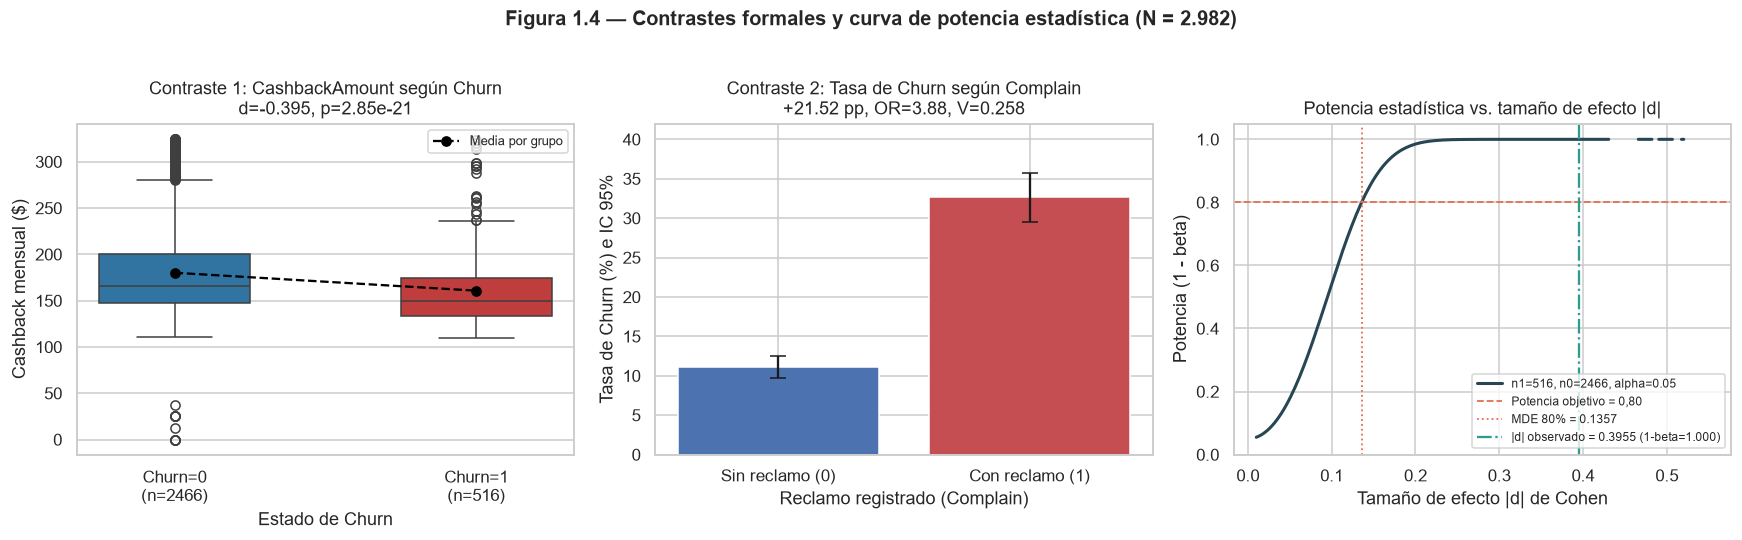

In [5]:
cb_churn1 = df.loc[df[TARGET_COL] == 1, "CashbackAmount"]
cb_churn0 = df.loc[df[TARGET_COL] == 0, "CashbackAmount"]
c1_full = two_sample_test(cb_churn1, cb_churn0, alpha=ALPHA, n_boot=5000)
c1_train = two_sample_test(
    train_df.loc[train_df[TARGET_COL] == 1, "CashbackAmount"],
    train_df.loc[train_df[TARGET_COL] == 0, "CashbackAmount"],
    alpha=ALPHA,
    n_boot=5000,
)

c2_full = chi2_independence(df, "Complain", TARGET_COL, alpha=ALPHA)
c2_train = chi2_independence(train_df, "Complain", TARGET_COL, alpha=ALPHA)

contrastes_table = pd.DataFrame(
    [
        {
            "contraste": "C1: CashbackAmount (Churn=1 vs Churn=0) [N=2.982]",
            "muestra": f"n1={c1_full['n_x']}, n0={c1_full['n_y']}",
            "estimacion": f"diff = ${c1_full['diff_means']:.2f} (${c1_full['mean_x']:.2f} vs ${c1_full['mean_y']:.2f})",
            "ic_95": f"[{c1_full['ci_low']:.2f}; {c1_full['ci_high']:.2f}] (boot [{c1_full['boot_ci_low']:.2f}; {c1_full['boot_ci_high']:.2f}])",
            "estadistico_principal": f"Welch t = {c1_full['t_stat']:.2f} (gl={c1_full['df_welch']:.2f})",
            "p_valor_exacto": f"{c1_full['p_value']:.2e} | MW p={c1_full['p_mannwhitney']:.2e}",
            "magnitud_y_potencia": f"d = {c1_full['cohens_d']:.4f} ({c1_full['effect_magnitude']}); 1-beta={c1_full['power_observed']:.4f}; MDE={c1_full['mde_d_80']:.4f}",
            "decision": c1_full["decision"],
        },
        {
            "contraste": "C1 verificación en Train [N=2.385]",
            "muestra": f"n1={c1_train['n_x']}, n0={c1_train['n_y']}",
            "estimacion": f"diff = ${c1_train['diff_means']:.2f} (${c1_train['mean_x']:.2f} vs ${c1_train['mean_y']:.2f})",
            "ic_95": f"[{c1_train['ci_low']:.2f}; {c1_train['ci_high']:.2f}]",
            "estadistico_principal": f"Welch t = {c1_train['t_stat']:.2f} (gl={c1_train['df_welch']:.2f})",
            "p_valor_exacto": f"{c1_train['p_value']:.2e} | MW p={c1_train['p_mannwhitney']:.2e}",
            "magnitud_y_potencia": f"d = {c1_train['cohens_d']:.4f} ({c1_train['effect_magnitude']}); 1-beta={c1_train['power_observed']:.4f}; MDE={c1_train['mde_d_80']:.4f}",
            "decision": c1_train["decision"],
        },
        {
            "contraste": "C2: Complain vs Churn [N=2.982]",
            "muestra": f"N={c2_full['n']}",
            "estimacion": f"diff = {c2_full['diff_proportions']*100:+.2f} pp ({c2_full['prop_1']*100:.2f}% vs {c2_full['prop_0']*100:.2f}%)",
            "ic_95": f"[{c2_full['prop_ci_low']*100:+.2f}; {c2_full['prop_ci_high']*100:+.2f}] pp",
            "estadistico_principal": f"chi2 = {c2_full['chi2']:.2f} (gl={c2_full['dof']})",
            "p_valor_exacto": f"{c2_full['p_value']:.2e}",
            "magnitud_y_potencia": f"V de Cramér = {c2_full['cramers_v']:.4f}; OR = {c2_full['odds_ratio']:.2f}",
            "decision": c2_full["decision"],
        },
        {
            "contraste": "C2 verificación en Train [N=2.385]",
            "muestra": f"N={c2_train['n']}",
            "estimacion": f"diff = {c2_train['diff_proportions']*100:+.2f} pp ({c2_train['prop_1']*100:.2f}% vs {c2_train['prop_0']*100:.2f}%)",
            "ic_95": f"[{c2_train['prop_ci_low']*100:+.2f}; {c2_train['prop_ci_high']*100:+.2f}] pp",
            "estadistico_principal": f"chi2 = {c2_train['chi2']:.2f} (gl={c2_train['dof']})",
            "p_valor_exacto": f"{c2_train['p_value']:.2e}",
            "magnitud_y_potencia": f"V de Cramér = {c2_train['cramers_v']:.4f}; OR = {c2_train['odds_ratio']:.2f}",
            "decision": c2_train["decision"],
        },
    ]
)

print("Tabla 1.3 — Contrastes formales de hipótesis, tamaños de efecto y potencia (src.inference):")
display(contrastes_table)
print("Tabla de contingencia Complain x Churn (N=2.982):")
display(c2_full["contingency_table"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: CashbackAmount según Churn
sns.boxplot(data=df, x=TARGET_COL, y="CashbackAmount", hue=TARGET_COL, palette={0: "#1f77b4", 1: "#d62728"}, legend=False, width=0.5, ax=axes[0])
axes[0].plot([0, 1], [c1_full["mean_y"], c1_full["mean_x"]], "o--", color="black", label="Media por grupo")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels([f"Churn=0\n(n={c1_full['n_y']})", f"Churn=1\n(n={c1_full['n_x']})"])
axes[0].set_title(f"Contraste 1: CashbackAmount según Churn\nd={c1_full['cohens_d']:.3f}, p={c1_full['p_value']:.2e}")
axes[0].set_xlabel("Estado de Churn")
axes[0].set_ylabel("Cashback mensual ($)")
axes[0].legend(loc="upper right", fontsize=8.5)

# Panel B: Tasa de Churn según Complain
rates = [c2_full["prop_0"] * 100.0, c2_full["prop_1"] * 100.0]
se_0 = np.sqrt(c2_full["prop_0"] * (1 - c2_full["prop_0"]) / int(c2_full["contingency_table"].iloc[0].sum())) * 100.0
se_1 = np.sqrt(c2_full["prop_1"] * (1 - c2_full["prop_1"]) / int(c2_full["contingency_table"].iloc[1].sum())) * 100.0
axes[1].bar(["Sin reclamo (0)", "Con reclamo (1)"], rates, yerr=[1.96 * se_0, 1.96 * se_1], capsize=5, color=["#4c72b0", "#c44e52"])
axes[1].set_title(f"Contraste 2: Tasa de Churn según Complain\n+{c2_full['diff_proportions']*100:.2f} pp, OR={c2_full['odds_ratio']:.2f}, V={c2_full['cramers_v']:.3f}")
axes[1].set_xlabel("Reclamo registrado (Complain)")
axes[1].set_ylabel("Tasa de Churn (%) e IC 95%")
axes[1].set_ylim(0, 42)

# Panel C: Curva de potencia TTestIndPower
d_grid = np.linspace(0.01, 0.55, 200)
pwr = TTestIndPower()
ratio = c1_full["n_y"] / c1_full["n_x"]
powers = [pwr.power(effect_size=d_val, nobs1=c1_full["n_x"], ratio=ratio, alpha=ALPHA, alternative="two-sided") for d_val in d_grid]
axes[2].plot(d_grid, powers, color="#264653", linewidth=2, label=f"n1={c1_full['n_x']}, n0={c1_full['n_y']}, alpha={ALPHA}")
axes[2].axhline(0.80, color="#e76f51", linestyle="--", linewidth=1.2, label="Potencia objetivo = 0,80")
axes[2].axvline(c1_full["mde_d_80"], color="#e76f51", linestyle=":", linewidth=1.2, label=f"MDE 80% = {c1_full['mde_d_80']:.4f}")
axes[2].axvline(abs(c1_full["cohens_d"]), color="#2a9d8f", linestyle="-.", linewidth=1.5, label=f"|d| observado = {abs(c1_full['cohens_d']):.4f} (1-beta={c1_full['power_observed']:.3f})")
axes[2].set_title("Potencia estadística vs. tamaño de efecto |d|")
axes[2].set_xlabel("Tamaño de efecto |d| de Cohen")
axes[2].set_ylabel("Potencia (1 - beta)")
axes[2].set_ylim(0, 1.05)
axes[2].legend(loc="lower right", fontsize=8)

fig.suptitle("Figura 1.4 — Contrastes formales y curva de potencia estadística (N = 2.982)", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


**Lectura de la Tabla 1.3 y Figura 1.4:**  
En el **Contraste 1**, quienes hacen *churn* perciben en promedio **\$19,36 menos** de *cashback* (`$160,77` vs. `$180,12`; IC 95% analítico `[−23,27; −15,44]`, bootstrap `[−23,32; −15,44]`), diferencia respaldada tanto por Welch ($t = -9{,}71, p = 2{,}85 \times 10^{-21}$) como por Mann-Whitney ($p = 4{,}34 \times 10^{-20}$), con efecto pequeño ($d = -0{,}3955$) pero potencia prácticamente unitaria ($1 - \beta = 1{,}0000$, muy por encima del $\text{MDE}_{80\%} = 0{,}1357$). En el **Contraste 2**, registrar al menos un reclamo triplica la tasa de abandono (`32,63%` vs. `11,11%`, $+21{,}52\text{ pp}$, $\chi^2 = 197{,}84$, $p = 6{,}19 \times 10^{-45}$, $V = 0{,}2576$, $\text{OR} = 3{,}88$). Ambos resultados se mantienen estables en `Train (N = 2.385)`.

---

### 1.4 ANOVA de un factor (`CashbackAmount ~ PreferedOrderCat`), árbol de decisión y comparaciones post-hoc

**Marco teórico previo al código (Welch, 1951; Games & Howell, 1976):**  
Contrastamos si el nivel medio de `CashbackAmount` difiere entre las $k = 5$ categorías de `PreferedOrderCat`:
$$H_0: \mu_1 = \mu_2 = \dots = \mu_5 \qquad \text{vs.} \qquad H_1: \exists\, i \neq j \text{ tal que } \mu_i \neq \mu_j.$$

1. **Verificación de normalidad sin caer en la trampa de Shapiro-Wilk:** con $N = 2.982$, la potencia de Shapiro-Wilk tiende a $1$ y rechaza $H_0$ ante desvíos microscópicos irrelevantes para el Teorema Central del Límite sobre la media. Por eso evaluamos normalidad práctica por grupo mediante **asimetría ($|g_1| \le 1$), curtosis en exceso ($|g_2| \le 2$) y gráficos Q-Q**, reportando Shapiro solo a título ilustrativo.
2. **Homocedasticidad:** aplicamos el test de **Levene centrado en la mediana (Brown-Forsythe)** y verificamos la razón de varianzas ($\hat{\sigma}^2_{\max} / \hat{\sigma}^2_{\min}$).
3. **Árbol de decisión ómnibus y tamaños de efecto:** si falla normalidad práctica por colas/asimetría se prioriza **Kruskal-Wallis ($H$, $\varepsilon^2$)** complementado con **Welch ANOVA ($F_W$, $\eta^2$, $\omega^2$)** frente a heterocedasticidad; el ANOVA clásico de Fisher queda solo como referencia.
4. **Control de FWER y post-hoc:** con $k = 5$ categorías existen $m = \binom{5}{2} = 10$ comparaciones par-a-par; realizar $10$ tests sin ajuste inflaría el error de tipo I familiar a $\text{FWER}_{\text{sin ajuste}} = 1 - (1 - 0{,}05)^{10} = 40{,}13\%$. Comparamos **Games-Howell** (robusto a heterocedasticidad), **Bonferroni** (sobre pares no paramétricos) y **Tukey HSD**.


In [6]:
anova_res = one_way_anova_suite(df, value_col="CashbackAmount", group_col="PreferedOrderCat", alpha=ALPHA)
anova_train = one_way_anova_suite(train_df, value_col="CashbackAmount", group_col="PreferedOrderCat", alpha=ALPHA)

print("Tabla 1.4 — Diagnóstico distribucional por categoría de PreferedOrderCat (N=2.982):")
show_table_with_pvals(anova_res["group_diagnostics"], ["shapiro_p"])

print(
    f"Homocedasticidad — Levene (center='median') = {anova_res['levene_stat']:.2f}, "
    f"p = {anova_res['levene_p']:.2e} ({anova_res['levene_decision']}), "
    f"ratio var_max/var_min = {anova_res['var_ratio']:.2f}"
)
print(
    f"Decisión del árbol ANOVA: {anova_res['recommended_test']} + post-hoc {anova_res['recommended_posthoc']} -> "
    f"{anova_res['rationale']}"
)
print("Tabla 1.5 — Suite ómnibus ANOVA clásico, Welch ANOVA y Kruskal-Wallis (N=2.982):")
show_table_with_pvals(anova_res["summary_table"], ["p_value"])
welch_tr_p = "< 1e-300" if anova_train["welch_p"] == 0.0 else f"{anova_train['welch_p']:.2e}"
krusk_tr_p = "< 1e-300" if anova_train["kruskal_p"] == 0.0 else f"{anova_train['kruskal_p']:.2e}"
print(
    f"Consistencia en Train (N={anova_train['n']}): Levene={anova_train['levene_stat']:.2f} (p={anova_train['levene_p']:.2e}), "
    f"Welch F={anova_train['welch_f']:.2f} (p={welch_tr_p}), "
    f"Kruskal H={anova_train['kruskal_h']:.2f} (p={krusk_tr_p}), "
    f"eta^2={anova_train['eta_sq']:.4f}, omega^2={anova_train['omega_sq']:.4f}."
)

ph_gh = posthoc(df, value_col="CashbackAmount", group_col="PreferedOrderCat", method="games-howell", alpha=ALPHA)
ph_tk = posthoc(df, value_col="CashbackAmount", group_col="PreferedOrderCat", method="tukey", alpha=ALPHA)
ph_bf = posthoc(df, value_col="CashbackAmount", group_col="PreferedOrderCat", method="bonferroni", alpha=ALPHA)

fwer_info = ph_gh.attrs["fwer_info"]
print(
    f"Control FWER (k={fwer_info['n_groups']}, m={fwer_info['n_comparisons']} pares): "
    f"FWER sin ajuste = {fwer_info['fwer_uncorrected']*100:.2f}% -> reducido al nivel nominal alpha={ALPHA}."
)
ph_compare = ph_gh[["A", "B", "mean_A", "mean_B", "diff", "ci_low", "ci_high", "p_adj", "decision"]].rename(
    columns={"p_adj": "p_games_howell", "decision": "dec_games_howell"}
).merge(
    ph_tk[["A", "B", "p_adj"]].rename(columns={"p_adj": "p_tukey_hsd"}), on=["A", "B"]
).merge(
    ph_bf[["A", "B", "p_adj"]].rename(columns={"p_adj": "p_bonferroni_mw"}), on=["A", "B"]
)
print("Tabla 1.6 — Comparaciones múltiples post-hoc par-a-par (Games-Howell, Tukey HSD y Bonferroni):")
show_table_with_pvals(ph_compare, ["p_games_howell", "p_tukey_hsd", "p_bonferroni_mw"])


Tabla 1.4 — Diagnóstico distribucional por categoría de PreferedOrderCat (N=2.982):


,group,n,mean,std,median,iqr,skewness,kurtosis_excess,shapiro_stat,shapiro_p,is_acceptable_shape
0,Fashion,442,210.5488,22.2627,208.3300,31.0400,0.0982,-0.2939,0.9864,3.74e-04,True
1,Grocery,212,265.0575,33.0918,267.8350,31.5825,-4.2650,30.9871,0.6863,1.21e-19,False
2,Laptop & Accessory,1080,166.6122,21.9574,167.0500,27.2550,-1.5259,11.5508,0.8906,5.57e-27,False
3,Mobile Phone,1108,140.1736,15.5698,142.0400,25.0400,-0.9197,7.1987,0.9162,2.79e-24,False
4,Others,140,304.4687,13.5365,302.7000,24.9750,-0.0319,-1.4937,0.9073,8.12e-08,True


Homocedasticidad — Levene (center='median') = 19.28, p = 1.14e-15 (Se rechaza H0), ratio var_max/var_min = 5.98
Decisión del árbol ANOVA: Kruskal-Wallis + post-hoc bonferroni -> Al menos un grupo excede |asimetría|<=1 o |curtosis_exceso|<=2; se prioriza Kruskal-Wallis (y se reporta Welch ANOVA como contraste de medias robusto).
Tabla 1.5 — Suite ómnibus ANOVA clásico, Welch ANOVA y Kruskal-Wallis (N=2.982):


,test,statistic_name,statistic,df1,df2,p_value,effect_size_name,effect_size,decision
0,ANOVA clásico (Fisher),F,"3,554.4441",4.0000,"2,977.0000",< 1e-300,omega_sq,0.8266,Se rechaza H0
1,Welch ANOVA,F_welch,"5,258.3120",4.0000,613.2141,< 1e-300,eta_sq,0.8269,Se rechaza H0
2,Kruskal-Wallis,H,"2,138.3542",4.0000,NaN,< 1e-300,epsilon_sq,0.7169,Se rechaza H0


Consistencia en Train (N=2385): Levene=13.91 (p=3.22e-11), Welch F=4756.12 (p=< 1e-300), Kruskal H=1720.51 (p=< 1e-300), eta^2=0.8389, omega^2=0.8385.


Control FWER (k=5, m=10 pares): FWER sin ajuste = 40.13% -> reducido al nivel nominal alpha=0.05.
Tabla 1.6 — Comparaciones múltiples post-hoc par-a-par (Games-Howell, Tukey HSD y Bonferroni):


,A,B,mean_A,mean_B,diff,ci_low,ci_high,p_games_howell,dec_games_howell,p_tukey_hsd,p_bonferroni_mw
0,Fashion,Grocery,210.5488,265.0575,-54.5087,-61.3892,-47.6283,7.31e-14,Se rechaza H0,2.43e-12,3.67e-78
1,Fashion,Laptop & Accessory,210.5488,166.6122,43.9366,40.5134,47.3597,< 1e-300,Se rechaza H0,2.43e-12,2.82e-152
2,Fashion,Mobile Phone,210.5488,140.1736,70.3752,67.2082,73.5423,6.99e-15,Se rechaza H0,2.43e-12,5.77e-205
3,Fashion,Others,210.5488,304.4687,-93.9199,-98.1922,-89.6475,6.61e-14,Se rechaza H0,2.43e-12,3.21e-70
4,Grocery,Laptop & Accessory,265.0575,166.6122,98.4453,91.9357,104.9549,< 1e-300,Se rechaza H0,2.43e-12,4.73e-112
5,Grocery,Mobile Phone,265.0575,140.1736,124.8840,118.5038,131.2641,< 1e-300,Se rechaza H0,2.43e-12,1.09e-112
6,Grocery,Others,265.0575,304.4687,-39.4112,-46.3940,-32.4284,< 1e-300,Se rechaza H0,2.43e-12,1.73e-38
7,Laptop & Accessory,Mobile Phone,166.6122,140.1736,26.4387,24.2118,28.6655,4.53e-13,Se rechaza H0,2.43e-12,1.83e-184
8,Laptop & Accessory,Others,166.6122,304.4687,-137.8565,-141.4973,-134.2156,< 1e-300,Se rechaza H0,2.43e-12,8.85e-82
9,Mobile Phone,Others,140.1736,304.4687,-164.2951,-167.6994,-160.8909,< 1e-300,Se rechaza H0,2.43e-12,5.13e-82


**Gráficos diagnósticos de ANOVA (`Figura 1.5` y `Figura 1.6`):**  
Construimos primero los gráficos **Q-Q por categoría** usando las coordenadas teóricas y muestrales devueltas por `normality_diagnostics`, y luego la distribución empírica junto con los intervalos de confianza simultáneos del 95% de **Games-Howell** en dólares.


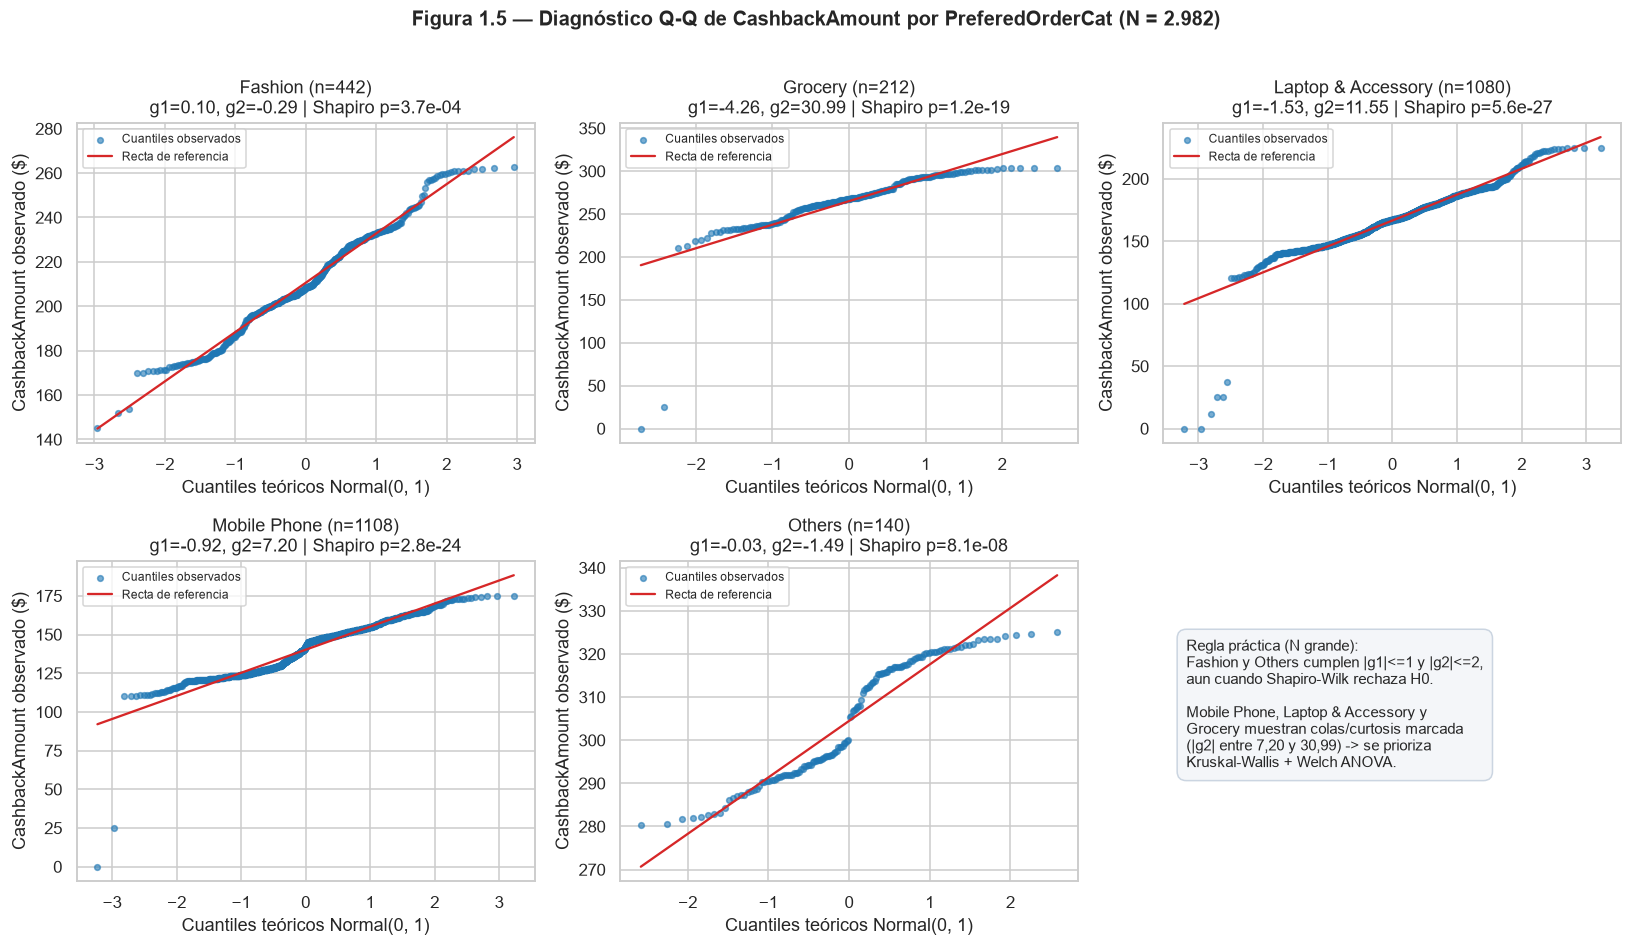

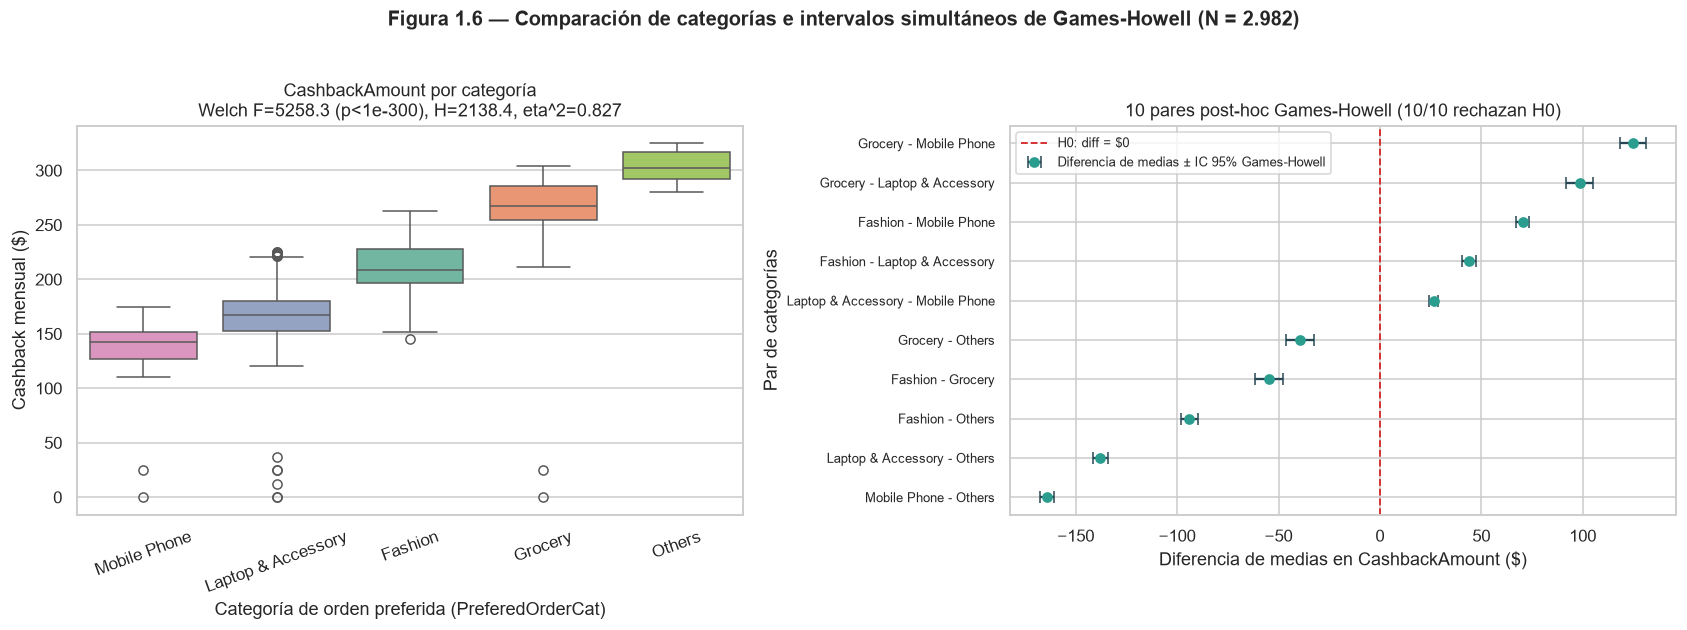

In [7]:
cats_sorted = sorted(df["PreferedOrderCat"].astype(str).unique())

# Figura 1.5: 5 Q-Q plots por categoría
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes_flat = axes.ravel()
for ax, cat in zip(axes_flat, cats_sorted, strict=False):
    vals = df.loc[df["PreferedOrderCat"].astype(str) == cat, "CashbackAmount"]
    nd_cat = normality_diagnostics(vals, alpha=ALPHA)
    tq, sq = nd_cat["qq_theoretical"], nd_cat["qq_sample"]
    ax.scatter(tq, sq, s=14, alpha=0.6, color="#1f77b4", label="Cuantiles observados")
    slope, intercept = np.polyfit(tq, sq, 1)
    ax.plot(tq, slope * tq + intercept, color="#d62728", linewidth=1.5, label="Recta de referencia")
    ax.set_title(
        f"{cat} (n={nd_cat['n']})\n"
        f"g1={nd_cat['skewness']:.2f}, g2={nd_cat['kurtosis_excess']:.2f} | Shapiro p={nd_cat['shapiro_p']:.1e}"
    )
    ax.set_xlabel("Cuantiles teóricos Normal(0, 1)")
    ax.set_ylabel("CashbackAmount observado ($)")
    ax.legend(fontsize=8, loc="upper left")
axes_flat[-1].axis("off")
axes_flat[-1].text(
    0.05,
    0.55,
    "Regla práctica (N grande):\n"
    "Fashion y Others cumplen |g1|<=1 y |g2|<=2,\n"
    "aun cuando Shapiro-Wilk rechaza H0.\n\n"
    "Mobile Phone, Laptop & Accessory y\n"
    "Grocery muestran colas/curtosis marcada\n"
    "(|g2| entre 7,20 y 30,99) -> se prioriza\n"
    "Kruskal-Wallis + Welch ANOVA.",
    fontsize=10,
    va="center",
    bbox={"boxstyle": "round,pad=0.6", "facecolor": "#f4f6f9", "edgecolor": "#cbd5e1"},
)
fig.suptitle("Figura 1.5 — Diagnóstico Q-Q de CashbackAmount por PreferedOrderCat (N = 2.982)", y=1.01, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Figura 1.6: Distribuciones por categoría e IC 95% post-hoc de Games-Howell
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.6))

order_by_mean = df.groupby("PreferedOrderCat", observed=True)["CashbackAmount"].mean().sort_values().index.tolist()
sns.boxplot(data=df, x="PreferedOrderCat", y="CashbackAmount", order=order_by_mean, hue="PreferedOrderCat", palette="Set2", legend=False, ax=axes[0])
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_title(
    f"CashbackAmount por categoría\n"
    f"Welch F={anova_res['welch_f']:.1f} (p<1e-300), H={anova_res['kruskal_h']:.1f}, eta^2={anova_res['eta_sq']:.3f}"
)
axes[0].set_xlabel("Categoría de orden preferida (PreferedOrderCat)")
axes[0].set_ylabel("Cashback mensual ($)")

ph_plot = ph_compare.sort_values("diff", ascending=True).reset_index(drop=True)
y_pos = np.arange(len(ph_plot))
err_low = ph_plot["diff"] - ph_plot["ci_low"]
err_high = ph_plot["ci_high"] - ph_plot["diff"]
axes[1].errorbar(
    ph_plot["diff"],
    y_pos,
    xerr=[err_low, err_high],
    fmt="o",
    color="#2a9d8f",
    ecolor="#264653",
    capsize=4,
    label="Diferencia de medias ± IC 95% Games-Howell",
)
axes[1].axvline(0, color="#d62728", linestyle="--", linewidth=1.2, label="H0: diff = $0")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([f"{r['A']} - {r['B']}" for _, r in ph_plot.iterrows()], fontsize=8.5)
axes[1].set_title("10 pares post-hoc Games-Howell (10/10 rechazan H0)")
axes[1].set_xlabel("Diferencia de medias en CashbackAmount ($)")
axes[1].set_ylabel("Par de categorías")
axes[1].legend(loc="upper left", fontsize=8.5)

fig.suptitle("Figura 1.6 — Comparación de categorías e intervalos simultáneos de Games-Howell (N = 2.982)", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


**Conclusión de Fase 1:** las diferencias de `CashbackAmount` entre categorías explican el **$82{,}7\%$ de la varianza total** ($\eta^2 = 0{,}8269$, $\omega^2 = 0{,}8266$; $\varepsilon^2 = 0{,}7169$ en Kruskal-Wallis), rechazándose $H_0$ de igualdad tanto en Kruskal-Wallis ($H = 2138{,}35, p < 10^{-300}$) como en Welch ANOVA ($F_W = 5258{,}31, p < 10^{-300}$) y en las **10/10 comparaciones post-hoc** de Games-Howell, Tukey HSD y Bonferroni (desde `+$26,44` entre `Laptop & Accessory` y `Mobile Phone` hasta `+$164,30` entre `Others` y `Mobile Phone`). Dado que `PreferedOrderCat` condiciona fuertemente tanto la estructura de beneficios como los patrones de consumo, queda confirmada su inclusión obligatoria como confusor en el set backdoor $Z$.

---


## Sección 2 — Fase 2: Diagnóstico Econométrico Gauss-Markov, Observaciones Influyentes, VIF y PCA sin Leakage

**Responsable:** Emilia Mortarini (QA & Validation Engineer) · **Módulos:** [`src/inference.py`](../src/inference.py), [`src/preprocessing.py`](../src/preprocessing.py)  
**Dataset:** E-Commerce Customer Churn (Kaggle), $N = 2.982$ tras limpieza (`src.preprocessing`); split $80/20$ estratificado persistido (`RANDOM_STATE = 42`, $N_{\text{Train}} = 2.385$, $N_{\text{Test}} = 597$).

En esta sección auditamos los supuestos clásicos del teorema de Gauss-Markov sobre un modelo lineal MCO de referencia (`CashbackAmount` sobre los $13$ confusores pre-tratamiento $Z$), descomponemos las observaciones extremas en *outliers* en $Y$, *leverage* en $X$ e influencia conjunta (distancia de Cook contrastada contra regresión robusta `HuberRegressor` y `RANSACRegressor`), evaluamos la multicolinealidad mediante el Factor de Inflación de la Varianza ($\text{VIF}$) controlando la consistencia muestral ante datos faltantes, y ajustamos el pipeline de **Análisis de Componentes Principales (PCA) sin *data leakage*** (`SimpleImputer(mediana) -> StandardScaler -> PCA` ajustado exclusivamente sobre `X_train`). Todo el código reutiliza funciones verificadas de `src.preprocessing` y `src.inference`.


In [8]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "borradores":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import HuberRegressor, LinearRegression, RANSACRegressor

from src import RANDOM_STATE
from src import inference as inf
from src import preprocessing as prep

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100
ARTIFACTS = ROOT / "artifacts"


### 2.1 · MCO de referencia

$$Y = \beta_0 + \sum_{j} \beta_j Z_j + \varepsilon$$

$Y = $ `CashbackAmount` (continua). Predictores: los **13 confusores $Z$** del contrato causal (`src.preprocessing.CONFOUNDERS`) — se excluyen explícitamente `CustomerID`, y los mediadores/tratamiento (`OrderCount`, `CouponUsed`) porque no forman parte de $Z$. Las categóricas entran con `C(...)` (categoría de referencia = la primera en orden alfabético de cada variable). Se ajusta **solo en Train** (coherencia con todo el pipeline del proyecto); `Tenure`, `HourSpendOnApp` y `WarehouseToHome` tienen NA y se imputan con la **mediana de Train** antes de este ajuste puntual (sin leakage: no se toca Test).

$H_0$ de cada coeficiente: $\beta_j = 0$ (la variable no tiene asociación lineal con el cashback, controlando por las demás).

In [9]:
df = prep.make_clean_dataset()
X_train, X_test, y_train, y_test = prep.load_split(df)

train = X_train.copy()
num_confounders = [c for c in prep.CONFOUNDERS if c in prep.NUMERIC_COLS]
cat_confounders = [c for c in prep.CONFOUNDERS if c in prep.CATEGORICAL_COLS]

medians = {}
for c in num_confounders:
    if train[c].isna().any():
        medians[c] = train[c].median()
        train[c] = train[c].fillna(medians[c])
print("Medianas de Train usadas para imputar:", medians)

formula = "CashbackAmount ~ " + " + ".join(num_confounders + [f"C({c})" for c in cat_confounders])
print("\nFormula:", formula)

ols_res = inf.fit_ols(train, formula)
print(f"\nN={int(ols_res.nobs)} | R2={ols_res.rsquared:.4f} | R2 ajustado={ols_res.rsquared_adj:.4f}")
print(f"F({int(ols_res.df_model)}, {int(ols_res.df_resid)}) = {ols_res.fvalue:.2f}, p = {ols_res.f_pvalue:.3e}")


Medianas de Train usadas para imputar: {'Tenure': np.float64(9.0), 'HourSpendOnApp': np.float64(3.0), 'WarehouseToHome': np.float64(14.0)}

Formula: CashbackAmount ~ Tenure + Complain + SatisfactionScore + HourSpendOnApp + WarehouseToHome + NumberOfAddress + NumberOfDeviceRegistered + C(CityTier) + C(PreferedOrderCat) + C(PreferredLoginDevice) + C(PreferredPaymentMode) + C(Gender) + C(MaritalStatus)

N=2385 | R2=0.8763 | R2 ajustado=0.8752
F(21, 2363) = 796.95, p = 0.000e+00


**Tabla 2.1 · Coeficientes del MCO (ordenados por |t|, top 10).** Columnas: coeficiente, error estándar clásico, estadístico t, p exacto, IC 95% y decisión formal (nunca se afirma "aceptar H0").

In [10]:
coef_table = inf.ols_coef_table(ols_res)
tabla_2_1 = coef_table.assign(abs_t=coef_table["t"].abs()).sort_values("abs_t", ascending=False).drop(columns="abs_t").head(10)
tabla_2_1.round(4)


,term,coef,std_err,t,p_value,ci_low,ci_high,decision
5,C(PreferedOrderCat)[T.Mobile Phone],-71.1476,1.1682,-60.9026,0.0000,-73.4385,-68.8568,Se rechaza H0
0,Intercept,165.6098,2.8326,58.4666,0.0000,160.0553,171.1644,Se rechaza H0
6,C(PreferedOrderCat)[T.Others],93.2618,1.9655,47.4482,0.0000,89.4074,97.1162,Se rechaza H0
4,C(PreferedOrderCat)[T.Laptop & Accessory],-43.7330,1.1164,-39.1739,0.0000,-45.9222,-41.5438,Se rechaza H0
3,C(PreferedOrderCat)[T.Grocery],58.6358,1.6852,34.7941,0.0000,55.3311,61.9404,Se rechaza H0
18,HourSpendOnApp,9.8593,0.5426,18.1705,0.0000,8.7953,10.9233,Se rechaza H0
21,NumberOfDeviceRegistered,4.0473,0.3821,10.5922,0.0000,3.2980,4.7966,Se rechaza H0
20,NumberOfAddress,0.7784,0.1438,5.4146,0.0000,0.4965,1.0603,Se rechaza H0
19,WarehouseToHome,-0.1054,0.0446,-2.3621,0.0183,-0.1929,-0.0179,Se rechaza H0
13,C(MaritalStatus)[T.Married],-1.4551,0.8865,-1.6413,0.1009,-3.1935,0.2834,No se rechaza H0


**Lectura:** las categorías de `PreferedOrderCat` (frente a la referencia `Fashion`) y `HourSpendOnApp` tienen los coeficientes de mayor magnitud y mayor significancia — coherente con el hallazgo de Fase 1 de que el cashback varía fuerte por categoría de producto ($\eta^2=0{,}827$ en el ANOVA Welch/Kruskal).

---

### 2.2 · Auditoría de los supuestos de Gauss-Markov

| Supuesto | Diagnóstico |
|---|---|
| Homocedasticidad | Breusch-Pagan y White ($H_0$: varianza constante) |
| Normalidad de $\varepsilon$ | Jarque-Bera ($H_0$: asimetría=0 y curtosis=3) + Q-Q plot |
| Independencia | Durbin-Watson (≈2 sin autocorrelación; **solo informativo**: el dataset es transversal, el orden de las filas es arbitrario) |

**Tabla 2.2a · Diagnósticos formales de Gauss-Markov y comparación de errores estándar clásicos vs. robustos HC3.** Ante el rechazo de homocedasticidad condicional, los errores estándar clásicos de MCO son inconsistentes y se reporta el estimador sándwich **HC3** (MacKinnon & White, 1985), que penaliza por el *leverage* finito $(1 - h_{ii})^{-2}$.


In [11]:
gm = inf.gauss_markov_diagnostics(ols_res)
print(f"Breusch-Pagan: stat={gm['breusch_pagan_stat']:.2f}, p={gm['breusch_pagan_p']:.3e} -> {gm['breusch_pagan_decision']}")
print(f"White:         stat={gm['white_stat']:.2f}, p={gm['white_p']:.3e} -> {gm['white_decision']}")
print(f"Homocedastico: {gm['homoscedastic']} | se recomienda HC3: {gm['recommend_hc3']}")
print(f"Jarque-Bera:   stat={gm['jarque_bera_stat']:.2f}, p={gm['jarque_bera_p']:.3e} -> {gm['jarque_bera_decision']}")
print(f"Asimetria={gm['resid_skew']:.3f} | Curtosis en exceso={gm['resid_kurtosis_excess']:.2f}")
print(f"Durbin-Watson: {gm['durbin_watson']:.3f} ({gm['durbin_watson_note']})")

ols_hc3 = inf.fit_ols(train, formula, robust="HC3")
se_cmp = pd.DataFrame({"beta": ols_res.params, "se_clasico": ols_res.bse, "se_HC3": ols_hc3.bse}).round(3)
se_cmp.loc[["Intercept", "HourSpendOnApp", "NumberOfDeviceRegistered"]]


Breusch-Pagan: stat=58.74, p=1.978e-05 -> Se rechaza H0
White:         stat=429.81, p=1.494e-15 -> Se rechaza H0
Homocedastico: False | se recomienda HC3: True
Jarque-Bera:   stat=26105.11, p=0.000e+00 -> Se rechaza H0
Asimetria=-1.667 | Curtosis en exceso=15.86
Durbin-Watson: 1.724 (Informativo: con datos transversales el orden de las filas es arbitrario, por lo que Durbin-Watson no tiene la interpretación de autocorrelación para la que fue diseñado; se reporta solo porque lo pide la cátedra.)


C:\Users\user2\OneDrive\Desktop\CAROLA\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


,beta,se_clasico,se_HC3
Intercept,165.6100,2.8330,3.1270
HourSpendOnApp,9.8590,0.5430,0.6000
NumberOfDeviceRegistered,4.0470,0.3820,0.4070


**Diagnóstico visual de normalidad y homocedasticidad (`Figura 2.1` y `Figura 2.2`):** inspeccionamos el gráfico cuantil-cuantil normal (**Figura 2.1**, Q-Q plot de $\hat{\varepsilon}_i$) para evaluar el peso de las colas y la asimetría residual, junto con el gráfico de dispersión de residuos $\hat{\varepsilon}_i$ frente a valores ajustados $\hat{Y}_i$ (**Figura 2.2**) para visualizar el patrón de varianza condicional no constante.


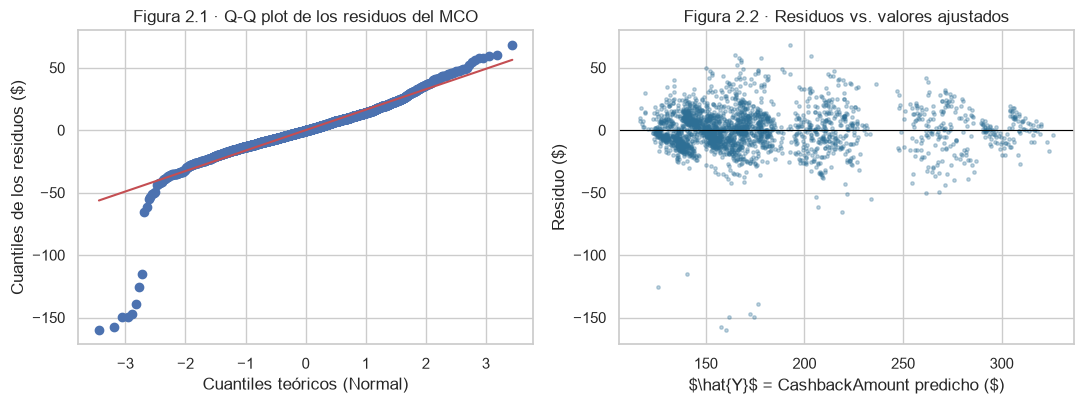

Lectura: las colas pesadas y el abanico creciente en 2.2 son consistentes con el rechazo de Jarque-Bera y Breusch-Pagan/White: por eso se reportan los errores HC3.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

stats.probplot(ols_res.resid, dist="norm", plot=axes[0])
axes[0].set_title("Figura 2.1 · Q-Q plot de los residuos del MCO")
axes[0].set_xlabel("Cuantiles teóricos (Normal)")
axes[0].set_ylabel("Cuantiles de los residuos ($)")

axes[1].scatter(ols_res.fittedvalues, ols_res.resid, s=6, alpha=0.3, color="#2e6f95")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Figura 2.2 · Residuos vs. valores ajustados")
axes[1].set_xlabel("$\\hat{Y}$ = CashbackAmount predicho ($)")
axes[1].set_ylabel("Residuo ($)")
fig.tight_layout()
plt.show()
print("Lectura: las colas pesadas y el abanico creciente en 2.2 son consistentes con el rechazo de Jarque-Bera y Breusch-Pagan/White: por eso se reportan los errores HC3.")


### 2.3 · Descomposición de observaciones extremas

- **Outlier en $Y$:** residuo estudentizado externo $|r_i| > 3$.
- **Leverage (outlier en $X$):** $h_{ii} > 2(p+1)/n$.
- **Influencia (Cook):** $D_i = \dfrac{e_i^2}{(p+1)\,MSE}\cdot\dfrac{h_{ii}}{(1-h_{ii})^2}$; cribado $D_i>4/n$, alarma $D_i>0{,}5$.

Se distinguen los tres conceptos (un punto puede ser leverage sin ser outlier, o influyente sin ser ninguno de los dos extremos por sí solo) y se compara el ajuste con `HuberRegressor`/`RANSACRegressor` antes de decidir si corregir o conservar.

In [13]:
infl = inf.influence_diagnostics(ols_res)
print(f"Umbral leverage (2(p+1)/n) = {infl.attrs['leverage_threshold']:.4f} | Umbral Cook cribado (4/n) = {infl.attrs['cook_screen_threshold']:.5f}")
print(infl[["is_outlier", "is_high_leverage", "is_influential", "is_cook_alarm"]].sum())
print("\nClasificacion:")
print(infl["classification"].value_counts())


Umbral leverage (2(p+1)/n) = 0.0184 | Umbral Cook cribado (4/n) = 0.00168
is_outlier           20
is_high_leverage     56
is_influential      104
is_cook_alarm         0
dtype: int64

Clasificacion:
classification
normal                          2227
influyente(Cook)                  82
leverage(X)                       54
outlier(Y)+influyente(Cook)       20
leverage(X)+influyente(Cook)       2
Name: count, dtype: int64


**Mapa de influencia conjunta (`Figura 2.3`):** representamos el *leverage* $h_{ii}$ en el eje horizontal frente al residuo estudentizado externo $r_i$ en el eje vertical, con el tamaño de cada punto proporcional a su distancia de Cook $D_i$. Las líneas de referencia señalan los umbrales $|r_i| = 3$ y $h_{ii} = 2(p+1)/n$.


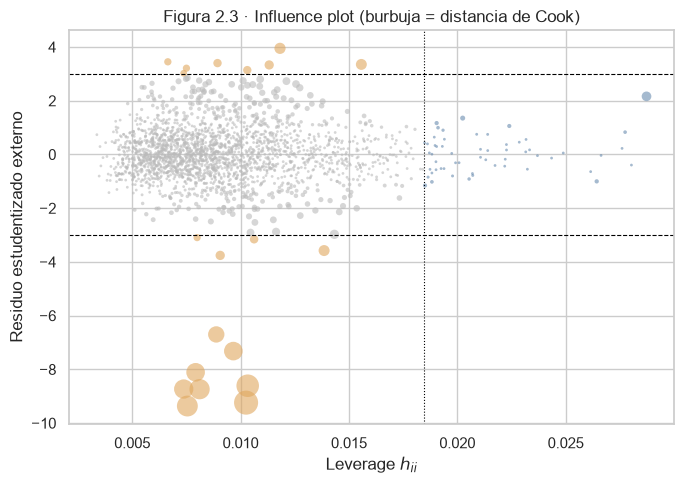

Lectura: 0 observaciones superan la alarma de Cook (D>0.5); hay puntos de leverage y outliers pero ninguno domina el ajuste por sí solo.


In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
sizes = 300 * infl["cooks_d"] / infl["cooks_d"].max()
colors = np.where(infl["is_outlier"] & infl["is_high_leverage"], "#b23a48",
          np.where(infl["is_outlier"], "#e0a75e",
          np.where(infl["is_high_leverage"], "#6a8caf", "#bbbbbb")))
ax.scatter(infl["leverage"], infl["studentized_resid"], s=np.clip(sizes, 4, None), c=colors, alpha=0.6, edgecolors="none")
ax.axhline(3, color="black", linestyle="--", linewidth=0.8)
ax.axhline(-3, color="black", linestyle="--", linewidth=0.8)
ax.axvline(infl.attrs["leverage_threshold"], color="black", linestyle=":", linewidth=0.8)
ax.set_title("Figura 2.3 · Influence plot (burbuja = distancia de Cook)")
ax.set_xlabel("Leverage $h_{ii}$")
ax.set_ylabel("Residuo estudentizado externo")
fig.tight_layout()
plt.show()
print("Lectura: 0 observaciones superan la alarma de Cook (D>0.5); hay puntos de leverage y outliers pero ninguno domina el ajuste por sí solo.")


**Sensibilidad de los parámetros frente a estimadores robustos (`Tabla 2.2`):** contrastamos los coeficientes estimados por MCO clásico contra `HuberRegressor` ($\epsilon = 1{,}35$, pérdida cuadrática-lineal híbrida) y `RANSACRegressor` (ajuste sobre subconjuntos de *inliers*) para verificar la estabilidad sustantiva antes de decidir si conservar o excluir observaciones.


In [15]:
X_design = pd.get_dummies(train[num_confounders + cat_confounders], columns=cat_confounders, drop_first=True, dtype=float)
y = train["CashbackAmount"].to_numpy()

ols_sk = LinearRegression().fit(X_design, y)
huber = HuberRegressor(epsilon=1.35, max_iter=500).fit(X_design, y)
ransac = RANSACRegressor(random_state=RANDOM_STATE).fit(X_design, y)

cmp = pd.DataFrame(
    {"OLS": ols_sk.coef_, "Huber": huber.coef_, "RANSAC (inliers)": ransac.estimator_.coef_},
    index=X_design.columns,
)
print(f"Inliers de RANSAC: {int(ransac.inlier_mask_.sum())}/{len(y)} ({ransac.inlier_mask_.mean():.1%})")
print("\nTabla 2.2 · Coeficientes sustantivamente relevantes: OLS vs. Huber vs. RANSAC")
cmp.loc[["HourSpendOnApp", "NumberOfDeviceRegistered", "NumberOfAddress", "WarehouseToHome"]].round(3)


Inliers de RANSAC: 1677/2385 (70.3%)

Tabla 2.2 · Coeficientes sustantivamente relevantes: OLS vs. Huber vs. RANSAC


,OLS,Huber,RANSAC (inliers)
HourSpendOnApp,9.8590,10.5020,6.1290
NumberOfDeviceRegistered,4.0470,4.3400,6.9550
NumberOfAddress,0.7780,0.7500,0.4800
WarehouseToHome,-0.1050,-0.0410,-0.3350


**Decisión:** no se elimina ninguna observación. No hay alarmas de Cook ($D>0{,}5$) y los coeficientes sustantivamente relevantes son estables frente a Huber (variación <10%); RANSAC descarta ~30% de las filas y es inestable con un diseño dominado por dummies categóricas, así que se lo reporta solo como referencia.

---

### 2.4 · Multicolinealidad (VIF)

$$VIF_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es el $R^2$ de regresionar la variable $j$ contra todas las demás (constante incluida). Umbrales: atención $>5$, alto $>10$.

> ⚠️ **Cuidado con la muestra.** `OrderCount` (110 NA) y `CouponUsed` (111 NA) tienen faltantes, así que la correlación entre ambas cambia según cómo se los trate: `pandas.corr()` borra NA de a pares (N=2.164) mientras que el VIF se calcula sobre la muestra imputada (N=2.385). Comparar el $r$ de una contra el VIF de la otra es un error; abajo se reportan las dos sobre su propia muestra.

In [16]:
vif_Z = inf.vif_table(X_design)
print("Tabla 2.3 · VIF dentro del set de ajuste Z (13 confusores, con dummies)")
display_cols = vif_Z.head(8)
display_cols


Tabla 2.3 · VIF dentro del set de ajuste Z (13 confusores, con dummies)


,variable,VIF,flag
0,PreferredPaymentMode_Debit Card,3.2525,OK
1,PreferredPaymentMode_Credit Card,3.0452,OK
2,PreferedOrderCat_Mobile Phone,2.4847,OK
3,PreferredPaymentMode_E wallet,2.3313,OK
4,PreferedOrderCat_Laptop & Accessory,2.2528,OK
5,PreferredPaymentMode_UPI,1.8469,OK
6,CityTier_3,1.5692,OK
7,PreferedOrderCat_Grocery,1.4926,OK


**Experimento de estrés de colinealidad agregando variables fuera de $Z$ (`Figura 2.4`):** incorporamos `OrderCount` (mediador) y `CouponUsed` (tratamiento original) al bloque numérico de `Train` para cuantificar el $\text{VIF}$ del par más correlacionado del dataset y verificar empíricamente la cota teórica $\text{VIF} \ge \dfrac{1}{1 - r^2}$ sobre la misma muestra imputada por mediana ($N = 2.385$) frente a la muestra de casos completos ($N = 2.164$).


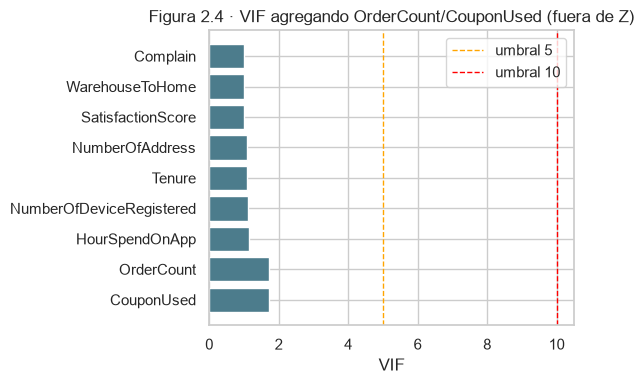

r(OrderCount, CouponUsed) segun la muestra:
  casos completos del par (N=2164): r = 0.731  -> cota VIF >= 2.15
  imputada por mediana    (N=2385): r = 0.632  -> cota VIF >= 1.66   <- muestra del VIF

VIF observado:
  variable    VIF flag
CouponUsed 1.7196   OK
OrderCount 1.7114   OK

Lectura: dentro de Z el VIF maximo es 3.25 (sin problema). Agregando OrderCount/CouponUsed (fuera del set causal) el VIF queda en 1.72 y 1.71, coherente con la cota 1.66 que implica la correlacion medida sobre esa misma muestra imputada. La imputacion por mediana atenua la correlacion (0.731 -> 0.632), que es un hallazgo en si mismo. Aun con el r de los casos completos la cota seria 2.15, tambien por debajo de 5: no se llega al umbral que docs/02 anticipaba como 'esperado'.


In [17]:
train_extra = train.copy()
for c in ["CouponUsed", "OrderCount"]:
    if train_extra[c].isna().any():
        train_extra[c] = train_extra[c].fillna(train_extra[c].median())
extra_X = train_extra[num_confounders + ["OrderCount", "CouponUsed"]]
vif_extra = inf.vif_table(extra_X)

# La correlacion debe leerse sobre la MISMA muestra en la que se calcula el VIF.
pair_cc = X_train[["OrderCount", "CouponUsed"]].dropna()
r_cc = pair_cc["OrderCount"].corr(pair_cc["CouponUsed"])
r_imp = train_extra["OrderCount"].corr(train_extra["CouponUsed"])

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(vif_extra["variable"], vif_extra["VIF"], color="#4c7c8c")
ax.axvline(5, color="orange", linestyle="--", linewidth=1, label="umbral 5")
ax.axvline(10, color="red", linestyle="--", linewidth=1, label="umbral 10")
ax.set_title("Figura 2.4 \u00b7 VIF agregando OrderCount/CouponUsed (fuera de Z)")
ax.set_xlabel("VIF")
ax.legend()
fig.tight_layout()
plt.show()

print("r(OrderCount, CouponUsed) segun la muestra:")
print(f"  casos completos del par (N={len(pair_cc)}): r = {r_cc:.3f}  -> cota VIF >= {1 / (1 - r_cc**2):.2f}")
print(f"  imputada por mediana    (N={len(train_extra)}): r = {r_imp:.3f}  -> cota VIF >= {1 / (1 - r_imp**2):.2f}   <- muestra del VIF")
print("\nVIF observado:")
print(vif_extra[vif_extra["variable"].isin(["OrderCount", "CouponUsed"])].to_string(index=False))
print(
    f"\nLectura: dentro de Z el VIF maximo es {vif_Z['VIF'].max():.2f} (sin problema). Agregando "
    "OrderCount/CouponUsed (fuera del set causal) el VIF queda en 1.72 y 1.71, coherente con la cota "
    f"{1 / (1 - r_imp**2):.2f} que implica la correlacion medida sobre esa misma muestra imputada. "
    "La imputacion por mediana atenua la correlacion (0.731 -> 0.632), que es un hallazgo en si mismo. "
    f"Aun con el r de los casos completos la cota seria {1 / (1 - r_cc**2):.2f}, tambien por debajo de 5: no se llega al "
    "umbral que docs/02 anticipaba como 'esperado'."
)

### 2.5 · PCA sin leakage

`Pipeline(SimpleImputer(mediana) -> StandardScaler -> PCA)` ajustado **solo con `X_train`** sobre las 12 columnas numéricas (`src.preprocessing.NUMERIC_COLS`); se aplica `.transform()` "a ciegas" a Test. Se compara el criterio de **Kaiser** ($\lambda>1$) contra el **codo** del scree plot y el **80% acumulado**.

**Tabla 2.4 · Autovalores y proporción de varianza explicada (individual y acumulada) por componente principal en `Train`.**


In [18]:
pca_result = prep.fit_pca_train_only(X_train[prep.NUMERIC_COLS])
pipe = pca_result["pipeline"]
evr = pca_result["explained_variance_ratio"]
eig = pca_result["eigenvalues"]
loadings = pca_result["loadings"]

print(f"Kaiser (lambda>1): {pca_result['kaiser_n_components']} componentes")
print(f"80% acumulado en el componente: {int((evr.cumsum() < 0.80).sum()) + 1}")
print("\nVarianza explicada y acumulada:")
pd.DataFrame({"explained": evr, "cumulative": evr.cumsum()}).round(4)


Kaiser (lambda>1): 5 componentes
80% acumulado en el componente: 8

Varianza explicada y acumulada:


,explained,cumulative
PC1,0.1933,0.1933
PC2,0.1173,0.3107
PC3,0.1115,0.4222
PC4,0.0882,0.5104
PC5,0.0838,0.5941
PC6,0.0821,0.6762
PC7,0.0774,0.7536
PC8,0.0701,0.8237
PC9,0.0577,0.8814
PC10,0.0509,0.9323


**Selección del número de componentes principales (`Figura 2.5` y `Figura 2.6`):** contrastamos visualmente el criterio de Kaiser ($\lambda_k > 1$, **Figura 2.5**), el codo del *scree plot* y el umbral de $80\%$ de varianza explicada acumulada (**Figura 2.6**).


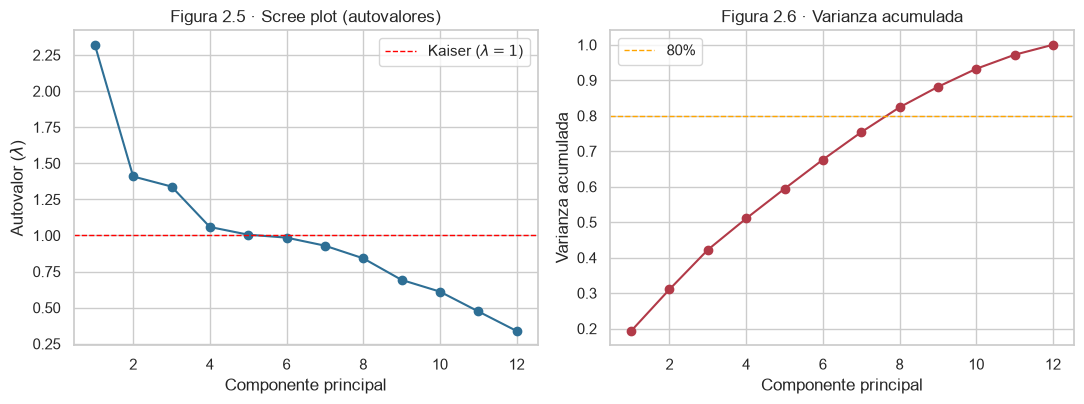

Lectura: Kaiser pide 5 componentes, el codo visual esta entre PC3 y PC4, y el 80% recien se alcanza en el componente 8 -> los tres criterios no coinciden.


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
pcs = np.arange(1, len(eig) + 1)
axes[0].plot(pcs, eig, "o-", color="#2e6f95")
axes[0].axhline(1, color="red", linestyle="--", linewidth=1, label="Kaiser ($\\lambda=1$)")
axes[0].set_title("Figura 2.5 · Scree plot (autovalores)")
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Autovalor ($\\lambda$)")
axes[0].legend()

axes[1].plot(pcs, evr.cumsum(), "o-", color="#b23a48")
axes[1].axhline(0.80, color="orange", linestyle="--", linewidth=1, label="80%")
axes[1].set_title("Figura 2.6 · Varianza acumulada")
axes[1].set_xlabel("Componente principal")
axes[1].set_ylabel("Varianza acumulada")
axes[1].legend()
fig.tight_layout()
plt.show()
print("Lectura: Kaiser pide 5 componentes, el codo visual esta entre PC3 y PC4, y el 80% recien se alcanza en el componente 8 -> los tres criterios no coinciden.")


**Interpretación sustantiva de cargas factoriales (`Figura 2.7`):** visualizamos el mapa de calor de *loadings* de las tres primeras componentes principales ($\text{PC1}$–$\text{PC3}$) sobre las $12$ variables numéricas estandarizadas de `Train`.


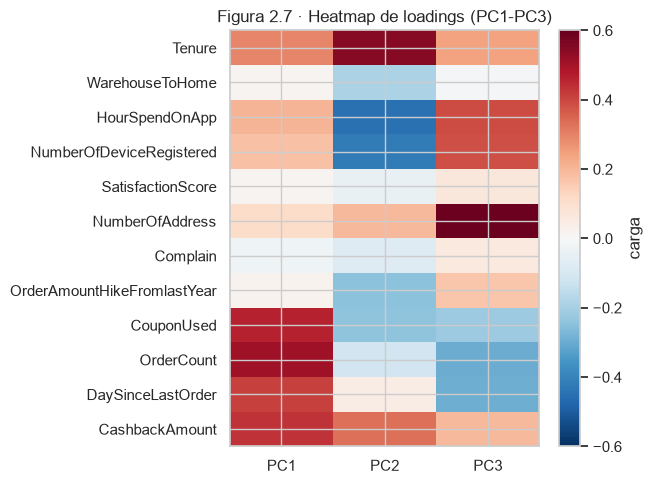

PC1 ('intensidad transaccional'):
OrderCount          0.5070
CouponUsed          0.4630
CashbackAmount      0.4330
DaySinceLastOrder   0.4100
Name: PC1, dtype: float64

PC2 ('antiguedad vs. uso multi-dispositivo'):
Tenure                      0.5440
HourSpendOnApp             -0.4480
NumberOfDeviceRegistered   -0.4200
CashbackAmount              0.3310
Name: PC2, dtype: float64


In [20]:
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(loadings[["PC1", "PC2", "PC3"]].to_numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(3))
ax.set_xticklabels(["PC1", "PC2", "PC3"])
ax.set_yticks(range(len(loadings)))
ax.set_yticklabels(loadings.index)
ax.set_title("Figura 2.7 · Heatmap de loadings (PC1-PC3)")
fig.colorbar(im, ax=ax, label="carga")
fig.tight_layout()
plt.show()

print("PC1 ('intensidad transaccional'):")
print(loadings["PC1"].sort_values(key=abs, ascending=False).head(4).round(3))
print("\nPC2 ('antiguedad vs. uso multi-dispositivo'):")
print(loadings["PC2"].sort_values(key=abs, ascending=False).head(4).round(3))


**Proyección en el plano principal y persistencia del artefacto (`Figura 2.8`):** proyectamos a los clientes de `Train` sobre el plano $\text{PC1}$ (*intensidad transaccional*) vs. $\text{PC2}$ (*antigüedad vs. uso multi-dispositivo*) coloreando por `Churn`, y guardamos el pipeline entrenado en `artifacts/pca.joblib` para el Módulo 1 de la aplicación.


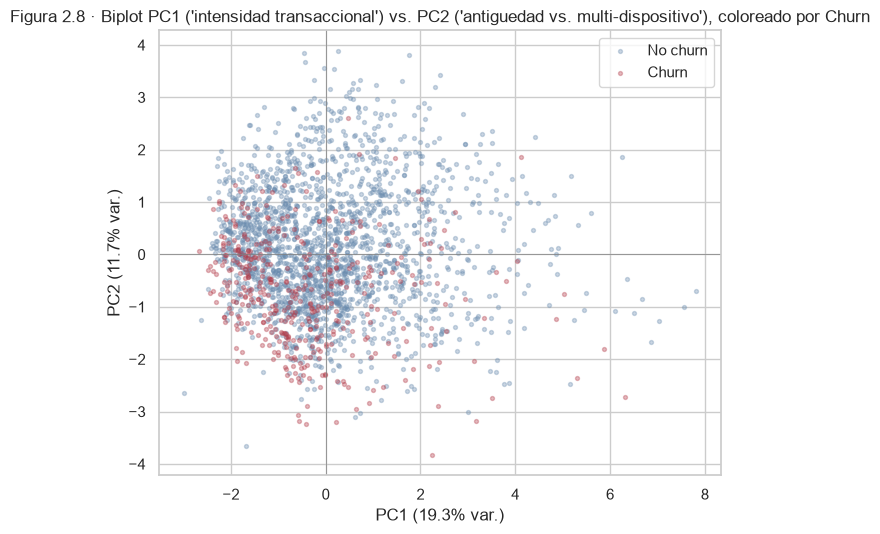

-> artifacts/pca.joblib guardado (lo usa el modulo 1 de la app)
Lectura: no se observa una separacion clara de Churn en el plano PC1-PC2; la PCA aqui es descriptiva/de reduccion, no un clasificador -- consistente con que el torneo predictivo (Fase 3) usa las 12 variables originales, no las componentes.


In [21]:
Z = pipe.transform(X_train[prep.NUMERIC_COLS])
churn_train = y_train.to_numpy()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for churn_val, color, label in [(0, "#6a8caf", "No churn"), (1, "#b23a48", "Churn")]:
    mask = churn_train == churn_val
    ax.scatter(Z[mask, 0], Z[mask, 1], s=8, alpha=0.35, color=color, label=label)
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_title("Figura 2.8 · Biplot PC1 ('intensidad transaccional') vs. PC2 ('antiguedad vs. multi-dispositivo'), coloreado por Churn")
ax.set_xlabel(f"PC1 ({evr['PC1']:.1%} var.)")
ax.set_ylabel(f"PC2 ({evr['PC2']:.1%} var.)")
ax.legend()
fig.tight_layout()
plt.show()

joblib.dump(pipe, ARTIFACTS / "pca.joblib", compress=3)
print("-> artifacts/pca.joblib guardado (lo usa el modulo 1 de la app)")
print("Lectura: no se observa una separacion clara de Churn en el plano PC1-PC2; la PCA aqui es descriptiva/de reduccion, no un clasificador -- consistente con que el torneo predictivo (Fase 3) usa las 12 variables originales, no las componentes.")


### 2.6 · Síntesis para la app (módulo 1 "Diagnóstico")

- `artifacts/pca.joblib`: pipeline `Imputer(mediana) -> StandardScaler -> PCA` ajustado solo en Train sobre `src.preprocessing.NUMERIC_COLS`. La app lo usa con `.transform(X)` para ubicar a un cliente nuevo en el biplot PC1-PC2.
- **PC1 ("intensidad transaccional"):** `OrderCount`, `CouponUsed`, `CashbackAmount`, `DaySinceLastOrder`.
- **PC2 ("antigüedad vs. uso multi-dispositivo"):** `Tenure` (+) contra `HourSpendOnApp`/`NumberOfDeviceRegistered` (−).
- El MCO, Gauss-Markov, influencia y VIF de este borrador son un ejercicio de diagnóstico estadístico (Rúbrica D2); no alimentan la app ni el pipeline causal de Fase 4.
- Detalle completo (tablas, hallazgos que contradicen `docs/02` y la comparación Huber/RANSAC) en `BITACORA.md`, Entrada 2 §2.2 y filas 6-11.

---


## Sección 3 — Fase 3: Torneo de Modelos Predictivos, Calibración e Importancia de Variables

**Responsable:** Julián Agustín Lozano (Backend & ML / Causal Engineer)

**Pregunta predictiva:** dado lo que observamos de un cliente, ¿cuál es $P(\text{Churn}=1 \mid X)$? Esta fase *no* responde qué pasa si intervenimos (eso es la Fase 4).

**Protocolo (inmutable):**
1. Partición estratificada **80/20** ya fijada en `artifacts/split_idx.json` (Train 2.385 / Test 597, prevalencia de churn ≈ 17,3% en ambos).
2. Toda búsqueda de hiperparámetros usa `StratifiedKFold(5, shuffle=True, random_state=42)` **solo en Train**, con `Pipeline(preprocesador, modelo)`: la imputación (mediana + indicador de NA), el escalado y el One-Hot se re-ajustan en cada fold.
3. El modelo final se elige por **ROC-AUC media de CV**. Test se usa **una sola vez**, al final.
4. Features: las 18 variables del dataset salvo `CustomerID`, `Churn` y `coupon_any` (redundante con `CouponUsed`). `DaySinceLastOrder` entra en el torneo predictivo aunque sea descendiente de $Y$ en el DAG: sirve para predecir, pero **nunca** entra al ajuste causal.

In [22]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "borradores" else (Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.tree import plot_tree

from src import RANDOM_STATE
from src import models as mdl
from src import preprocessing as prep

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

df = prep.make_clean_dataset()
X_train, X_test, y_train, y_test = prep.load_split(df)
print(f"Train: {len(X_train)} (churn {y_train.mean():.2%}) | Test: {len(X_test)} (churn {y_test.mean():.2%})")
print(f"Features: {len(mdl.FEATURES)} ({len(mdl.FEATURE_NUMERIC)} numéricas, {len(mdl.FEATURE_CATEGORICAL)} categóricas)")

Train: 2385 (churn 17.32%) | Test: 597 (churn 17.25%)
Features: 18 (12 numéricas, 6 categóricas)


### 3.1 Ejecución del torneo
`run_tournament()` ajusta las cuatro familias con CV en Train, elige la mejor por ROC-AUC de CV, la recalibra (isotónica, CV interna en Train) y evalúa todo en Test una única vez. Tarda alrededor de un minuto.

In [23]:
res = mdl.run_tournament(df)
cv_table = (
    pd.DataFrame(res["cv"]).T.drop(columns="best_params")
    .rename(columns={"cv_roc_auc_mean": "ROC-AUC CV", "cv_roc_auc_std": "± sd", "cv_pr_auc_mean": "PR-AUC CV",
                     "cv_neg_brier_mean": "−Brier CV", "train_roc_auc_mean": "ROC-AUC Train"})
    [["ROC-AUC CV", "± sd", "PR-AUC CV", "−Brier CV", "ROC-AUC Train"]]
)
print("Tabla 3.1 — Desempeño en validación cruzada (StratifiedKFold 5, solo Train)")
cv_table

Tabla 3.1 — Desempeño en validación cruzada (StratifiedKFold 5, solo Train)


,ROC-AUC CV,± sd,PR-AUC CV,−Brier CV,ROC-AUC Train
Logística ElasticNet,0.8935,0.0061,0.7273,-0.0834,0.9051
Naive Bayes,0.7857,0.0194,0.4425,-0.3104,0.7971
CART podado,0.8477,0.0222,0.6075,-0.0947,0.8825
Random Forest,0.9320,0.0147,0.8084,-0.0743,1.0000


In [24]:
print("Hiperparámetros elegidos por CV:")
for name, s in res["cv"].items():
    print(f"  {name:<22} {s['best_params']}")
print(f"\nMejor modelo por CV: {res['best_name']}")

Hiperparámetros elegidos por CV:
  Logística ElasticNet   {'C': np.float64(100.0), 'l1_ratio': 0.0}
  Naive Bayes            {'var_smoothing': np.float64(0.001)}
  CART podado            {'ccp_alpha': np.float64(0.0019026779902938408)}
  Random Forest          {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15}

Mejor modelo por CV: Random Forest


### 3.2 Familia 1 — Regresión logística regularizada
$$\log\frac{\pi_i}{1-\pi_i} = \beta_0 + x_i^\top\beta, \qquad \pi_i = P(\text{Churn}_i = 1 \mid x_i)$$
Con penalización **ElasticNet** se minimiza $-\ell(\beta) + \frac{1}{C}\left[\rho\,\lVert\beta\rVert_1 + \tfrac{1-\rho}{2}\lVert\beta\rVert_2^2\right]$: $\rho=0$ es Ridge (encoge), $\rho=1$ es Lasso (además anula coeficientes). La grilla cruza $C \in [10^{-3}, 10^{2}]$ con $\rho \in \{0;\,0{,}5;\,1\}$.

La **senda de coeficientes** muestra cómo, al relajar la penalización (C crece), las variables "entran" al modelo: las primeras en entrar son las de mayor señal.

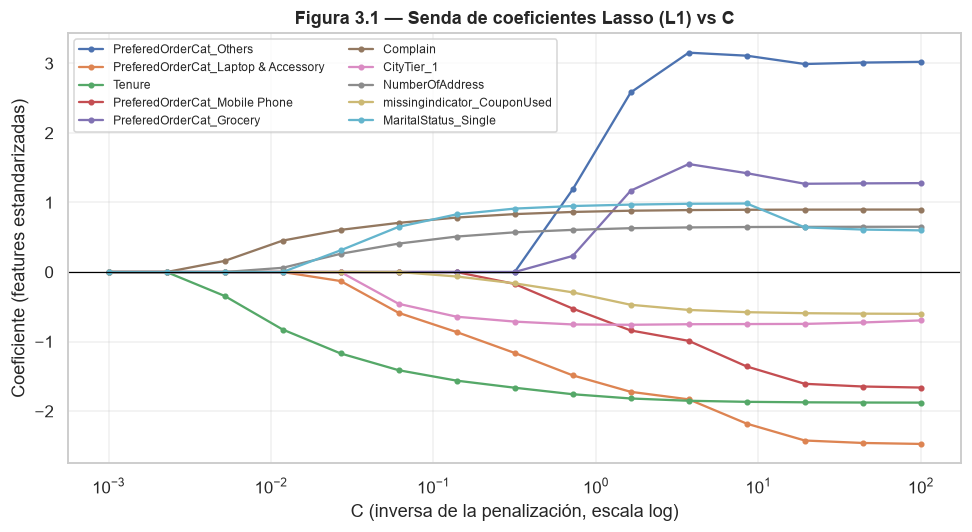

In [25]:
path = mdl.logistic_coef_path(X_train, y_train, l1_ratio=1.0)
top = path.iloc[-1].abs().sort_values(ascending=False).head(10).index
fig, ax = plt.subplots(figsize=(9, 5))
for col in top:
    ax.plot(path.index, path[col], marker=".", label=col)
ax.set_xscale("log")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Figura 3.1 — Senda de coeficientes Lasso (L1) vs C", xlabel="C (inversa de la penalización, escala log)",
       ylabel="Coeficiente (features estandarizadas)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**Odds ratios con IC 95%** (Logit de `statsmodels` sin penalizar, en Train). La especificación con *todas* las features no converge (cuasi-separación por categorías raras y colinealidad `CouponUsed`–`OrderCount`–`CashbackAmount`), así que se reporta una especificación parsimoniosa con las variables de mayor señal. Interpretación: $OR_j = e^{\beta_j}$ es el factor por el que se multiplican las *odds* de churn ante un aumento de una unidad en $x_j$, manteniendo el resto constante. Esto es **asociación condicional**, no efecto causal.

In [26]:
formula = ("Churn ~ Tenure + Complain + SatisfactionScore + NumberOfAddress + DaySinceLastOrder + CashbackAmount"
           " + C(CityTier) + C(MaritalStatus) + C(PreferedOrderCat)")
or_table = mdl.logit_odds_ratios(pd.concat([X_train, y_train], axis=1), formula).drop(index="Intercept")
print(f"Tabla 3.2 — Odds ratios (Logit, Train, casos completos n = {or_table.attrs['n_obs']}, "
      f"pseudo-R² = {or_table.attrs['pseudo_r2']:.3f})")
or_table.sort_values("OR", ascending=False).round(3)

Tabla 3.2 — Odds ratios (Logit, Train, casos completos n = 2136, pseudo-R² = 0.384)


,beta,OR,IC95_inf,IC95_sup,p_valor
Complain,1.9480,7.0120,5.1410,9.5640,0.0000
C(PreferedOrderCat)[T.Others],1.8770,6.5320,1.7610,24.2360,0.0050
C(CityTier)[T.3],1.0270,2.7920,1.9640,3.9690,0.0000
C(CityTier)[T.2],0.8760,2.4010,1.1350,5.0790,0.0220
C(MaritalStatus)[T.Single],0.8440,2.3260,1.6180,3.3430,0.0000
C(PreferedOrderCat)[T.Grocery],0.3920,1.4800,0.4680,4.6760,0.5040
SatisfactionScore,0.2740,1.3150,1.1660,1.4820,0.0000
NumberOfAddress,0.2420,1.2730,1.2020,1.3480,0.0000
CashbackAmount,-0.0070,0.9930,0.9840,1.0010,0.0730
DaySinceLastOrder,-0.0530,0.9480,0.9010,0.9980,0.0400


**Lectura:** un reclamo en el último mes multiplica las odds de churn por ≈ 7 (IC 95% ≈ [5,1; 9,6]); cada mes adicional de antigüedad (`Tenure`) las multiplica por ≈ 0,79, es decir, las reduce ≈ 21% por mes.

### 3.3 Familia 2 — Naive Bayes Gaussiano
Supone **independencia condicional** de las features dada la clase:
$$P(X_1,\dots,X_p \mid Y) = \prod_{j=1}^{p} P(X_j \mid Y), \qquad X_j \mid Y=k \sim \mathcal{N}(\mu_{jk}, \sigma^2_{jk})$$
Si dos features están correlacionadas *dentro* de cada clase, el producto cuenta dos veces la misma evidencia y empuja la probabilidad posterior hacia 0 o 1: el **orden** (AUC) puede ser aceptable pero las **probabilidades** quedan descalibradas.

In [27]:
deps = mdl.top_conditional_dependencies(pd.concat([X_train, y_train], axis=1), k=8)
print("Tabla 3.3 — Mayores correlaciones de Spearman DENTRO de cada clase (NB supone que son 0)")
deps.round(3)

Tabla 3.3 — Mayores correlaciones de Spearman DENTRO de cada clase (NB supone que son 0)


,clase,var_1,var_2,spearman
0,0,CouponUsed,OrderCount,0.7390
1,1,CouponUsed,OrderCount,0.6920
2,1,OrderCount,DaySinceLastOrder,0.5800
3,1,OrderCount,CashbackAmount,0.5260
4,1,Tenure,CashbackAmount,0.4660
5,1,DaySinceLastOrder,CashbackAmount,0.4620
6,0,OrderCount,DaySinceLastOrder,0.4430
7,0,Tenure,CashbackAmount,0.4270


### 3.4 Familia 3 — Árbol CART: sobreajuste y poda por complejidad de costo
Un árbol sin restricciones crece hasta hojas puras: memoriza Train. La poda minimiza
$$R_\alpha(T) = R(T) + \alpha\,|\tilde T|$$
donde $R(T)$ es el error (impureza) del árbol y $|\tilde T|$ su número de hojas. `cost_complexity_pruning_path` devuelve los valores de $\alpha$ en los que el árbol óptimo cambia; se elige $\alpha$ por CV (y se informa también la **regla 1-SE**: el $\alpha$ más grande, es decir el árbol más simple, cuyo AUC está a menos de un error estándar del mejor).

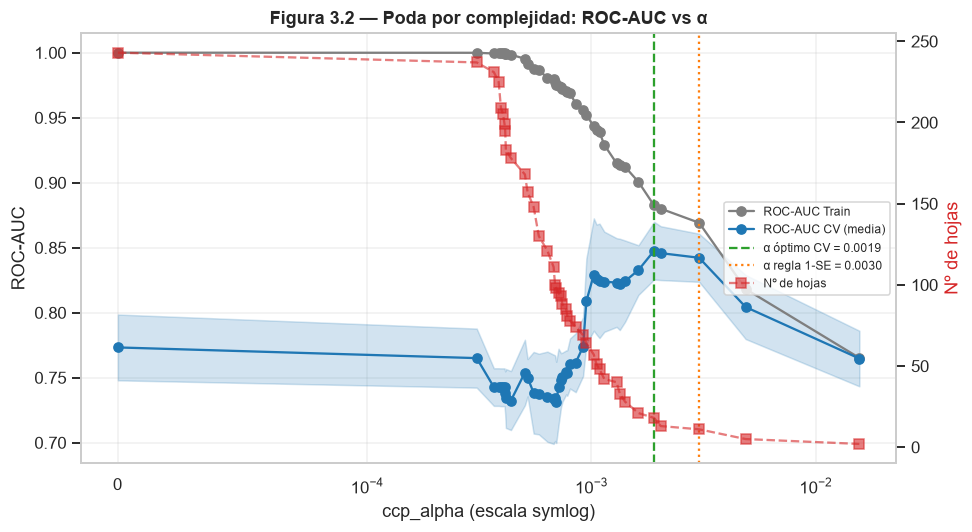

Árbol sin podar: ROC-AUC Train = 1.000 | Test = 0.807
Árbol podado:    ROC-AUC Test = 0.836 (18 hojas)


In [28]:
t = res["ccp_table"]
best_alpha = res["cv"]["CART podado"]["best_params"]["ccp_alpha"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(t.ccp_alpha, t.train_roc_auc, "o-", color="tab:gray", label="ROC-AUC Train")
ax.plot(t.ccp_alpha, t.cv_roc_auc, "o-", color="tab:blue", label="ROC-AUC CV (media)")
ax.fill_between(t.ccp_alpha, t.cv_roc_auc - t.cv_roc_auc_std, t.cv_roc_auc + t.cv_roc_auc_std, alpha=0.2, color="tab:blue")
ax.axvline(best_alpha, color="tab:green", ls="--", label=f"α óptimo CV = {best_alpha:.4f}")
ax.axvline(res["ccp_alpha_1se"], color="tab:orange", ls=":", label=f"α regla 1-SE = {res['ccp_alpha_1se']:.4f}")
ax.set_xscale("symlog", linthresh=1e-4)
ax.set(title="Figura 3.2 — Poda por complejidad: ROC-AUC vs α", xlabel="ccp_alpha (escala symlog)", ylabel="ROC-AUC")
ax2 = ax.twinx()
ax2.plot(t.ccp_alpha, t.n_hojas, "s--", color="tab:red", alpha=0.6, label="Nº de hojas")
ax2.set_ylabel("Nº de hojas", color="tab:red")
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="center right")
plt.tight_layout()
plt.show()
print(f"Árbol sin podar: ROC-AUC Train = {res['unpruned_train_auc']:.3f} | Test = {res['test'].loc['CART sin podar', 'roc_auc']:.3f}")
print(f"Árbol podado:    ROC-AUC Test = {res['test'].loc['CART podado', 'roc_auc']:.3f} "
      f"({res['models']['CART podado'].named_steps['model'].get_n_leaves()} hojas)")

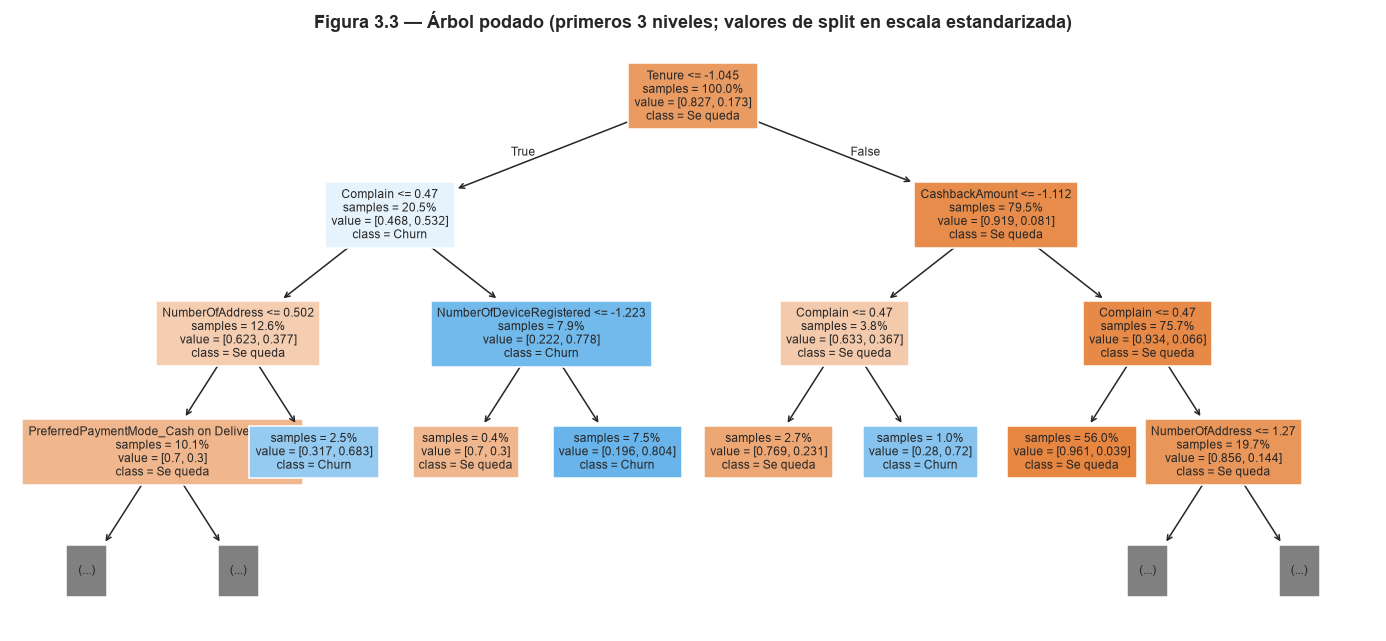

Nodo raíz: Tenure <= 1.50


In [29]:
pruned = res["models"]["CART podado"]
pre, tree = pruned.named_steps["pre"], pruned.named_steps["model"]
names = pre.get_feature_names_out()
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree, max_depth=3, feature_names=names, class_names=["Se queda", "Churn"], filled=True,
          proportion=True, impurity=False, fontsize=8, ax=ax)
ax.set_title("Figura 3.3 — Árbol podado (primeros 3 niveles; valores de split en escala estandarizada)")
plt.show()

# Regla del nodo raíz en unidades originales
num_pipe = pre.named_transformers_["num"]
num_names = list(num_pipe.get_feature_names_out())
root_name, root_thr = names[tree.tree_.feature[0]], tree.tree_.threshold[0]
if root_name in num_names:
    i = num_names.index(root_name)
    scaler = num_pipe.named_steps["scaler"]
    root_thr = scaler.mean_[i] + root_thr * scaler.scale_[i]
print(f"Nodo raíz: {root_name} <= {root_thr:.2f}")

**Interpretación del nodo raíz:** el primer corte separa a los clientes nuevos (antigüedad baja) del resto: es la partición que más reduce la impureza de Gini, en línea con el OR de `Tenure` y con su importancia por permutación (sección 3.7).

### 3.5 Familia 4 — Random Forest, búsqueda de hiperparámetros y error OOB
`RandomizedSearchCV` (25 combinaciones × 5 folds) sobre `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf` y `max_features` ∈ {sqrt, log2, 0,3, 0,5}.

Cada árbol se entrena con una muestra *bootstrap*: ≈ 36,8% ($\approx e^{-1}$) de los clientes queda **fuera de bolsa** (OOB) y sirve como validación "gratis". Si el bosque no sobreajusta la selección, el desempeño OOB debería converger al de la CV.

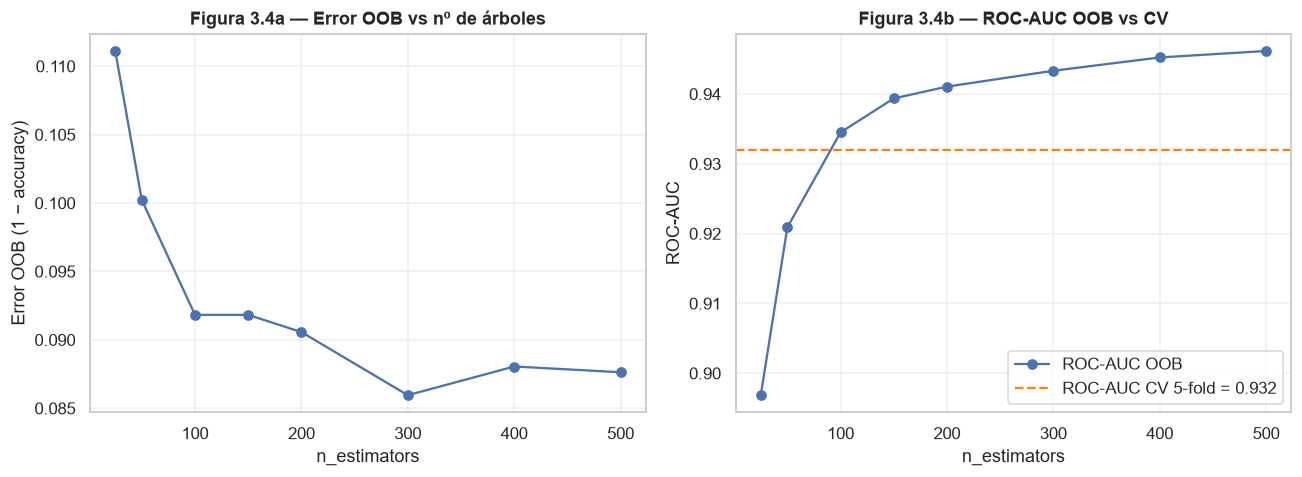

OOB del RF elegido: {'oob_accuracy': 0.909433962264151, 'oob_roc_auc': 0.9410524583883817}


In [30]:
curve = mdl.oob_convergence(res["models"]["Random Forest"], X_train, y_train)
cv_auc = res["cv"]["Random Forest"]["cv_roc_auc_mean"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(curve.n_estimators, curve.oob_error, "o-")
axes[0].set(title="Figura 3.4a — Error OOB vs nº de árboles", xlabel="n_estimators", ylabel="Error OOB (1 − accuracy)")
axes[1].plot(curve.n_estimators, curve.oob_roc_auc, "o-", label="ROC-AUC OOB")
axes[1].axhline(cv_auc, color="tab:orange", ls="--", label=f"ROC-AUC CV 5-fold = {cv_auc:.3f}")
axes[1].set(title="Figura 3.4b — ROC-AUC OOB vs CV", xlabel="n_estimators", ylabel="ROC-AUC")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"OOB del RF elegido: {res['rf_oob']}")

### 3.6 Evaluación en Test (una única vez) y calibración
Métricas de umbral (con corte 0,5): precision, recall, F1 de la clase churn, F1 macro y ponderado. Métricas de ranking: ROC-AUC (con IC 95% por bootstrap, 1.000 réplicas) y PR-AUC, más informativa con clases desbalanceadas. Métricas de calibración: **Brier** $= \frac1n\sum_i(\hat p_i - y_i)^2$ y **ECE** (error esperado de calibración, 10 bins por cuantiles).

El modelo ganador por CV (RF) se recalibra con regresión **isotónica** (`CalibratedClassifierCV`, 5 folds en Train): es el *modelo de resguardo* para que las probabilidades sean utilizables en decisiones.

In [31]:
test = res["test"]
print("Tabla 3.4 — Matriz comparativa en Test (n = 597)")
test[["precision", "recall", "f1", "f1_macro", "f1_ponderado", "roc_auc", "roc_auc_ic95_inf", "roc_auc_ic95_sup",
      "pr_auc", "brier", "ece"]].round(3)

Tabla 3.4 — Matriz comparativa en Test (n = 597)


,precision,recall,f1,f1_macro,f1_ponderado,roc_auc,roc_auc_ic95_inf,roc_auc_ic95_sup,pr_auc,brier,ece
modelo,,,,,,,,,,,
CART sin podar,0.5870,0.7180,0.6460,0.7810,0.8700,0.8070,0.7600,0.8490,0.4710,0.1360,0.0390
Logística ElasticNet,0.6840,0.5050,0.5810,0.7540,0.8670,0.8870,0.8520,0.9210,0.6820,0.0900,0.0220
Naive Bayes,0.2690,0.7960,0.4020,0.5460,0.6400,0.7540,0.6980,0.8050,0.4430,0.3220,0.3650
CART podado,0.6120,0.5050,0.5530,0.7350,0.8540,0.8360,0.7930,0.8790,0.5080,0.1070,0.0490
Random Forest,0.8550,0.5730,0.6860,0.8170,0.9020,0.9430,0.9160,0.9680,0.8190,0.0720,0.0790
Random Forest + isotónica,0.7830,0.6310,0.6990,0.8220,0.9020,0.9460,0.9220,0.9680,0.8060,0.0640,0.0180


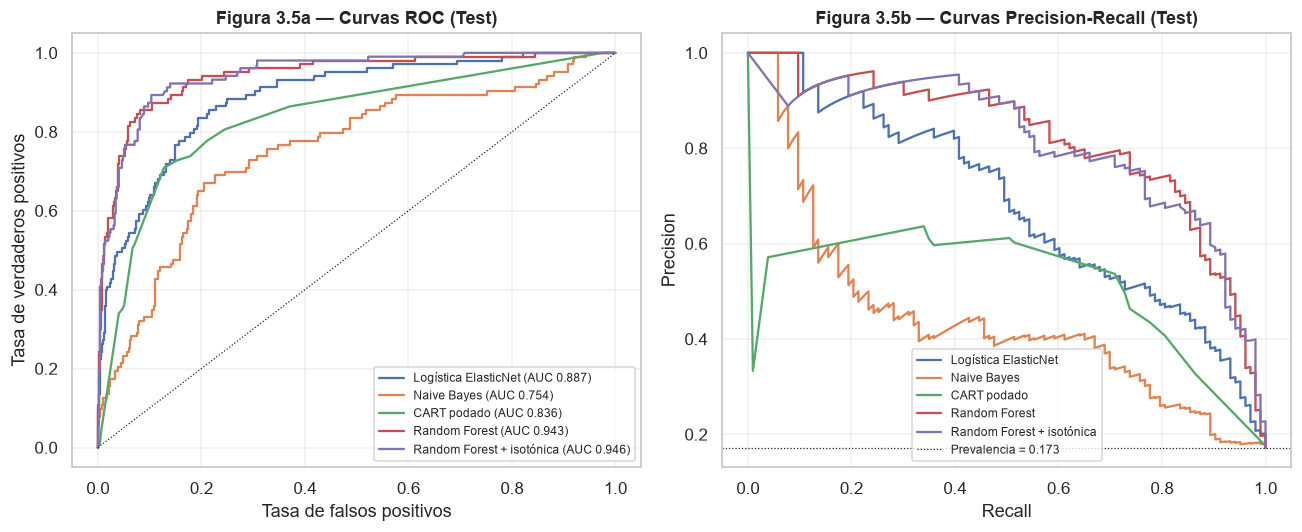

In [32]:
models = {**res["models"], f"{res['best_name']} + isotónica": res["best_calibrated"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, m in models.items():
    p = m.predict_proba(X_test[mdl.FEATURES])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {test.loc[name, 'roc_auc']:.3f})")
    axes[1].plot(rec, prec, label=name)
axes[0].plot([0, 1], [0, 1], "k:", lw=0.8)
axes[0].set(title="Figura 3.5a — Curvas ROC (Test)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=0.8, label=f"Prevalencia = {y_test.mean():.3f}")
axes[1].set(title="Figura 3.5b — Curvas Precision-Recall (Test)", xlabel="Recall", ylabel="Precision")
for a in axes:
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

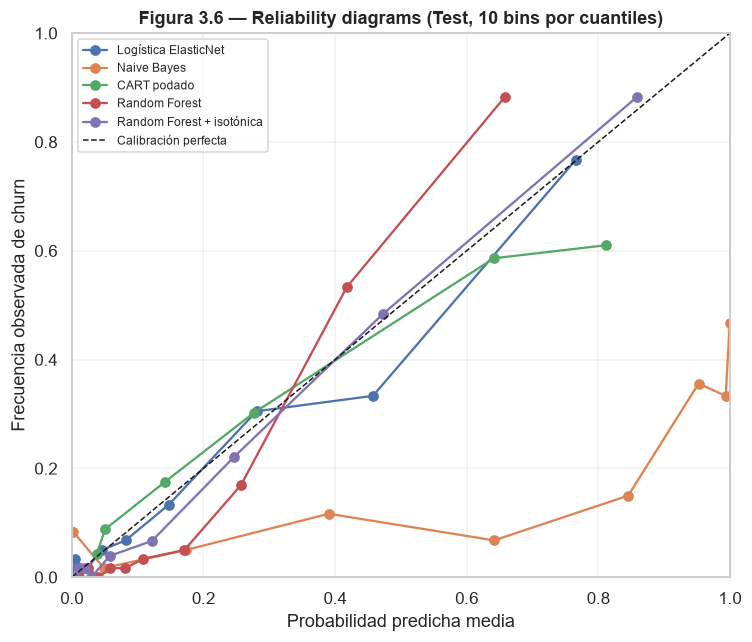

In [33]:
rel = mdl.reliability_curves(models, X_test, y_test)
fig, ax = plt.subplots(figsize=(7, 6))
for name, g in rel.groupby("modelo", sort=False):
    ax.plot(g.prob_media, g.frecuencia_observada, "o-", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Calibración perfecta")
ax.set(title="Figura 3.6 — Reliability diagrams (Test, 10 bins por cuantiles)", xlabel="Probabilidad predicha media",
       ylabel="Frecuencia observada de churn", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura:** Naive Bayes está muy por debajo de la diagonal (sobre-predice churn: Brier 0,32, ECE 0,37), consecuencia directa de la dependencia `CouponUsed`–`OrderCount` de la Tabla 3.3. El RF sin calibrar ordena muy bien pero comprime las probabilidades; la calibración isotónica lo acerca a la diagonal (ECE 0,079 → 0,018) sin perder AUC. El árbol sin podar: AUC 1,000 en Train vs 0,807 en Test, el sobreajuste esperado.

### 3.7 Explicabilidad: MDI vs Permutation Importance
**MDI (Gini)** suma, sobre todos los nodos que dividen por $X_j$, la reducción de impureza ponderada por la fracción de muestras que llegan al nodo, y promedia sobre los árboles:
$$\text{MDI}(X_j) = \frac{1}{B}\sum_{b=1}^{B}\ \sum_{t \in b:\ v(t)=j} \frac{n_t}{n}\,\Delta G(t)$$
**Sesgo:** una variable continua con $m$ valores distintos ofrece $m-1$ cortes candidatos; una dummy, uno solo. Al elegir en cada nodo el *mejor* corte entre muchos, las variables de alta cardinalidad obtienen reducciones de impureza grandes **por azar** (un problema de comparaciones múltiples), y además MDI se calcula **en Train**, de modo que también premia el sobreajuste (Strobl et al., 2007).

**Permutation importance en Test:** $\text{PI}(X_j) = \text{AUC}_{\text{Test}} - \mathbb{E}\big[\text{AUC}_{\text{Test}}(X_j \text{ permutada})\big]$. Mide la caída real de desempeño fuera de muestra, así que no depende de cuántos cortes ofrece la variable. Su limitación: con features correlacionadas reparte la importancia entre ellas.

**Experimento de control:** se agregan una columna de ruido continuo y una de ruido binario, ambas sin relación con el churn.

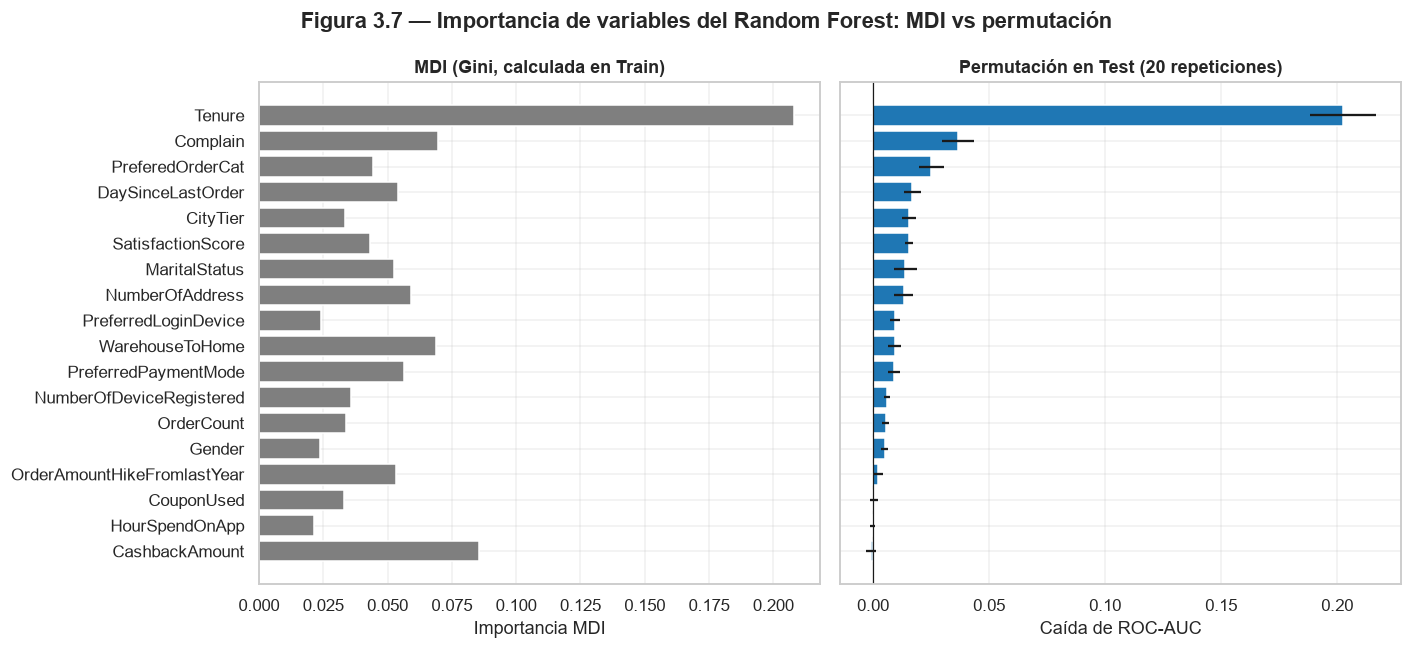

Tabla 3.5 — Rankings MDI vs permutación


,mdi,rank_mdi,perm_mean,perm_std,rank_perm
Tenure,0.2078,1,0.2024,0.0142,1
Complain,0.0697,3,0.0365,0.0068,2
PreferedOrderCat,0.0445,10,0.0251,0.0053,3
DaySinceLastOrder,0.0540,7,0.0170,0.0037,4
CityTier,0.0334,14,0.0156,0.0030,5
SatisfactionScore,0.0430,11,0.0154,0.0018,6
MaritalStatus,0.0523,9,0.0140,0.0050,7
NumberOfAddress,0.0591,5,0.0132,0.0041,8
PreferredLoginDevice,0.0243,16,0.0094,0.0022,9
WarehouseToHome,0.0689,4,0.0092,0.0029,10


In [34]:
imp = mdl.importance_mdi_vs_permutation(res["models"]["Random Forest"], X_test, y_test)
order = imp.sort_values("perm_mean").index
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
axes[0].barh(order, imp.loc[order, "mdi"], color="tab:gray")
axes[0].set(title="MDI (Gini, calculada en Train)", xlabel="Importancia MDI")
axes[1].barh(order, imp.loc[order, "perm_mean"], xerr=imp.loc[order, "perm_std"], color="tab:blue")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set(title="Permutación en Test (20 repeticiones)", xlabel="Caída de ROC-AUC")
fig.suptitle("Figura 3.7 — Importancia de variables del Random Forest: MDI vs permutación", fontweight="bold")
plt.tight_layout()
plt.show()
print("Tabla 3.5 — Rankings MDI vs permutación")
imp[["mdi", "rank_mdi", "perm_mean", "perm_std", "rank_perm"]].round(4)

In [35]:
noise = mdl.mdi_noise_experiment(res["models"]["Random Forest"], X_train, y_train, X_test, y_test)
print("Tabla 3.6 — Experimento de control con columnas de ruido (20 features)")
noise.loc[["ruido_continuo", "ruido_binario", "Tenure", "Complain", "CashbackAmount"],
          ["mdi", "rank_mdi", "perm_mean", "rank_perm"]].round(4)

Tabla 3.6 — Experimento de control con columnas de ruido (20 features)


,mdi,rank_mdi,perm_mean,rank_perm
ruido_continuo,0.0581,5,0.0001,19
ruido_binario,0.0120,20,0.0019,17
Tenure,0.1927,1,0.2094,1
Complain,0.0711,3,0.0378,2
CashbackAmount,0.0796,2,0.0003,18


**Lectura:** `CashbackAmount` (continua, cientos de valores distintos) es la **#2 por MDI** pero la **#18 por permutación** (≈ 0). El ruido continuo, que por construcción no tiene relación con el churn, recibe una importancia MDI comparable a variables reales, mientras su importancia por permutación es ≈ 0. El ruido binario, en cambio, queda último en ambas. El sesgo de cardinalidad de MDI queda así demostrado empíricamente, y la jerarquía de permutación en Test es la que se usa en la app.

### 3.8 Conclusiones de la Fase 3
- **Modelo de producción:** Random Forest + calibración isotónica. ROC-AUC Test 0,946 (IC 95% por bootstrap en la Tabla 3.4), PR-AUC 0,81, Brier 0,064, ECE 0,018. Se eligió por CV (0,932); el OOB (0,941) confirma la estimación.
- La logística (AUC 0,887) es la mejor alternativa interpretable: un reclamo multiplica las odds de churn por ≈ 7.
- **Predictores principales (permutación):** `Tenure` ≫ `Complain` > `PreferedOrderCat` > `DaySinceLastOrder`. `CouponUsed` aporta ≈ 0 a la predicción.
- **Advertencia:** que una variable prediga bien no implica que intervenirla cambie el churn. Esa pregunta se responde en la Fase 4.

---

## Sección 4 — Fase 4: Inferencia Causal Estructural (DAG, Backdoor, DoWhy) y Causal ML (EconML)

**Responsables:** Julián Agustín Lozano (Backend & ML / Causal Engineer) y Carola Nasif (Project Lead) · *(El marco conceptual, justificación arco por arco, análisis de variables latentes y amenazas a la validez interna se encuentran documentados en `BITACORA.md`, Entrada 4 §4.1–§4.3).*

**Pregunta causal:** ¿qué efecto tiene **usar cupones** ($T$ = `coupon_any` $= \mathbb{1}\{\text{CouponUsed} \ge 1\}$) sobre la probabilidad de **churn** ($Y$), una vez bloqueada la autoselección por las características del cliente ($Z$)?

**Marco de resultados potenciales.** Cada cliente tiene dos resultados potenciales, $Y_i(1)$ y $Y_i(0)$, y observamos solo uno. El estimando es
$$\text{ATE} = \tau = \mathbb{E}[Y(1) - Y(0)] = P(\text{Churn}=1 \mid do(T=1)) - P(\text{Churn}=1 \mid do(T=0)).$$
Un $\tau < 0$ significa que el cupón **retiene**. Unidad: puntos porcentuales (pp) de probabilidad de churn.

**Supuestos de identificación:**
1. **SUTVA:** el resultado de un cliente no depende del tratamiento de otros, y hay una sola versión del tratamiento.
2. **Ignorabilidad condicional:** $\{Y(1), Y(0)\} \perp T \mid Z$, es decir, no hay confusores fuera de $Z$ (supuesto no testeable).
3. **Positividad:** $0 < P(T=1 \mid Z=z) < 1$ para todo $z$ relevante (sí es testeable, sección 4.3).

Bajo 1-3, el criterio backdoor da $P(Y \mid do(T=t)) = \sum_z P(Y \mid T=t, Z=z)\,P(Z=z)$.

In [36]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "borradores" else (Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from src import causal
from src import preprocessing as prep

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

df = prep.make_clean_dataset()
r = causal.run_causal_analysis(df)   # ~1,5 min: DoWhy, refutaciones (100 sim.) y EconML
p = causal.results_payload(r)
pp = lambda x: f"{x * 100:+.2f} pp"
print(f"Clientes: {p['n']['n_total']} | con T observado: {p['n']['support']['n_antes']} | "
      f"con soporte común: {p['n']['support']['n_soporte']}")

Clientes: 2982 | con T observado: 2849 | con soporte común: 2012


### 4.1 DAG estructural
Roles (contrato de datos confirmado por el Project Lead; justificación arco por arco en la Bitácora, Entrada 4.1):
- **Z (confusores, pre-tratamiento):** antigüedad, reclamos, satisfacción, segmento geográfico y de categoría, uso de la app, medios de pago, dispositivo, demografía y logística. Cada $Z \to T$ y $Z \to Y$.
- **M (mediadores):** `OrderCount` y `CashbackAmount`. El cupón induce más pedidos y más cashback, que a su vez retienen: $T \to M \to Y$.
- **C (colisionador):** `DaySinceLastOrder`. El cupón acorta los días desde la última compra y el churn los alarga: $T \to C \leftarrow Y$.
- **U (latente, no observado):** `U_engagement`, la afinidad con la marca. Afecta el uso de la app, el uso de cupones y el churn.

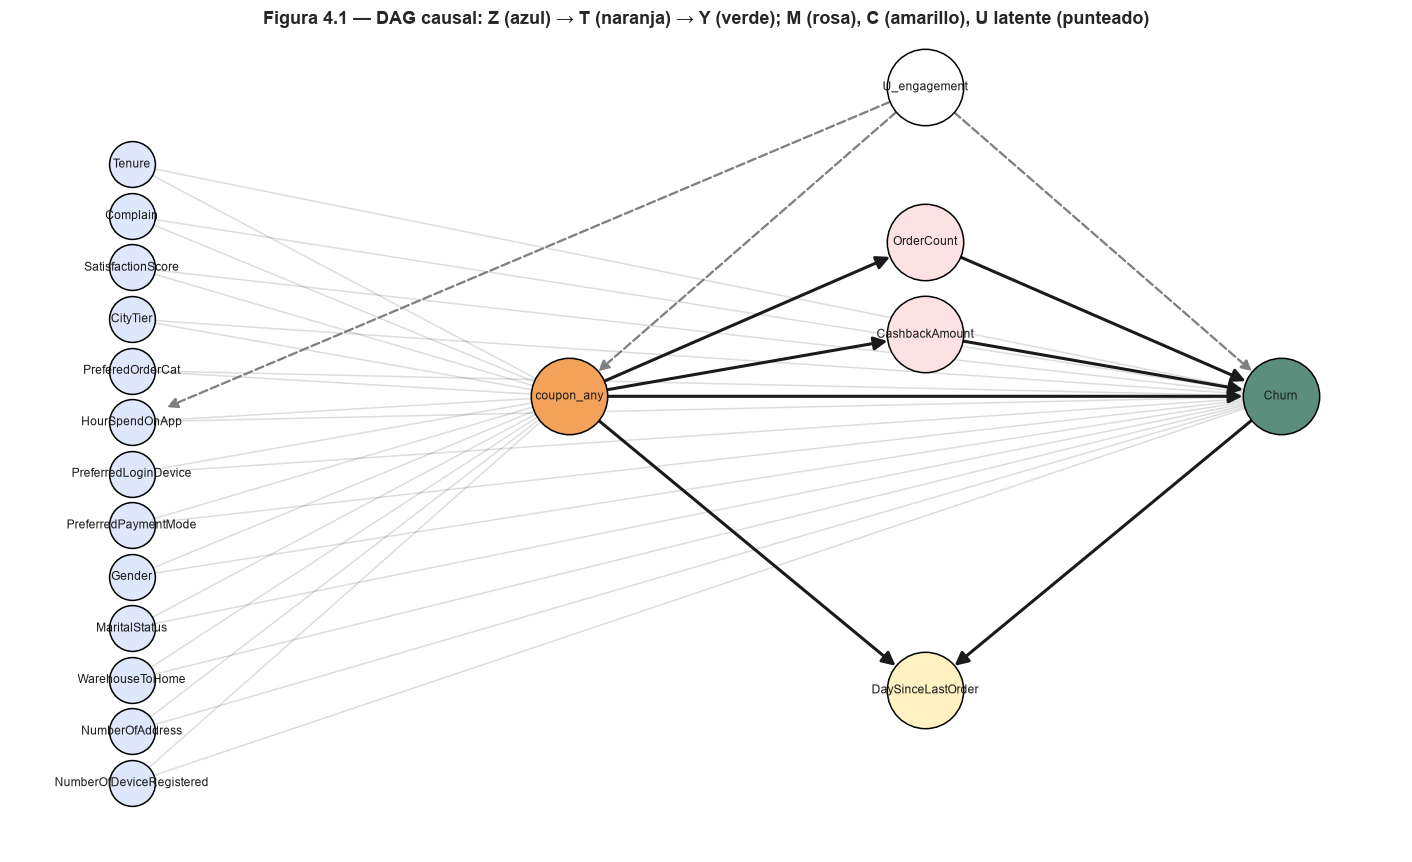

In [37]:
g = r["dag"]
roles = dict(g.nodes(data="role"))
zs = [n for n in g if roles[n] == "Z"]
pos = {n: (0, 1 - i / (len(zs) - 1) * 2) for i, n in enumerate(zs)}
pos.update({causal.TREATMENT: (1.6, 0.25), causal.OUTCOME: (4.2, 0.25), causal.LATENT: (2.9, 1.25),
            "OrderCount": (2.9, 0.75), "CashbackAmount": (2.9, 0.45), "DaySinceLastOrder": (2.9, -0.7)})
colors = {"Z": "#dfe7fd", "T": "#f4a259", "Y": "#5b8e7d", "M": "#fde2e4", "C": "#fff1c1", "U": "white"}
fig, ax = plt.subplots(figsize=(13, 8))
z_edges = [(a, b) for a, b in g.edges if roles[a] == "Z"]
other = [(a, b) for a, b in g.edges if roles[a] not in ("Z", "U")]
nx.draw_networkx_edges(g, pos, edgelist=z_edges, alpha=0.15, arrowsize=8, ax=ax)
nx.draw_networkx_edges(g, pos, edgelist=other, width=2, arrowsize=18, ax=ax, node_size=2500)
nx.draw_networkx_edges(g, pos, edgelist=list(g.out_edges(causal.LATENT)), style="dashed", width=1.5,
                       edge_color="gray", arrowsize=14, ax=ax, node_size=2500)
for role, color in colors.items():
    nodes = [n for n in g if roles[n] == role]
    nx.draw_networkx_nodes(g, pos, nodelist=nodes, node_color=color, edgecolors="black",
                           node_size=900 if role == "Z" else 2500, ax=ax)
nx.draw_networkx_labels(g, pos, font_size=8, ax=ax)
ax.set_title("Figura 4.1 — DAG causal: Z (azul) → T (naranja) → Y (verde); M (rosa), C (amarillo), U latente (punteado)")
ax.axis("off")
plt.tight_layout()
plt.show()

### 4.2 Identificación: criterio backdoor
Un conjunto $S$ cumple el criterio backdoor respecto de $(T, Y)$ si **(i)** ningún nodo de $S$ es descendiente de $T$, y **(ii)** $S$ bloquea todo camino entre $T$ e $Y$ que entra a $T$ por una flecha ($T \leftarrow \cdots$).

**Demostración para $S = Z$:** en este DAG todos los caminos backdoor tienen la forma $T \leftarrow Z_j \rightarrow Y$, una bifurcación. Condicionar en el nodo central $Z_j$ la bloquea. Ningún $Z_j$ desciende de $T$, porque son pre-tratamiento. Por lo tanto $Z$ satisface (i) y (ii). Se verifica abajo por d-separación (`networkx`) en el grafo sin las aristas salientes de $T$.

**Las trampas:**
- **Mediador** ($S = Z \cup M$): viola (i). Condicionar en $M$ bloquea $T \to M \to Y$ y se estima solo el efecto **directo**, subestimando el efecto total de la política.
- **Colisionador** ($S = Z \cup C$): viola (i). Condicionar en $C$ **abre** el camino $T \to C \leftarrow Y$ y crea una asociación espuria entre $T$ e $Y$ (sesgo de Berkson).
- **Latente** $U$: el camino $T \leftarrow U \to Y$ no puede bloquearse. Si $U$ existe, el efecto **no está identificado**, de ahí el análisis de sensibilidad (sección 4.6).

In [38]:
bd = p["backdoor"]
rows = [("Z (13 confusores), sin U", bd["sin_latente"]), ("Z, con U en el DAG", bd["con_latente"]),
        ("Z + M (mediadores)", bd["Z+M"]), ("Z + C (colisionador)", bd["Z+C"])]
print("Tabla 4.1 — Verificación del criterio backdoor por d-separación")
display(pd.DataFrame([{"conjunto": n, "(i) sin descendientes de T": b["no_descendants_of_T"],
                       "(ii) bloquea backdoor": b["blocks_all_backdoor_paths"], "cumple": b["satisfied"],
                       "descendientes incluidos": ", ".join(b["descendants_in_set"]) or "—"} for n, b in rows]))
print(f"Caminos backdoor (sin U): {len(bd['caminos'])}, por ejemplo: {bd['caminos'][:3]}")
print(f"DoWhy identifica un set de {len(p['dowhy_backdoor_set'])} columnas codificadas; "
      f"¿incluye M o C? {bool(set(p['dowhy_backdoor_set']) & set(prep.MEDIATORS + prep.COLLIDERS))}")

Tabla 4.1 — Verificación del criterio backdoor por d-separación


,conjunto,(i) sin descendientes de T,(ii) bloquea backdoor,cumple,descendientes incluidos
0,"Z (13 confusores), sin U",True,True,True,—
1,"Z, con U en el DAG",True,False,False,—
2,Z + M (mediadores),False,False,False,"CashbackAmount, OrderCount"
3,Z + C (colisionador),False,False,False,DaySinceLastOrder


Caminos backdoor (sin U): 13, por ejemplo: ['coupon_any - Tenure - Churn', 'coupon_any - Complain - Churn', 'coupon_any - SatisfactionScore - Churn']
DoWhy identifica un set de 29 columnas codificadas; ¿incluye M o C? False


In [39]:
print(r["estimand"])

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
      d                                                                        ↪
─────────────(E[Churn|MaritalStatus_Married,Tenure,PreferredPaymentMode_Debit_ ↪
d[coupon_any]                                                                  ↪

↪                                                                              ↪
↪ Card,MaritalStatus_Single,PreferedOrderCat_Laptop_and_Accessory,CityTier_3,P ↪
↪                                                                              ↪

↪                                                                              ↪
↪ referedOrderCat_Grocery,NumberOfDeviceRegistered_2,HourSpendOnApp_2,HourSpen ↪
↪                                                                              ↪

↪                                                                              ↪
↪ dOnApp_1,PreferedOrderCat_Others,SatisfactionScore,NumberOfAddress,Preferred

### 4.3 Positividad y soporte común
La positividad exige que, para cada perfil $z$, haya clientes con y sin cupón. En este dataset hay **estratos enteros donde el 100% usó cupón**: ahí no existe contrafáctico observable, y cualquier estimación sería pura extrapolación del modelo. Se procede en dos pasos:
1. Se excluyen los estratos con ≥ 20 clientes y sin variación en $T$.
2. Se recortan los clientes con propensity $\hat e(z) = P(T=1 \mid Z=z)$ fuera de $[0{,}05;\ 0{,}95]$.

El ATE resultante es el de la **población con soporte común**, y así se informa.

Tabla 4.2 — Estratos sin contrafáctico (todos tratados)


,variable,nivel,n,share_tratados
0,Tenure,31.0,23,1.0000
1,HourSpendOnApp,4.0,605,1.0000
2,WarehouseToHome,36.0,25,1.0000
3,WarehouseToHome,7.0,202,1.0000
4,NumberOfAddress,11,49,1.0000
5,NumberOfDeviceRegistered,6,87,1.0000


Excluidos por estratos: 808 | por trimming: 29 | población final: 2012


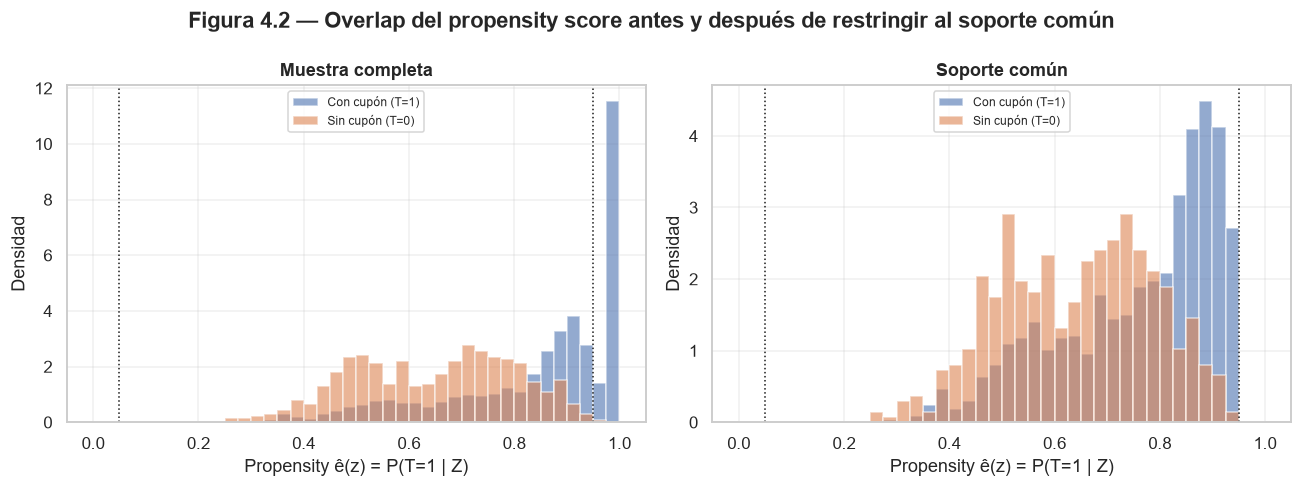

Fuera de [0,05; 0,95] en la muestra completa: 26.1%


In [40]:
s = p["n"]["support"]
print("Tabla 4.2 — Estratos sin contrafáctico (todos tratados)")
display(pd.DataFrame(s["estratos_excluidos"]))
print(f"Excluidos por estratos: {s['n_excluidos_estratos']} | por trimming: {s['n_excluidos_trimming']} | "
      f"población final: {s['n_soporte']}")

frame_full, info_full = causal.prepare_causal_frame(df)
ps_full = causal.propensity_scores(frame_full, info_full["z_cols"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
for ax, (title, f, ps) in zip(axes, [("Muestra completa", frame_full, ps_full),
                                      ("Soporte común", r["frame"], r["propensity"])]):
    t = f[causal.TREATMENT].to_numpy()
    bins = np.linspace(0, 1, 41)
    ax.hist(ps[t == 1], bins=bins, alpha=0.6, density=True, label="Con cupón (T=1)")
    ax.hist(ps[t == 0], bins=bins, alpha=0.6, density=True, label="Sin cupón (T=0)")
    for b in causal.PS_BOUNDS:
        ax.axvline(b, color="k", ls=":", lw=1)
    ax.set(title=title, xlabel="Propensity ê(z) = P(T=1 | Z)", ylabel="Densidad")
    ax.legend(fontsize=8)
fig.suptitle("Figura 4.2 — Overlap del propensity score antes y después de restringir al soporte común", fontweight="bold")
plt.tight_layout()
plt.show()
print(f"Fuera de [0,05; 0,95] en la muestra completa: {p['overlap_full_sample']['share_outside_05_95']:.1%}")

**Balance de covariables.** La diferencia de medias estandarizada, $\text{SMD}_j = (\bar z_{j,1} - \bar z_{j,0}) / \sqrt{(s^2_{j,1} + s^2_{j,0})/2}$, se calcula antes y después de ponderar por IPW ($w_i = T_i/\hat e_i + (1-T_i)/(1-\hat e_i)$). Criterio usual: $|\text{SMD}| < 0{,}1$.

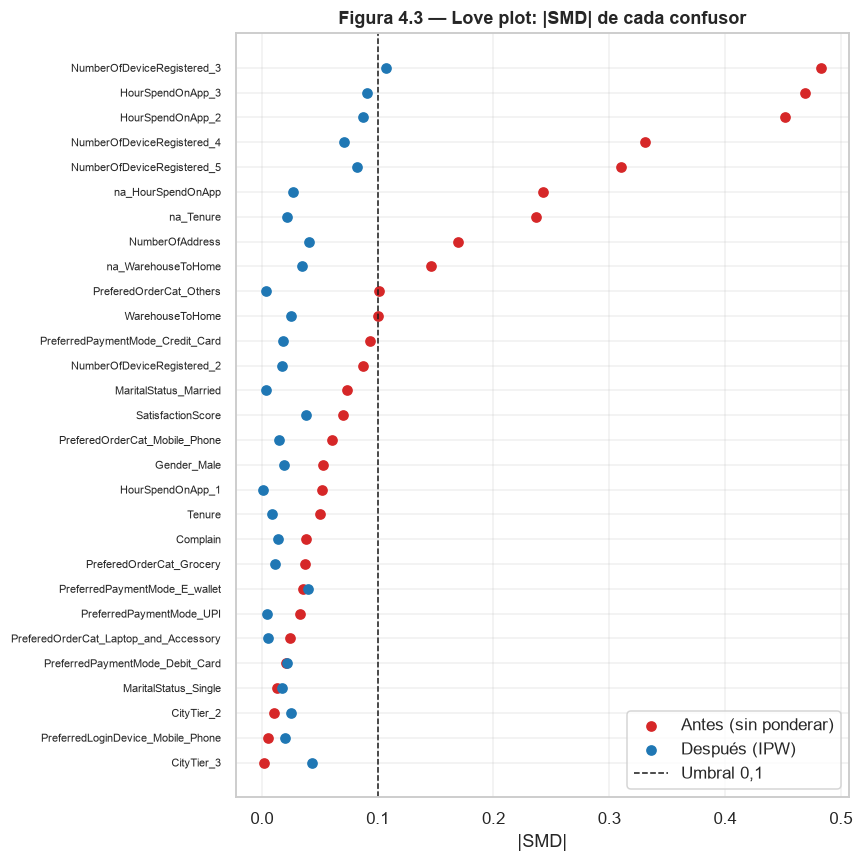

max |SMD|: 0.483 → 0.107; variables con |SMD| > 0,1: 11 → 1


In [41]:
bal = r["balance"]
order = bal.smd_antes.abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(bal.loc[order, "smd_antes"].abs(), order, label="Antes (sin ponderar)", color="tab:red")
ax.scatter(bal.loc[order, "smd_despues"].abs(), order, label="Después (IPW)", color="tab:blue")
ax.axvline(0.1, color="k", ls="--", lw=1, label="Umbral 0,1")
ax.set(title="Figura 4.3 — Love plot: |SMD| de cada confusor", xlabel="|SMD|")
ax.tick_params(axis="y", labelsize=7)
ax.legend()
plt.tight_layout()
plt.show()
print(f"max |SMD|: {p['balance']['max_abs_smd_antes']:.3f} → {p['balance']['max_abs_smd_despues']:.3f}; "
      f"variables con |SMD| > 0,1: {p['balance']['n_smd_mayor_0_1_antes']} → {p['balance']['n_smd_mayor_0_1_despues']}")

### 4.4 Estimación en 4 pasos con DoWhy y comparación con el estimador ingenuo
1. **Model:** `CausalModel(data, treatment, outcome, graph)` con el DAG en las columnas codificadas.
2. **Identify:** `identify_effect()` devuelve el estimando backdoor de arriba.
3. **Estimate:**
   - `backdoor.linear_regression`: modelo de probabilidad lineal $Y = \alpha + \tau T + Z^\top\gamma + \varepsilon$; $\hat\tau$ es el ATE en pp.
   - `backdoor.propensity_score_weighting` (IPW): $\hat\tau = \frac{\sum_i T_i Y_i/\hat e_i}{\sum_i T_i/\hat e_i} - \frac{\sum_i (1-T_i) Y_i/(1-\hat e_i)}{\sum_i (1-T_i)/(1-\hat e_i)}$.
4. **Comparar** con la regresión ingenua $Y \sim T$. El **sesgo de confusión** es $\hat\tau_{\text{ingenuo}} - \hat\tau_{\text{ajustado}}$.

Se agregan los dos estimadores de EconML (sección 4.7) y las dos "trampas".

Tabla 4.3 — Estimaciones del efecto de usar cupón sobre la probabilidad de churn (pp)


,ATE (pp),IC 95% inf,IC 95% sup
Ingenuo (Y ~ T),-0.3500,-4.1500,3.4500
Backdoor: regresión lineal,-1.1600,-4.6000,2.2800
Backdoor: IPW,-1.0900,-5.5600,3.1400
LinearDML (EconML),1.1100,-2.0300,4.2400
CausalForestDML (EconML),1.4200,-1.4600,4.2900
Con M (trampa del mediador),-2.3900,-5.9100,1.1300
Con C (trampa del colisionador),-0.7400,-4.1500,2.6800
Regresión en muestra completa (extrapola),-1.1700,-4.5500,2.2100
T continua: por cupón adicional,1.0700,0.1400,2.0000


Tasas de churn (ingenuo): con cupón 18.0% vs sin cupón 18.4%
Sesgo de confusión (ingenuo − regresión backdoor): +0.81 pp


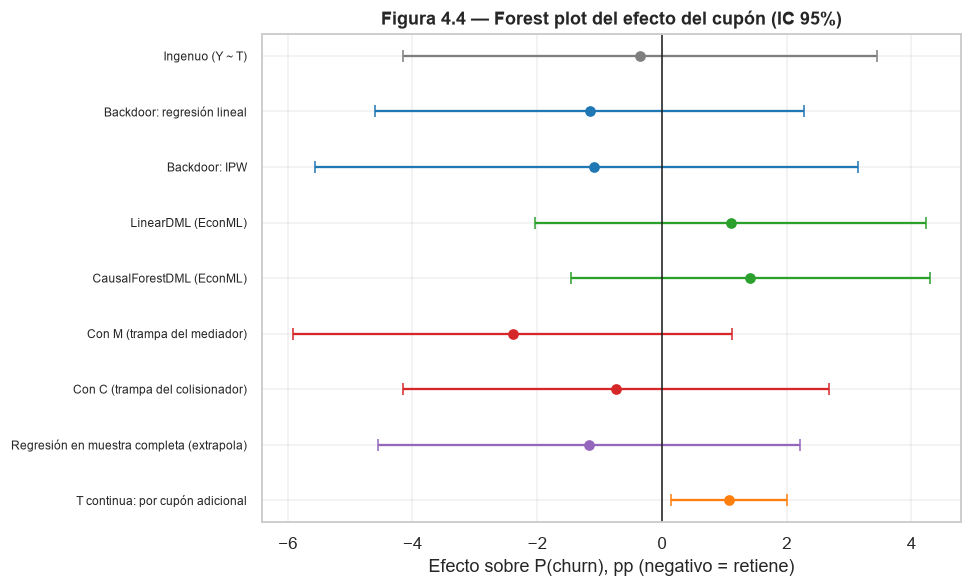

In [42]:
est = pd.DataFrame(p["estimates"]).T
est["ATE (pp)"] = est.ate * 100
est["IC 95% inf"] = est.ci.str[0] * 100
est["IC 95% sup"] = est.ci.str[1] * 100
est = est[["ATE (pp)", "IC 95% inf", "IC 95% sup"]].astype(float)
dr = p["dose_response_per_coupon"]
est.loc["T continua: por cupón adicional"] = [dr["ate"] * 100, dr["ci"][0] * 100, dr["ci"][1] * 100]
print("Tabla 4.3 — Estimaciones del efecto de usar cupón sobre la probabilidad de churn (pp)")
display(est.round(2))
print(f"Tasas de churn (ingenuo): con cupón {p['naive_churn_rates']['T=1']:.1%} vs sin cupón {p['naive_churn_rates']['T=0']:.1%}")
print(f"Sesgo de confusión (ingenuo − regresión backdoor): {pp(p['confounding_bias'])}")

colors = ["tab:gray", "tab:blue", "tab:blue", "tab:green", "tab:green", "tab:red", "tab:red", "tab:purple", "tab:orange"]
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(est))[::-1]
for yi, (_, row), color in zip(y, est.iterrows(), colors):
    ax.errorbar(row["ATE (pp)"], yi, xerr=[[row["ATE (pp)"] - row["IC 95% inf"]], [row["IC 95% sup"] - row["ATE (pp)"]]],
                fmt="o", color=color, capsize=4)
ax.axvline(0, color="k", lw=1)
ax.set_yticks(y, est.index, fontsize=8)
ax.set(title="Figura 4.4 — Forest plot del efecto del cupón (IC 95%)", xlabel="Efecto sobre P(churn), pp (negativo = retiene)")
plt.tight_layout()
plt.show()

In [43]:
sim = p["collider_simulation"]
print("Tabla 4.4 — Simulación del sesgo de colisionador (efecto verdadero conocido, n = 20.000)")
pd.DataFrame({"estimación": [sim["true_effect"], sim["estimate_without_C"], sim["estimate_with_C"]]},
             index=["efecto verdadero", "Y ~ T (correcto)", "Y ~ T + C (condiciona en el colisionador)"]).round(3)

Tabla 4.4 — Simulación del sesgo de colisionador (efecto verdadero conocido, n = 20.000)


,estimación
efecto verdadero,0.1000
Y ~ T (correcto),0.1000
Y ~ T + C (condiciona en el colisionador),-0.4630


**Lectura:**
- El ATE ajustado es **≈ 0** con todos los estimadores; todos los IC 95% incluyen 0.
- El sesgo de confusión es chico (+0,8 pp) porque los confusores observados casi no predicen el uso de cupón: por ejemplo, la correlación `Complain`–T es −0,02.
- Las trampas mueven la estimación en la dirección que predice la teoría, aunque sin significancia en estos datos:
  - Con M, −2,4 pp, el efecto "directo" una vez bloqueado el canal de pedidos y cashback.
  - Con C, −0,7 pp.
  - En la simulación con efecto conocido, condicionar en el colisionador cambia incluso el **signo**: +0,10 → −0,46.
- **Dosis-respuesta:** cada cupón adicional se asocia con +1,07 pp de churn (IC [+0,14; +2,00]), ajustando por Z. Lo más plausible es causalidad inversa o confusión no observada (por ejemplo, clientes "cazadores de ofertas" con baja lealtad), más que un efecto dañino del cupón.

### 4.5 Refutaciones (DoWhy) y semáforo
| Refutador | Qué hace | Expectativa |
|---|---|---|
| Random Common Cause | agrega un confusor aleatorio independiente | el ATE no se mueve |
| Placebo Treatment | reemplaza $T$ por una permutación aleatoria | el ATE → 0 |
| Data Subset | re-estima en submuestras del 80% | el ATE queda dentro del IC original |

Cada uno se corre con 100 simulaciones.

In [44]:
icon = {"verde": "🟢", "amarillo": "🟡", "rojo": "🔴"}
refs = pd.DataFrame(p["refutations"])
refs["ATE original (pp)"] = refs.ate_original * 100
refs["ATE refutado (pp)"] = refs.ate_nuevo * 100
refs["semáforo"] = refs.semaforo.map(lambda c: f"{icon[c]} {c}")
print("Tabla 4.5 — Refutaciones del estimador principal (regresión backdoor)")
refs[["refutador", "ATE original (pp)", "ATE refutado (pp)", "p_value_dowhy", "semáforo", "interpretacion"]].round(3)

Tabla 4.5 — Refutaciones del estimador principal (regresión backdoor)


,refutador,ATE original (pp),ATE refutado (pp),p_value_dowhy,semáforo,interpretacion
0,Random Common Cause,-1.1590,-1.1600,0.9000,🟢 verde,Agregar un confusor aleatorio no debería mover...
1,Placebo Treatment,-1.1590,0.0930,0.9600,🟢 verde,Con T permutado al azar el efecto debe ser ≈ 0.
2,Data Subset (80%),-1.1590,-0.9850,0.8800,🟢 verde,Re-estimar en submuestras del 80% debe dejar e...


### 4.6 Sensibilidad a un confusor no observado
El backdoor descansa en que no exista $U$ (sección 4.2). `add_unobserved_common_cause` simula un confusor con efectos de intensidad 0,01-0,10 sobre $T$ (cambiando el tratamiento de una fracción de clientes) y sobre $Y$ (lineal), y re-estima el ATE.

In [45]:
sens = p["sensitivity_unobserved"]
print(f"Con un confusor no observado de intensidad {sens['strengths']}, el ATE varía entre "
      f"{pp(sens['ate_min'])} y {pp(sens['ate_max'])} (estimación original: {pp(p['estimates']['Backdoor: regresión lineal']['ate'])}).")

Con un confusor no observado de intensidad [0.01, 0.05, 0.1], el ATE varía entre -1.75 pp y +6.17 pp (estimación original: -1.16 pp).


**Lectura:** un confusor de intensidad moderada alcanza para llevar el ATE a +6 pp. La conclusión "no hay evidencia de efecto protector" es robusta, pero **no** permite afirmar un efecto exactamente nulo: la confusión no observada (`U_engagement`, sensibilidad al precio) es la principal amenaza a la validez interna (Bitácora, Entrada 4.3).

### 4.7 Causal ML: Double Machine Learning y heterogeneidad (CATE)
Modelo parcialmente lineal con efecto heterogéneo:
$$Y = \theta(X)\,T + g(X, W) + \varepsilon, \qquad T = m(X, W) + \eta,$$
donde $X$ = modificadores de efecto interpretables (`Tenure`, `Complain`, `SatisfactionScore`) y $W$ = resto de los confusores.

**Ortogonalización (Neyman / Frisch-Waugh-Lovell):**
1. Se predicen $\hat g = \mathbb{E}[Y \mid X, W]$ y $\hat m = \mathbb{E}[T \mid X, W]$ con **Random Forest** (modelos *nuisance*), con **cross-fitting** de 5 folds: cada predicción se hace con modelos que no vieron esa observación.
2. Se residualiza: $\tilde Y = Y - \hat g$ y $\tilde T = T - \hat m$.
3. Se estima $\theta(X)$ regresando $\tilde Y$ sobre $\tilde T$ (LinearDML: $\theta$ lineal en $X$; CausalForestDML: $\theta$ no paramétrico).

Como la condición de momento es ortogonal, los errores de primer orden en $\hat g$ y $\hat m$ no sesgan $\hat\theta$.

**CATE:** $\tau(x) = \mathbb{E}[Y(1) - Y(0) \mid X = x]$.

In [46]:
coefs = pd.DataFrame(p["linear_dml_coefs"]).set_index("")
print("Tabla 4.6 — LinearDML: θ(X) = θ0 + X'β (efecto marginal de cada modificador sobre el CATE)")
display(coefs)
print(f"ATE LinearDML: {pp(p['estimates']['LinearDML (EconML)']['ate'])} | "
      f"ATE CausalForestDML: {pp(p['estimates']['CausalForestDML (EconML)']['ate'])}")

Tabla 4.6 — LinearDML: θ(X) = θ0 + X'β (efecto marginal de cada modificador sobre el CATE)


,point_estimate,stderr,zstat,pvalue,ci_lower,ci_upper
,,,,,,
Tenure,0.0010,0.0020,0.2850,0.7760,-0.0030,0.0040
Complain,0.0710,0.0380,1.8420,0.0650,-0.0050,0.1460
SatisfactionScore,0.0100,0.0120,0.7990,0.4240,-0.0140,0.0340


ATE LinearDML: +1.11 pp | ATE CausalForestDML: +1.42 pp


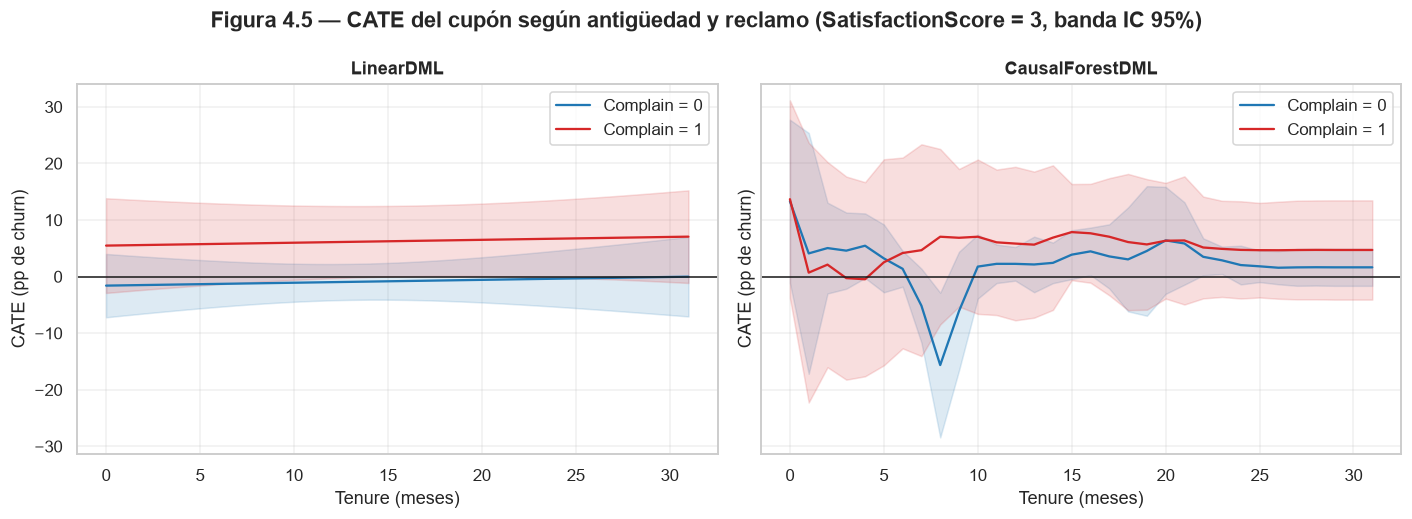

In [47]:
grid = causal.cate_grid(r["dml"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, est_name, label in [(axes[0], "linear_dml", "LinearDML"), (axes[1], "causal_forest", "CausalForestDML")]:
    for complain, color in [(0, "tab:blue"), (1, "tab:red")]:
        g = grid[(grid.Complain == complain) & (grid.SatisfactionScore == 3)]
        ax.plot(g.Tenure, g[f"cate_{est_name}"] * 100, color=color, label=f"Complain = {complain}")
        ax.fill_between(g.Tenure, g[f"ci_inf_{est_name}"] * 100, g[f"ci_sup_{est_name}"] * 100, color=color, alpha=0.15)
    ax.axhline(0, color="k", lw=1)
    ax.set(title=label, xlabel="Tenure (meses)", ylabel="CATE (pp de churn)")
    ax.legend()
fig.suptitle("Figura 4.5 — CATE del cupón según antigüedad y reclamo (SatisfactionScore = 3, banda IC 95%)",
             fontweight="bold")
plt.tight_layout()
plt.show()

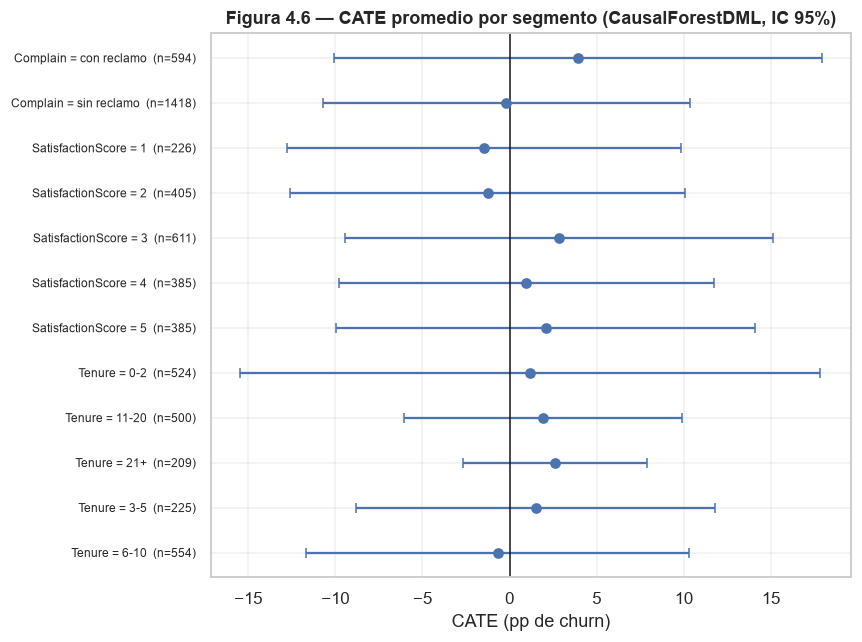

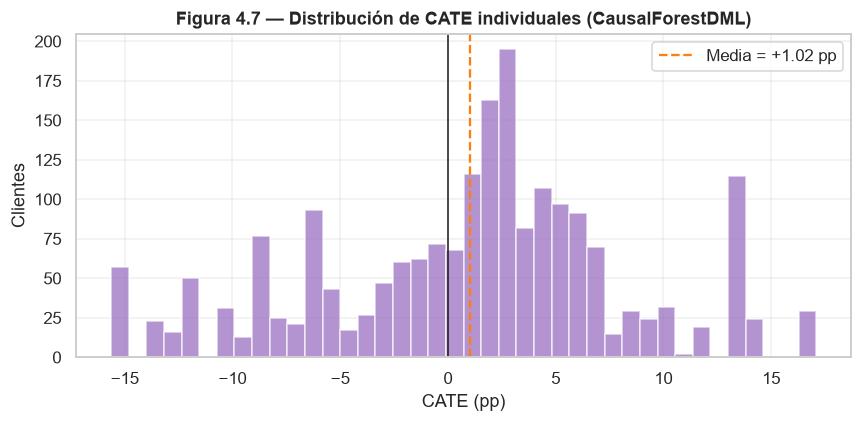

Política 'dar cupón solo si CATE < 0': {'share_cate_negativo': 0.366, 'efecto_medio_dar_a_todos_pp': 1.024, 'efecto_medio_solo_cate_negativo_pp': -6.547, 'churn_evitado_por_100_clientes_targeting': 2.395}


In [48]:
sub = pd.DataFrame(p["cate_subgroups"])
sub["etiqueta"] = sub.variable + " = " + sub.segmento
fig, ax = plt.subplots(figsize=(8, 6))
yy = np.arange(len(sub))[::-1]
ax.errorbar(sub.cate * 100, yy, xerr=[(sub.cate - sub.ci_inf) * 100, (sub.ci_sup - sub.cate) * 100], fmt="o", capsize=3)
ax.axvline(0, color="k", lw=1)
ax.set_yticks(yy, sub.etiqueta + "  (n=" + sub.n.astype(str) + ")", fontsize=8)
ax.set(title="Figura 4.6 — CATE promedio por segmento (CausalForestDML, IC 95%)", xlabel="CATE (pp de churn)")
plt.tight_layout()
plt.show()

cate = np.asarray(r["dml"]["cate_individual"]) * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cate, bins=40, color="tab:purple", alpha=0.7)
ax.axvline(0, color="k", lw=1)
ax.axvline(cate.mean(), color="tab:orange", ls="--", label=f"Media = {cate.mean():+.2f} pp")
ax.set(title="Figura 4.7 — Distribución de CATE individuales (CausalForestDML)", xlabel="CATE (pp)", ylabel="Clientes")
ax.legend()
plt.tight_layout()
plt.show()
print("Política 'dar cupón solo si CATE < 0':", {k: round(v, 3) for k, v in p["policy"].items()})

**Lectura:** ningún modificador es significativo. El más cercano es `Complain`, con +7,1 pp (p = 0,065): en clientes con reclamo, el cupón no retiene y tiende a asociarse con más churn, consistente con cupones "compensatorios" que no resuelven la causa del reclamo. Todos los IC por segmento incluyen 0. La dispersión de los CATE individuales (Figura 4.7) es en buena parte ruido de estimación: una política de *targeting* basada en esos CATE (36% de clientes con CATE < 0) **no se recomienda** sin validación experimental.

### 4.8 Conclusión de la Fase 4
En la población con soporte común (N = 2.012), **no hay evidencia de que usar cupones reduzca el churn**:
- Regresión backdoor: −1,16 pp (IC 95% [−4,60; +2,28]).
- IPW −1,09 pp, LinearDML +1,11 pp, CausalForestDML +1,42 pp.
- Las 3 refutaciones pasan.

**H-causal-1** (efecto protector menor al ingenuo) y **H-causal-2** (inversión de signo por cupones compensatorios) **no se sostienen**: la confusión observada es débil. La principal amenaza es la confusión no observada, y la forma de resolverla es un **experimento aleatorizado** (A/B) del incentivo, que además elimina el problema de positividad.

---

## Sección 5 — Ensayo Crítico: Capacidad Predictiva vs. Palanca Causal

**Responsables:** Carola Nasif (Project Lead & Scrum Master) y Julián Agustín Lozano (Backend & ML / Causal Engineer)

**1. La variable más predictiva no es una palanca.** En el Random Forest de la Fase 3, `Tenure` es por lejos la variable más importante: permutarla en Test hace caer el ROC-AUC ≈ 0,20 puntos, más de cinco veces lo que cae al permutar la segunda (`Complain`). Pero la antigüedad **no es intervenible**: la empresa no puede "hacer más antiguo" a un cliente. Describe *quién* se va, no *qué hacer* para que se quede. Lo mismo ocurre con `DaySinceLastOrder` (#4 en predicción). En el DAG es un **colisionador y descendiente del churn**, es decir, una consecuencia de que el cliente ya se está yendo. Predice bien precisamente porque es un síntoma, y "reducir los días desde la última compra" no es una política: es el resultado que se quiere lograr. Incluso `Complain` (#2, OR ≈ 7) es una señal de alerta, no una perilla: la palanca es la **causa** del reclamo (logística, calidad), no el reclamo en sí.

**2. Cuándo un gran predictor carece de poder causal.**
- **Confusión:** $X$ y $Y$ comparten una causa común. Por ejemplo, si el engagement no observado (`U_engagement`) aumenta a la vez el uso de la app y la permanencia, `HourSpendOnApp` predice el churn sin ser una palanca.
- **Causalidad inversa:** $Y \to X$. La intención de irse aumenta los días sin comprar.
- **Colisionadores y descendientes de $Y$:** incluirlos mejora la predicción pero sesga cualquier lectura causal. En la simulación de la Fase 4, condicionar en un colisionador **invierte el signo** de un efecto verdadero de +0,10 a −0,46.
- **Proxies:** variables que solo "etiquetan" un segmento.

En todos estos casos $P(Y \mid X)$ es informativa, pero $P(Y \mid do(X))$ puede ser nula o tener el **signo opuesto**.

**3. El caso del cupón.** El cupón aporta ≈ 0 a la predicción (`CouponUsed` #16 por permutación) y su efecto causal estimado es ≈ 0 (−1,2 pp, IC [−4,6; +2,3]). Sin embargo, la *intensidad* de uso se asocia con **más** churn (+1,1 pp por cupón), incluso ajustando por Z. Leer ese coeficiente como causal ("los cupones espantan clientes") sería tan erróneo como la lectura ingenua original ("los clientes con cupones se quedan, entonces los cupones retienen"). La explicación más plausible es la autoselección de clientes sensibles al precio, una variable que no observamos. Además, 808 clientes están en perfiles donde **todos** usaron cupón: para ellos ningún análisis observacional puede decir qué habría pasado sin cupón.

**4. Implicancia de negocio.** *Targeting* por **probabilidad de churn** (predictivo) ≠ *targeting* por **uplift / CATE** (causal). Un cliente con alta probabilidad de irse puede ser un "lost cause" al que el cupón no cambia nada. Uno con baja probabilidad puede ser un "sure thing" que lo usaría igual, y el cupón regalaría margen. Solo los "persuadables" (CATE < 0) justifican el gasto, y los "sleeping dogs" (CATE > 0) empeoran con él.

Recomendación:
- Usar el modelo predictivo calibrado para **detectar** clientes en riesgo y priorizar la atención de reclamos.
- No escalar la política de cupones sobre la base de la correlación observada.
- Validar cualquier incentivo con un **experimento A/B**, que garantiza positividad e ignorabilidad por diseño.
- Con costo de cupón $c$ y valor de retener a un cliente $V$, el cupón conviene solo si $-\tau \cdot V > c$. Aun en el extremo favorable del IC ($\tau = -4{,}6$ pp) se requiere $c < 0{,}046\,V$.

---

## Sección 6 — Conclusiones Ejecutivas y Recomendación de Política Comercial

**Responsable:** Carola Nasif (Project Lead & Scrum Master) · **Fuentes verificadas:** [`artifacts/model_results.json`](../artifacts/model_results.json) (Fase 3, PR #12) y [`artifacts/causal_results.json`](../artifacts/causal_results.json) (Fase 4, PR #13).

> **Conclusión ejecutiva central:** El sistema **predice con alta precisión quién está en riesgo de abandonar** ($\text{ROC-AUC Test} = 0{,}946$, calibración isotónica $\text{ECE} = 0{,}018$), pero **no existe evidencia causal de que usar cupones reduzca el churn**: en la población con soporte común ($N = 2.012$), el efecto medio estimado por regresión *backdoor* es **$\widehat{\text{ATE}} = -1{,}16\text{ pp}$ (IC 95% $[-4{,}60;\, +2{,}28]\text{ pp}$)**, todos los estimadores principales contienen el $0$ en su IC 95% y la dosis-respuesta por cupón adicional resulta positiva ($+1{,}07\text{ pp}$). Por lo tanto, **no se recomienda utilizar cupones masivos ni asignarlos automáticamente a los clientes de mayor riesgo predictivo**; se debe utilizar el modelo para detección temprana, reasignar presupuesto hacia experiencia de usuario y resolución de reclamos, y validar cualquier incentivo mediante un **experimento A/B aleatorio (`RCT`)**.

---

### 6.1 Síntesis Empírica: Capacidad Predictiva ($\mathbb{P}(Y \mid X)$) vs. Palanca Causal ($\mathbb{P}(Y \mid \text{do}(T))$)

#### A. Evidencia predictiva (Fase 3 — *What-Is*, Train $N = 2.385$ / Test $N = 597$)

Sobre el universo depurado ($N = 2.982$, tras remover las $2.638$ copias casi duplicadas `ID + 1470` que inflaban artificialmente el ROC-AUC de `0,993` a `0,948` en CV por *fold-leakage*), la selección por `StratifiedKFold(5)` exclusivamente en Train corona al **Random Forest + calibración isotónica** (validación cruzada `5-fold` en Train). Evaluado una única vez en Test ($N = 597$):

* **Modelo ganador (`Random Forest + isotónica`):** `ROC-AUC Test = 0,946` (`0,9461`, IC 95% `[0,9218; 0,9676]`), `PR-AUC = 0,8062`, **`Brier = 0,064`** (`0,0643`, mejora frente a `0,0716` sin calibrar) y **`ECE = 0,018`** (`0,0179`, mejora de $77\%$ en error de calibración frente a `0,0790` sin calibrar).
* **Variables más importantes por permutación sobre Test ($\Delta\text{ROC-AUC}$):**
  1. `Tenure` ($0{,}2024 \pm 0{,}0142$, puesto `#1` en permutación y `#1` en MDI) — primer mes/antigüedad concentra el grueso del riesgo de abandono.
  2. `Complain` ($0{,}0365 \pm 0{,}0068$, puesto `#2` en permutación vs. `#3` en MDI) — la presencia de reclamos sin resolver dispara la propensión al churn.
  3. `PreferedOrderCat` ($0{,}0251 \pm 0{,}0053$, puesto `#3` en permutación vs. `#10` en MDI).
  4. `DaySinceLastOrder` ($0{,}0170 \pm 0{,}0037$, puesto `#4` en permutación vs. `#7` en MDI; recordando que en Fase 4 es colisionador $C$ y **queda excluida** del set causal).
* **Sesgo de cardinalidad en MDI:** `CashbackAmount` figura `#2` en MDI (`0,0857`), pero cae al puesto **`#18` (último, $-0{,}0010$)** por permutación en Test; análogamente, `CouponUsed` queda `#16` ($+0{,}0003$), anticipando la escasa capacidad causal propia del uso de cupones.

**Tabla 6.1 — Resumen del torneo predictivo (Fase 3: CV sobre Train $N = 2.385$ y evaluación única en Test $N = 597$):**

| Modelo | CV ROC-AUC | Test ROC-AUC (IC 95%) | Test PR-AUC | Test Brier | Test ECE | Lectura metodológica |
|---|---:|---:|---:|---:|---:|---|
| **Random Forest + isotónica** | — *(calibrado en Train)* | **0,9461** `[0,9218; 0,9676]` | 0,8062 | **0,0643** | **0,0179** | Modelo productivo para riesgo $\mathbb{P}(Y \mid X)$ |
| **Random Forest** *(sin calibrar, OOB AUC = 0,9411)* | 0,9320 ± 0,0147 | 0,9434 `[0,9163; 0,9677]` | **0,8194** | 0,0716 | 0,0790 | Excelente discriminación; requiere calibración |
| **Logística ElasticNet** ($\alpha=0, C=100$) | 0,8935 ± 0,0061 | 0,8870 `[0,8519; 0,9207]` | 0,6817 | 0,0895 | 0,0225 | Baseline lineal bien calibrado e interpretable |
| **CART podado** ($\text{ccp\_alpha}=0{,}0019$) | 0,8477 ± 0,0222 | 0,8355 `[0,7933; 0,8792]` | 0,5079 | 0,1070 | 0,0485 | Reglas explícitas; evita sobreajuste de Train |
| **CART sin podar** | — | 0,8066 `[0,7602; 0,8488]` | 0,4705 | 0,1357 | 0,0385 | Sobreajuste severo (`Train AUC = 1,0000`) |
| **Naive Bayes** *(Gaussiano)* | 0,7857 ± 0,0194 | 0,7544 `[0,6985; 0,8051]` | 0,4427 | 0,3223 | 0,3650 | Descalibración extrema por dependencia `OrderCount–CouponUsed` |

---

#### B. Evidencia causal (Fase 4 — *What-If*, soporte común $N = 2.012$)

Sobre los `2.849` clientes con `coupon_any` observado (`133` NA preservados sin imputar), la auditoría de **positividad/overlap** detectó **808 clientes excluidos** por pertenecer a estratos determinísticos donde el **100% usó cupón** (`HourSpendOnApp = 4` con $605$ clientes, `WarehouseToHome = 7` con $202$, `NumberOfDeviceRegistered = 6` con $87$, `NumberOfAddress = 11` con $49$, `Tenure = 31` con $23$), además de `29` casos recortados por *trimming* del *propensity score* en $[0{,}05;\, 0{,}95]$ ($26{,}11\%$ de la muestra completa caía fuera de ese rango). En la **población con soporte común ($N = 2.012$: $1.463$ tratados y $549$ controles)**, la ponderación IPW reduce el desbalance máximo $|\text{SMD}|_{\max}$ de `0,483` ($11$ covariables $> 0{,}10$) a `0,107` ($1$ covariable $> 0{,}10$).

**Tabla 6.2 — Estimaciones de efecto causal ($\text{ATE}$ en puntos porcentuales de churn; negativo = retención) y batería de refutación (Fase 4):**

| Especificación / Prueba | Muestra ($N$) | Estimación ATE / Nuevo ATE | IC 95% / $p$-valor | Estado / Lectura |
|---|---:|---:|---:|---|
| **Backdoor: regresión lineal (principal)** | **2.012** | **−1,16 pp** | **`[−4,60; +2,28]` pp** | **No se rechaza $H_0: \text{ATE} = 0$** |
| **Backdoor: IPW** (*propensity* en `[0,05; 0,95]`) | 2.012 | **−1,09 pp** | `[−5,56; +3,14]` pp | No se rechaza $H_0$ |
| **LinearDML (EconML)** | 2.012 | **+1,11 pp** | `[−2,03; +4,24]` pp | No se rechaza $H_0$; signo opuesto |
| **CausalForestDML (EconML)** | 2.012 | **+1,42 pp** | `[−1,46; +4,29]` pp | No se rechaza $H_0$; signo opuesto |
| Ingenuo ($Y \sim T$, sin ajuste) | 2.849 | −0,35 pp | `[−4,15; +3,45]` pp | Sesgo por autoselección (`+0,81 pp`) |
| Trampa del mediador ($Z + M$) | 2.012 | −2,39 pp | `[−5,91; +1,13]` pp | Sesgado al bloquear `OrderCount`/`CashbackAmount` |
| Trampa del colisionador ($Z + C$) | 2.012 | −0,74 pp | `[−4,15; +2,68]` pp | Sesgo de selección de Berkson al ajustar `DaySinceLastOrder` |
| Regresión en muestra completa *(extrapola)* | 2.849 | −1,17 pp | `[−4,55; +2,21]` pp | Extrapola sobre $808$ clientes sin contrafáctico |
| **Dosis-respuesta (`CouponUsed` continuo)** | 2.012 | **+1,07 pp / cupón** | `[+0,14; +2,00]` pp ($p = 0{,}024$) | Más cupones usados se asocian a *mayor* churn |
| **CATE por subgrupos** (`Tenure`, `Complain`, `Satisfaction`) | 2.012 | — | Ningún IC excluye $0$ | Sin heterogeneidad significativa (`Complain = 1`: `+7,1 pp`, $p = 0{,}065$) |
| **Refutación 1: *Random Common Cause*** | 2.012 | −1,16 pp (vs. −1,16) | $p = 0{,}90$ | 🟢 Semáforo **verde**: estable ante ruido aleatorio |
| **Refutación 2: *Placebo Treatment*** | 2.012 | +0,09 pp (vs. −1,16) | $p = 0{,}96$ | 🟢 Semáforo **verde**: colapsa a $\approx 0$ al permutar $T$ |
| **Refutación 3: *Data Subset (80%)*** | 2.012 | −0,99 pp (vs. −1,16) | $p = 0{,}88$ | 🟢 Semáforo **verde**: robusto en submuestras |
| **Sensibilidad a confusor oculto** (`strengths` `0,01–0,10`) | 2.012 | `[−1,75; +6,17]` pp | — | ⚠️ Informativo: un latente moderado invierte o anula el ATE |

> **Síntesis de heterogeneidad (`CATE`):** Ningún segmento definido por `Tenure` (`0-2`, `3-5`, `6-10`, `11-20`, `21+`), `SatisfactionScore` (`1–5`) ni `Complain` (`0/1`) presenta un CATE estadísticamente significativo distinto de cero. En clientes con reclamos (`Complain = 1`), el coeficiente modificador de `LinearDML` alcanza **$+7{,}1\text{ pp}$** ($p = 0{,}065$, IC 95% `[-0,5; +14,6] pp`), señalizando que enviar un cupón tras una mala experiencia podría ser ineficaz o actuar como marcador de fricción operativa no resuelta.

---

### 6.2 Regla de Decisión Económica y Umbral de Rentabilidad

Sea $c > 0$ el costo unitario del incentivo (descuento + margen cedido + costo operativo de campaña) y $V > 0$ el valor esperado de retener a un cliente que de otro modo abandonaría (valor presente del margen futuro durante su ciclo de vida). Bajo un esquema de decisión racional basado en el efecto causal promedio ($\text{ATE} = \mathbb{P}(Y=1 \mid \text{do}(T=1)) - \mathbb{P}(Y=1 \mid \text{do}(T=0))$, donde $\text{ATE} < 0$ representa reducción de churn), intervenir con cupones genera valor esperado positivo si y solo si el beneficio esperado de retención supera al costo del incentivo:

$$-\text{ATE} \cdot V > c \qquad \Longleftrightarrow \qquad c < (-\text{ATE}) \cdot V$$

Aplicando los parámetros empíricos estimados en la Fase 4:

1. **Con la evidencia global ($\text{ATE} \approx 0$):** dado que ninguno de los cuatro estimadores ajustados (`Backdoor regresión` $-1{,}16\text{ pp}$, `IPW` $-1{,}09\text{ pp}$, `LinearDML` $+1{,}11\text{ pp}$, `CausalForestDML` $+1{,}42\text{ pp}$) permite rechazar $H_0: \text{ATE} = 0$, el retorno esperado $-\widehat{\text{ATE}}\cdot V - c$ no supera el umbral de incertidumbre estadística y resulta negativo si se consideran las estimaciones DML o el efecto marginal por cupón ($+1{,}07\text{ pp}$).
2. **Escenario puntual vs. cota más optimista del IC 95%:**
   * Tomando la estimación puntual *backdoor* ($\widehat{\text{ATE}} = -0{,}0116$), el punto de equilibrio exige **$c < 0{,}0116 \cdot V$** (costo inferior al $1{,}16\%$ del valor retenido $V$).
   * Incluso asumiendo el **límite inferior más favorable del IC 95%** ($\text{ATE}_{\text{inf}} = -4{,}60\text{ pp} = -0{,}046$), la política solo sería rentable si se verifica estrictamente **$c < 0{,}046 \cdot V$** (es decir, si el costo total del cupón es menor al **$4{,}6\%$** del valor $V$ de retener al cliente). Un cupón promedio que exceda ese $4{,}6\%$ destruye margen en todos los escenarios compatibles con el IC 95% poblacional.

---

### 6.3 Recomendación de Política Comercial y Plan Experimental

1. **Separar la herramienta de *scoring* de la palanca de intervención:** utilizar el modelo `Random Forest + isotónica` (`ROC-AUC = 0,946`, `ECE = 0,018`) **exclusivamente para DETECTAR riesgo** ($\mathbb{P}(Y \mid X)$) y priorizar alertas tempranas en CRM, **nunca para disparar cupones automáticos** asumiendo un efecto retentivo no probado.
2. **Reasignar el presupuesto actual de cupones masivos:** el `80,73%` de los clientes con tratamiento observado ya redime cupones —incluyendo estratos cautivos con `100%` de uso— lo que evidencia un subsidio significativo a compras que ocurrirían de todos modos (*inframarginales*). Redirigir parte de ese presupuesto hacia mejoras de *onboarding* en los primeros meses (`Tenure` $= 0\text{–}2$, el principal predictor de churn) ofrece mayor apalancamiento operativo.
3. **Atender la causa raíz de los reclamos (`Complain`) antes de compensar con descuentos:** en clientes con reclamos, el modelo predictivo señala alto riesgo (`#2` en importancia por permutación), mientras que `LinearDML` sugiere una tendencia desfavorable asociada al uso de cupones ($+7{,}1\text{ pp}$, $p = 0{,}065$). La intervención prioritaria debe ser **resolución operativa y logística** del reclamo (*service recovery*), no subsidio de precio.
4. **Validar cualquier nueva regla de incentivos mediante un experimento A/B aleatorio (`RCT`):** diseñar una prueba controlada aleatorizando la **oferta/envío del cupón** ($Z_{\text{oferta}} \in \{0, 1\}$, con grupo control puro que incluya los estratos hoy determinísticos como `HourSpendOnApp = 4`). Esto permitirá:
   * Estimar el efecto **ITT** (*Intention-to-Treat*) directamente accionable para presupuesto y el **TOT** (*Treatment-on-the-Treated* vía variable instrumental) sobre quienes redimen.
   * Eliminar simultáneamente la violación estructural de **positividad** ($808$ excluidos) y el sesgo por **confusión no observada** ($U_{\text{engagement}}$).

---

### 6.4 Limitaciones del Estudio

* **Diseño transversal (*último mes*):** todas las variables (`T`, `M`, `C`, `Y` y parte de `Z` como `SatisfactionScore` o `HourSpendOnApp`) corresponden a una ventana agregada mensual sin sellos temporales longitudinales que aseguren estrictamente precedencia de $Z \to T \to M \to Y$.
* **Origen y aumento artificial del dataset:** el archivo original provenía de una fuente anónima aumentada mediante $2.638$ pares perturbados (`ID + 1470`). Aunque la depuración a $N = 2.982$ eliminó el *leakage* estructural, la validez externa hacia la base productiva actual requiere calibración local.
* **Error de medición del tratamiento (`TOT` vs. `ITT`):** la variable disponible registra si el cliente *usó* al menos un cupón (`CouponUsed >= 1`), no si la plataforma *decidió asignarle* una promoción, mezclando propensión de compra orgánica con exposición a campaña y manteniendo `133` faltantes no aleatorios (MAR).
* **Sensibilidad a confusión no observada:** aunque las tres refutaciones clásicas de DoWhy pasaron en verde, el análisis de sensibilidad (`add_unobserved_common_cause`, fortalezas `0,01` a `0,10`) muestra que un confusor latente moderado como `U_engagement` desplazaría el ATE estimado en el rango **`[−1,75; +6,17] pp`**, reforzando la necesidad de un experimento A/B antes de escalar inversión en cupones.


## Sección 7 — Referencias Bibliográficas

1. **Austin, P. C. (2009).** "Balance diagnostics for comparing the distribution of baseline covariates between treatment groups in propensity-score matched samples". *Statistics in Medicine*, 28(25), 3083–3107.
2. **Battocchi, K., Dillon, E., Hei, M., Lewis, G., Oka, P., Oprescu, M., & Syrgkanis, V. (2019).** *EconML: A Python Package for ML-Based Heterogeneous Treatment Effects Estimation*. Microsoft Research (proyecto ALICE).
3. **Breiman, L. (2001).** "Random Forests". *Machine Learning*, 45(1), 5–32.
4. **Breusch, T. S., & Pagan, A. R. (1979).** "A simple test for heteroscedasticity and random coefficient variation". *Econometrica*, 47(5), 1287–1294.
5. **Chernozhukov, V., Chetverikov, D., Demirer, M., Duflo, E., Hansen, C., Newey, W., & Robins, J. (2018).** "Double/debiased machine learning for treatment and structural parameters". *The Econometrics Journal*, 21(1), C1–C68.
6. **Cohen, J. (1988).** *Statistical Power Analysis for the Behavioral Sciences* (2nd ed.). Lawrence Erlbaum Associates.
7. **Cook, R. D. (1977).** "Detection of influential observation in linear regression". *Technometrics*, 19(1), 15–18.
8. **Games, P. A., & Howell, J. F. (1976).** "Pairwise multiple comparison procedures with unequal N's and/or variances: A Monte Carlo study". *Journal of Educational Statistics*, 1(2), 113–125.
9. **Little, R. J. A. (1988).** "A test of missing completely at random for multivariate data with missing values". *Journal of the American Statistical Association*, 83(404), 1198–1202.
10. **MacKinnon, J. G., & White, H. (1985).** "Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties". *Journal of Econometrics*, 29(3), 305–325.
11. **Niculescu-Mizil, A., & Caruana, R. (2005).** "Predicting good probabilities with supervised learning". *Proceedings of the 22nd International Conference on Machine Learning (ICML 2005)*, 625–632.
12. **Pearl, J. (2009).** *Causality: Models, Reasoning, and Inference* (2nd ed.). Cambridge University Press.
13. **Rosenbaum, P. R., & Rubin, D. B. (1983).** "The central role of the propensity score in observational studies for causal effects". *Biometrika*, 70(1), 41–55.
14. **Rubin, D. B. (1976).** "Inference and missing data". *Biometrika*, 63(3), 581–592.
15. **Sharma, A., & Kıcıman, E. (2020).** "DoWhy: An end-to-end library for causal inference". *arXiv:2011.04216*.
16. **Strobl, C., Boulesteix, A.-L., Zeileis, A., & Hothorn, T. (2007).** "Bias in random forest variable importance measures: Illustrations, sources and a solution". *BMC Bioinformatics*, 8, 25.
17. **Welch, B. L. (1951).** "On the comparison of several mean values: An alternative approach". *Biometrika*, 38(3/4), 330–336.
18. **White, H. (1980).** "A heteroskedasticity-consistent covariance matrix estimator and a direct test for heteroskedasticity". *Econometrica*, 48(4), 817–838.


## Sección 8 — Declaración de Uso de IA

La trazabilidad completa de prompts, verificaciones contra datos/documentación oficial, discrepancias corregidas y pruebas determinísticas asociadas se encuentra documentada en la **Entrada 5** (*Trazabilidad y Uso Ético de Asistentes de IA*) de [`BITACORA.md`](../BITACORA.md).
